# **Preperations**

In [1]:
# --- Standard Libraries ---
import os
import json
import gc
from pathlib import Path
import time
import itertools

# --- Numerical and Data Analysis ---
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from tqdm import tqdm

# --- Optimization and Statistics ---
import cvxpy as cp
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.stats import poisson

# --- Image Processing and Medical Imaging ---
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, rescale

# --- Visualization ---
import matplotlib.pyplot as plt

# **Simulation Code**

In [2]:
# ============================================================
# PET Reconstruction Utilities: Probability Matrix Generation
# ============================================================

# Compute nth roots of unity representing detector positions
def nthRootsOfUnity(n):
    """
    Find the nth complex roots of unity.

    These roots represent detector positions evenly spaced around a circle.

    Parameters:
        n (int): Number of detectors.

    Returns:
        ndarray: Complex positions of detectors.
    """
    return np.exp(2j * np.pi / n * np.arange(n))

# Calculate the intersection length between two segments
def get_intersection(x,y):
    """
    Returns the intersection length of two given segments on the real axis.

    Parameters:
        x (tuple): Endpoints of the first segment.
        y (tuple): Endpoints of the second segment.

    Returns:
        float: Length of intersection (non-negative).
    """
    val = min(x[1],y[1])-max(x[0],y[0])
    if val<0:
        val = 0
    return val

# Build the probability matrix row for a given pixel position
from scipy.sparse import csr_matrix, lil_matrix

def build_prob_matrix_sparse(B_SQRT, D):
    """
    בונה את מטריצת ההסתברויות ישירות כפורמט Sparse לחיסכון אדיר בזיכרון.
    """
    B = B_SQRT**2
    D2 = D * D
    # משתמשים ב-lil_matrix לבנייה יעילה שורה-שורה
    P_sparse = lil_matrix((B, D2), dtype=np.float32)

    grid_1d = np.linspace(-1+1./B_SQRT, 1-1./B_SQRT, num=B_SQRT) * np.sqrt(2)/2
    grid_2d = np.meshgrid(grid_1d, grid_1d)
    b_lst = (grid_2d[0] + grid_2d[1]*1j).flatten()
    roots = nthRootsOfUnity(D)

    print(f"Building Sparse Matrix for B={B}...")
    for b_ind, b in enumerate(tqdm(b_lst)):
        # build_matrix_row מחזירה מטריצה של D x D
        row_mat = build_matrix_row(b, roots)
        # משטיחים אותה ושומרים רק את האיברים שאינם אפס
        P_sparse[b_ind, :] = row_mat.flatten()

    # המרה לפורמט CSR לחישובים מהירים
    return P_sparse.tocsr()
def build_matrix_row(b,roots):
    """
    Construct the probabilities matrix for each pixel 'b', relative to detector pairs.

    Parameters:
        b (complex): Pixel position in the complex plane.
        roots (ndarray): Detector positions as complex numbers.

    Returns:
        ndarray: A (D x D) symmetric matrix of intersection probabilities.
    """
    roots_updated = roots-b

    angles=np.angle(roots-b)
    normalized_angles=(((angles-angles[0])/(2*np.pi))%1)
    normalized_angles_w_ind = list(enumerate(normalized_angles))

    detectors = normalized_angles_w_ind
    for i in range(len(detectors)):
        if i == len(detectors)-1:
            next_angle = 1
        else:
            next_angle = detectors[i+1][1]
        detectors[i]=(detectors[i][0],detectors[i][1],next_angle)
    lower = [x for x in detectors if x[1]<0.5]
    upper = [x for x in detectors if x[2]>=0.5]
    lower_shifted = [(x[0],x[1]+0.5,x[2]+0.5) for x in lower]

    D=len(roots)
    prob_lst = []
    prob_mat = np.zeros((D,D))

    iter_upper = iter(upper)
    iter_lower = iter(lower_shifted)
    detector_upper = next(iter_upper)
    detector_lower = next(iter_lower)

    while True:
        val = get_intersection((detector_upper[1],detector_upper[2]),
                         (detector_lower[1],detector_lower[2]))
        if val>1e-4:
            prob_lst.append((detector_upper[0],detector_lower[0],(2*val)))
            prob_mat[detector_upper[0],detector_lower[0]]=2*val

        try:
            if detector_upper[2]<detector_lower[2]:
                detector_upper = next(iter_upper)
            else:
                detector_lower = next(iter_lower)
        except StopIteration:
            #print("done")
            break
    prob_mat = prob_mat + prob_mat.transpose()
    #normalize the total probability is 2
    prob_mat = 2 * prob_mat / np.sum(prob_mat)
    if prob_mat.diagonal().sum():
        print("non zero diag",prob_mat.diagonal(),b)
    return prob_mat

# Generate full probability tensor for all pixels in the imaging grid
def build_prob_matrix(B_SQRT,D):
    """
    Constructs the entire probability tensor for the imaging system.

    Parameters:
        B_SQRT (int): Square root of the total number of pixels in the image grid.
        D (int): Number of detectors.

    Returns:
        ndarray: Probability tensor with shape (B_SQRT^2, D, D).
    """
    grid_1d=np.linspace(-1+1./B_SQRT,1-1./B_SQRT,num=B_SQRT)*np.sqrt(2)/2
    grid_2d=np.meshgrid(grid_1d,grid_1d)
    b_lst=(grid_2d[0]+grid_2d[1]*1j).flatten()
    roots = nthRootsOfUnity(D)
    P = np.zeros((B_SQRT*B_SQRT,D,D), dtype=np.float32)
    for b_ind,b in enumerate(b_lst):
        P[b_ind] = build_matrix_row(b,roots)
    return P

# Mean Squared Error calculation utility
def mse(a,b):
    """
    Calculate Mean Squared Error between two arrays.

    Parameters:
        a, b (array-like): Arrays of true and estimated values.

    Returns:
        float: Mean squared error.
    """
    return np.square(np.array(a)-np.array(b)).mean()




# **PET Class**

In [51]:
# ===============================================
# PET Simulation and Reconstruction Class
# ===============================================


class PET:
    def __init__(self, B_SQRT=20, D=400, beta=0.8, tau=1e-7, T=1, f_factor=1e6, seed=2, external_image=None):
        # --- Hyperparameters and Dimensions ---
        self.B_SQRT = B_SQRT
        self.B = B_SQRT**2 # Total number of pixels
        self.D = D         # Number of detector elements
        self.T = T         # Scan duration (seconds)
        self.beta = beta   # Attenuation factor
        self.tau = tau     # Timing window (Randoms generation)
        self.f_factor = f_factor # Signal intensity scaling

        # --- Indexing Structures ---
        self.i_upper_diag = np.triu_indices(D)
        self.i_lower = np.tril_indices(D, -1)
        self.i_diag = np.diag_indices(D)

        np.random.seed(seed)

        # --- Construct probability system matrix P ---
        self.build_prob_matrix()

        # --- Build the ground truth digital phantom ---
        self.build_true_image(external_image=external_image)

        # --- Create flattened P_xmat for simulation and OSEM/BSREM ---
        # Normalized by attenuation (1-beta)^2 for detector pair sensitivity
        print("Initializing P_xmat...")
        self.P_xmat = self.P.reshape(self.B, -1).T.astype(np.float32) * (1 - self.beta)**2

        # --- Construct high-speed lookup structures for Gibbs sampling ---
        self.build_gibbs_structures()

        # --- Memory Management: Retain marginal sums and clear dense matrix P ---
        self.P_singles = self.P.sum(axis=2)
        print("Cleaning up memory...")
        del self.P
        gc.collect()

        print(f"PET Object initialized. Ready for simulation and reconstruction.")

    def build_prob_matrix(self):
        """ Computes the system matrix using external geometric modeling. """
        self.P = build_prob_matrix(self.B_SQRT, self.D).astype(np.float32)

    def build_true_image(self, external_image=None):
        """
        Generates the ground-truth digital phantom.
        If external_image is provided, it resizes and normalizes it.
        Otherwise, it generates a standard Shepp-Logan phantom.
        """
        if external_image is not None:
            # Rescale external image to match system resolution
            from skimage.transform import resize
            image_rescaled = resize(external_image, (self.B_SQRT, self.B_SQRT), anti_aliasing=True)
            self.f_true = image_rescaled.astype(float)
        else:
            # Default: Generate Shepp-Logan Phantom
            phantom = shepp_logan_phantom()
            self.f_true = rescale(phantom, self.B_SQRT / phantom.shape[0])

        # Normalize image by f_factor (Critical for Poisson noise statistics)
        self.f_true = self.f_factor * self.f_true / (self.f_true.sum() + 1e-10)
        self.f_true = self.f_true.flatten()
        print(f"True image built. Sum of intensity: {self.f_true.sum():.2f}")

    def build_P_lambda_mats_initial(self):
        """
        Initial version of matrix construction for simulation purposes.
        Reshapes the system matrix P into a flattened format (D^2 x B).
        """
        D, B = self.D, self.B
        # Flatten P to a (B, D^2) representation
        P_vals = self.P.reshape(B, -1)

        # Transpose to (D^2, B) and apply attenuation factor (1-beta)^2
        self.P_xmat = P_vals.T * (1 - self.beta)**2

    def build_gibbs_structures(self):
        """
        Builds memory-efficient data structures required for Gibbs sampling.
        Constructs a lookup list of non-zero Line-of-Response (LOR) indices
        and their corresponding probabilities for each pixel 'b'.
        """
        print("Building Gibbs structures...")
        D, B = self.D, self.B
        D2 = D * D

        # Work directly with the transposed flat matrix to optimize memory
        # P_flat_T is a (B x D^2) matrix
        P_flat_T = self.P_xmat.T

        self.P_b_lst = []
        for b in range(B):
            # Identify non-zero LORs contributing to pixel b
            row_b = P_flat_T[b]
            ind_ne_0 = np.nonzero(row_b)[0]

            self.P_b_lst.append({
                "ind": ind_ne_0,
                "probs": row_b[ind_ne_0] # Includes pre-calculated (1-beta)^2
            })
        print("Gibbs structures ready.")

    def run_simulation_with_randoms(self):
        """
        Simulates the PET data acquisition process.
        Generates forward projections comprising True Coincidences and
        additive Random Coincidences (if tau > 0).
        """
        print(f"Running Simulation (tau={self.tau})...")

       # 1. Compute expected True Coincidence rates (unattenuated)
        expected_true_flat = self.P_xmat.dot(self.f_true) * self.T

        # 2. Compute Random Coincidence rates based on single event rates
        if self.tau > 0:
            # Calculate singles for each detector: beta * (1-beta) * P_singles^T * f_true
            s_vec = self.beta * (1 - self.beta) * (self.P_singles.T @ self.f_true)
            # Construct Randoms matrix: R_ij = 2 * tau * s_i * s_j
            r_mat = 2 * self.tau * np.outer(s_vec, s_vec)
            r_mat[self.i_diag] *= 0.5 # Apply diagonal correction for self-coincidences
            self.r_flat = r_mat.flatten()
        else:
            self.r_flat = np.zeros(self.D**2)

        # 3. Sum expected rates (True + Randoms) to get the total expectation (lambda_bar)
        self.expected_flat = expected_true_flat + (self.r_flat * self.T)

        # 4. Generate measured counts via Poisson stochastic sampling
        n_star_flat = np.random.poisson(self.expected_flat)
        self.n_star = n_star_flat.reshape(self.D, self.D)
        self.n_star[self.i_lower] = self.n_star.T[self.i_lower]
        self.n_star_flat = self.n_star.flatten()

        print(f"Simulation Done. Randoms fraction: {np.sum(self.r_flat*self.T)/np.sum(self.expected_flat):.2%}")


    def prepare_oracle_prior(self, n_prior_points=500):
        """
        Oracle Prior Construction: Builds a nonparametric prior from the ground truth (f_true)
        using the empirical distribution as per the Oracle shrinkage theory.
        """
        # Transform to log-space with a small offset for stability
        logf_plus_05 = np.log(self.f_true + 0.5)
        logf_mid = np.linspace(logf_plus_05.min(), logf_plus_05.max(), n_prior_points)

        # Compute the Empirical Cumulative Distribution Function (ECDF)
        logf_ecdf = np.array([np.sum(logf_plus_05 < (m + (logf_mid[1]-logf_mid[0])/2)) for m in logf_mid]) / self.B

        # Smooth the ECDF using LOWESS (Locally Weighted Scatterplot Smoothing)
        smoothed = lowess(logf_ecdf, logf_mid, frac=0.03, return_sorted=False)

        # Generate probability mass function (PMF) from the smoothed ECDF
        self.app_f_prob = np.diff(np.maximum.accumulate(smoothed), prepend=smoothed[0])
        self.app_f_prob = np.maximum(self.app_f_prob, 1e-12) # Floor probability to avoid zeros
        self.app_f_vals = np.exp(logf_mid) - 0.5
        print("Oracle Prior prepared successfully.")

    def run_oracle_gibbs(self, G, burn_in, f_start, n_prior_points=500, window_size=51):
        """
        Oracle Gibbs Sampler: A full Python implementation of the iterative Bayesian
        reconstruction method originally developed in R.
        """
        if not hasattr(self, 'app_f_vals'):
            self.prepare_oracle_prior()
        scale = self.T
        half_win = window_size // 2

        # Initialize sampling array (G samples for each of B pixels)
        f_gbbs = np.zeros((self.B, G))

        # Starting point: Typically initialized with OSEM or ground truth
        f_gbbs[:, 0] = f_start

        # Initialize the expected projection (lambda) for all detector pairs
        lambda_ij_tmp = (self.P_xmat @ f_gbbs[:, 0]) * scale + (self.r_flat * scale)
        n_star_flat = self.n_star.flatten()
        self.oracle_mse_hist = []
        self.oracle_nll_hist = []

        for g in range(1, G):
            # Randomize pixel update order for better mixing
            order_B = np.random.permutation(self.B)
            f_gbbs[:, g] = f_gbbs[:, g-1] # Copy values from previous step

            # Iterate over each pixel in random order
            for b_tmp in tqdm(order_B, desc=f"Gibbs Sample {g}/{G}", leave=False):

                # 1. Locate the nearest intensity values in the prior (Local window)
                app_f_ind = np.searchsorted(self.app_f_vals, f_gbbs[b_tmp, g])
                ind_min = max(0, min(len(self.app_f_vals) - window_size, app_f_ind - half_win))
                ind_max = ind_min + window_size
                app_f_tmp = self.app_f_vals[ind_min:ind_max]

                # 2. Retrieve relevant LOR indices for current pixel 'b'
                lor_indices = self.P_b_lst[b_tmp]['ind']
                if len(lor_indices) == 0: continue

                # 3. Calculate Likelihood for all candidates in the window (Vectorized)
                diff_f = app_f_tmp - f_gbbs[b_tmp, g]
                delta_lambda = np.outer(self.P_b_lst[b_tmp]['probs'], diff_f) * scale
                new_lambdas = lambda_ij_tmp[lor_indices][:, np.newaxis] + delta_lambda + 1e-5

                # Compute Log-Poisson Likelihood: k*log(lam) - lam
                loglik_mat = n_star_flat[lor_indices][:, np.newaxis] * np.log(new_lambdas) - new_lambdas
                row_sum = loglik_mat.sum(axis=0)

                # 4. Sample from the Posterior distribution (Likelihood * Prior)
                prob_vec = np.exp(row_sum - np.max(row_sum)) * self.app_f_prob[ind_min:ind_max]
                prob_vec /= prob_vec.sum()

                # Select new intensity value based on posterior probabilities
                ind_smp = np.random.choice(len(app_f_tmp), p=prob_vec)

                # 5. Update pixel value and the corresponding expected projections
                lambda_ij_tmp[lor_indices] = new_lambdas[:, ind_smp]
                f_gbbs[b_tmp, g] = app_f_tmp[ind_smp]
            # Track convergence metrics
            current_f = f_gbbs[:, g]
            self.oracle_mse_hist.append(np.mean((current_f - self.f_true)**2))
            self.oracle_nll_hist.append(self.calculate_nll(current_f))

        # Compute Posterior Mean after the burn-in period
        self.f_pst_mn = np.mean(f_gbbs[:, burn_in:], axis=1)
        return self.f_pst_mn


    def plot_full_oracle_comparison(self, f_oracle_mn, f_em):
        """
        Extended visualization and metric evaluation suite for PET reconstruction:
        1. Visual reconstruction comparison (True vs. EM vs. Oracle).
        2. Pixel value histograms (log scale).
        3. Empirical Cumulative Distribution Function (eCDF) comparison.
        4. Goodness of Fit scatter plots (expected lambda vs. observed n_star).
        5. 1D Profile Slice (cross-section).
        6. Negative Log-Likelihood (NLL) convergence tracking.

        Args:
            f_oracle_mn (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            f_em (numpy.ndarray): Reconstructed image array using OSEM/EM.
        """

        # Internal helper to calculate quality metrics (MSE and SNR)
        def get_metrics(f_hat):
            mse_val = np.mean((f_hat - self.f_true)**2)
            snr_val = 10 * np.log10(np.sum(self.f_true**2) / np.sum((f_hat - self.f_true)**2))
            return mse_val, snr_val

        mse_em, snr_em = get_metrics(f_em)
        mse_ora, snr_ora = get_metrics(f_oracle_mn)

        # Setup base variables for plotting
        images = [self.f_true, f_em, f_oracle_mn]
        titles = ["True f", f"EM Recon\nSNR: {snr_em:.2f}dB", f"Oracle Gibbs\nSNR: {snr_ora:.2f}dB"]
        colors = ["black", "red", "green"]

        # --- Plot 1: Visual Reconstruction Comparison ---
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        for ax, img, title in zip(axes, images, titles):
            im = ax.imshow(img.reshape(self.B_SQRT, self.B_SQRT), cmap='hot')
            ax.set_title(title)
            plt.colorbar(im, ax=ax)
            ax.axis('off')
        plt.show()

        # --- Plot 2: Pixel Value Histograms (Log Scale) ---
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        for i, (ax, img, title) in enumerate(zip(axes, images, titles)):
            ax.hist(img, bins=50, color=colors[i], alpha=0.7)
            ax.set_yscale('log')
            ax.set_title(f"Histogram: {title.splitlines()[0]}")
            ax.set_xlabel("Pixel Value")
            ax.set_ylabel("Frequency (log scale)")
            ax.grid(True, alpha=0.2)
        plt.tight_layout()
        plt.show()

        # --- Plot 3: eCDF Comparison and 1D Profile Slice ---
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

        # A. Empirical Cumulative Distribution Function (eCDF)
        for img, label, color in zip(images, ["True", "EM", "Oracle"], colors):
            sorted_vals = np.sort(img)
            yvals = np.arange(len(sorted_vals)) / float(len(sorted_vals))
            ax1.step(sorted_vals, yvals, label=label, color=color)
        ax1.set_title("eCDF Comparison: True vs EM vs Oracle")
        ax1.set_xlabel("f values")
        ax1.set_ylabel("Cumulative Probability")
        ax1.legend()
        ax1.grid(True, alpha=0.3)

        # B. 1D Profile Slice (Center Row)
        mid_row = self.B_SQRT // 2
        true_slice = self.f_true.reshape(self.B_SQRT, self.B_SQRT)[mid_row, :]
        em_slice = f_em.reshape(self.B_SQRT, self.B_SQRT)[mid_row, :]
        ora_slice = f_oracle_mn.reshape(self.B_SQRT, self.B_SQRT)[mid_row, :]

        ax2.plot(true_slice, color='black', label='True', linewidth=2)
        ax2.plot(em_slice, color='red', linestyle='--', label='EM', alpha=0.8)
        ax2.plot(ora_slice, color='green', label='Oracle', alpha=0.8)
        ax2.set_title(f"1D Profile Scan (Row {mid_row})")
        ax2.set_xlabel("Pixel Index")
        ax2.set_ylabel("Intensity")
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        plt.show()

        # --- Plot 4: Goodness of Fit & OSEM NLL Convergence ---
        fig, axes = plt.subplots(1, 4, figsize=(22, 5)) # Configured for 4 columns
        n_star_flat = self.n_star.flatten()

        lambda_em = self.P_xmat @ f_em
        lambda_true = self.P_xmat @ self.f_true
        lambda_ora = self.P_xmat @ f_oracle_mn
        lams = [lambda_true, lambda_em, lambda_ora]
        titles_gof = ["True Fit", "EM Fit", "Oracle Fit"]

        # First 3 columns: Goodness of Fit scatter plots
        for i in range(3):
            llik = np.sum(poisson.logpmf(n_star_flat, lams[i] + 1e-5))
            axes[i].scatter(lams[i], n_star_flat, alpha=0.3, s=10)
            axes[i].plot([0, n_star_flat.max()], [0, n_star_flat.max()], 'r--')
            axes[i].set_title(f"{titles_gof[i]}\nLog-Lik: {llik:.2f}")
            axes[i].set_xlabel("Expected (lambda)")
            axes[i].set_ylabel("Observed (n_star)")

        # Fourth column: OSEM NLL Convergence tracking
        if hasattr(self, 'osem_objs') and len(self.osem_objs) > 0:
            axes[3].plot(self.osem_objs, color='blue', linewidth=1.5)
            axes[3].set_title("OSEM Convergence\nNegative Log-Likelihood")
            axes[3].set_xlabel("Sub-iteration")
            axes[3].set_ylabel("NLL Value")
            axes[3].grid(True, alpha=0.3)
        else:
            axes[3].text(0.5, 0.5, 'No NLL data available', ha='center', va='center')
            axes[3].set_title("OSEM Convergence")

        plt.tight_layout()
        plt.show()

        # Print numerical summary to console
        print("\n" + "="*30)
        print("SUMMARY STATISTICS")
        print("="*30)
        print(f"EM MSE:     {mse_em:.6f} | SNR: {snr_em:.2f} dB")
        print(f"Oracle MSE: {mse_ora:.6f} | SNR: {snr_ora:.2f} dB")
        print(f"Improvement: {snr_ora - snr_em:.2f} dB")
        print("="*30)

    def _get_metrics(self, f_hat):
        """
        Internal utility method to calculate comprehensive error metrics.

        Args:
            f_hat (numpy.ndarray): The reconstructed image array to evaluate.

        Returns:
            tuple: Contains (MSE, RMSE, SNR)
        """
        mse_val = np.mean((f_hat - self.f_true)**2)
        rmse_val = np.sqrt(mse_val)
        # Add epsilon to denominator to prevent potential division by zero
        snr_val = 10 * np.log10(np.sum(self.f_true**2) / (np.sum((f_hat - self.f_true)**2) + 1e-10))
        return mse_val, rmse_val, snr_val

    def print_summary_statistics(self, f_osem, f_bsrem, f_oracle):
        """
        Computes and prints a formatted console summary of the global error metrics
        (RMSE and SNR) for the provided reconstruction arrays. It also calculates
        the relative percentage improvement of the Oracle Gibbs sampler over the baselines.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
                                             Can be None if the BSREM baseline is skipped.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
        """
        # Retrieve global metrics for the mandatory baselines
        _, rmse_osem, snr_osem = self._get_metrics(f_osem)
        _, rmse_ora, snr_ora = self._get_metrics(f_oracle)

        print("\n" + "="*50)
        print("SUMMARY STATISTICS")
        print("="*50)
        print(f"OSEM   -> RMSE: {rmse_osem:.6f} | SNR: {snr_osem:.2f} dB")

        # Dynamically include BSREM metrics only if the array was provided
        if f_bsrem is not None:
            _, rmse_bsrem, snr_bsrem = self._get_metrics(f_bsrem)
            print(f"BSREM  -> RMSE: {rmse_bsrem:.6f} | SNR: {snr_bsrem:.2f} dB")

        print(f"Oracle -> RMSE: {rmse_ora:.6f} | SNR: {snr_ora:.2f} dB")
        print("-" * 50)

        # Calculate relative RMSE percentage decrease (improvement) against OSEM
        imp_osem = ((rmse_osem - rmse_ora) / rmse_osem) * 100 if rmse_osem > 0 else 0
        print(f"Oracle RMSE Improvement over OSEM:  {imp_osem:.2f}%")

        # Calculate relative RMSE percentage decrease (improvement) against BSREM
        if f_bsrem is not None:
            imp_bsrem = ((rmse_bsrem - rmse_ora) / rmse_bsrem) * 100 if rmse_bsrem > 0 else 0
            print(f"Oracle RMSE Improvement over BSREM: {imp_bsrem:.2f}%")

        print("="*50)

    def plot_reconstructions(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Generates a side-by-side visual comparison of the reconstructed images
        against the ground truth phantom, including global error metrics in the titles.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): If provided, saves the figure to disk using
                                         this prefix. Defaults to None.
        """

        # Calculate global quantitative metrics for the mandatory arrays
        _, rmse_osem, snr_osem = self._get_metrics(f_osem)
        _, rmse_ora, snr_ora = self._get_metrics(f_oracle)

        # Initialize image and title lists with the Ground Truth and OSEM baseline
        images = [self.f_true, f_osem]
        titles = ["True Phantom", f"OSEM\nRMSE: {rmse_osem:.4f} | SNR: {snr_osem:.2f}dB"]

        # Dynamically append BSREM data if it was computed in the current scenario
        if f_bsrem is not None:
            _, rmse_bsrem, snr_bsrem = self._get_metrics(f_bsrem)
            images.append(f_bsrem)
            titles.append(f"BSREM\nRMSE: {rmse_bsrem:.4f} | SNR: {snr_bsrem:.2f}dB")

        # Append the proposed Oracle Gibbs method
        images.append(f_oracle)
        titles.append(f"Oracle Gibbs\nRMSE: {rmse_ora:.4f} | SNR: {snr_ora:.2f}dB")

        # Setup dynamic subplot grid based on the number of algorithms evaluated
        n_cols = len(images)
        fig, axes = plt.subplots(1, n_cols, figsize=(5.5 * n_cols, 5))

        for ax, img, title in zip(axes, images, titles):
            # Reshape 1D arrays back to 2D spatial dimensions for heatmap visualization
            im = ax.imshow(img.reshape(self.B_SQRT, self.B_SQRT), cmap='hot')
            ax.set_title(title, fontsize=12)
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            ax.axis('off')

        plt.tight_layout()

        # Export the figure if a save path prefix was specified
        if save_prefix:
            plt.savefig(f"{save_prefix}_1_recons.png", bbox_inches='tight', dpi=150)
        plt.show()

    def plot_histograms(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Plots pixel intensity histograms on a logarithmic frequency scale to analyze
        the statistical distribution of intensities across the different algorithms.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): If provided, saves the figure to disk using
                                         this prefix. Defaults to None.
        """

        # Initialize lists for images, titles, and uniform color mapping
        images = [self.f_true, f_osem]
        titles = ["True f", "OSEM"]
        colors = ["black", "red"]

        # Dynamically append BSREM parameters if it exists in the pipeline
        if f_bsrem is not None:
            images.append(f_bsrem)
            titles.append("BSREM")
            colors.append("purple")

        # Append Oracle Gibbs parameters
        images.append(f_oracle)
        titles.append("Oracle Gibbs")
        colors.append("green")

        # Setup dynamic subplot grid
        n_cols = len(images)
        fig, axes = plt.subplots(1, n_cols, figsize=(5.5 * n_cols, 5))

        for i, (ax, img, title) in enumerate(zip(axes, images, titles)):
            # Plot the histogram using 50 bins
            ax.hist(img, bins=50, color=colors[i], alpha=0.7)
            # Apply logarithmic scale to effectively visualize low-frequency tails
            ax.set_yscale('log')
            ax.set_title(f"Histogram: {title}", fontsize=12)
            ax.set_xlabel("Pixel Value")
            ax.set_ylabel("Frequency (log scale)")
            ax.grid(True, alpha=0.2)

        plt.tight_layout()

        # Export the figure if a save path prefix was specified
        if save_prefix:
            plt.savefig(f"{save_prefix}_2_hist.png", bbox_inches='tight', dpi=150)
        plt.show()

    def plot_ecdf(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Computes and plots the Empirical Cumulative Distribution Function (eCDF)
        for the reconstructed images. This visualization assesses how well each
        algorithm preserves the underlying statistical distribution of pixel intensities.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): If provided, saves the figure to disk using
                                         this prefix. Defaults to None.
        """

        # Initialize base data lists for True Phantom and OSEM
        images = [self.f_true, f_osem]
        labels = ["True", "OSEM"]
        colors = ["black", "red"]

        # Dynamically append BSREM data if available
        if f_bsrem is not None:
            images.append(f_bsrem)
            labels.append("BSREM")
            colors.append("purple")

        # Append Oracle Gibbs data
        images.append(f_oracle)
        labels.append("Oracle")
        colors.append("green")

        plt.figure(figsize=(10, 6))

        # Calculate and plot the step function for each image array
        for img, label, color in zip(images, labels, colors):
            # Sort the pixel intensities in ascending order
            sorted_vals = np.sort(img)
            # Generate cumulative probabilities spanning [0, 1)
            yvals = np.arange(len(sorted_vals)) / float(len(sorted_vals))

            # Use a slightly thicker line for the Ground Truth reference
            line_width = 2 if label == "True" else 1.5
            plt.step(sorted_vals, yvals, label=label, color=color, linewidth=line_width)

        plt.title("eCDF Comparison", fontsize=14)
        plt.xlabel("Intensity values (f)")
        plt.ylabel("Cumulative Probability")
        plt.legend()
        plt.grid(True, alpha=0.3)

        # Export the figure if a save path prefix was specified
        if save_prefix:
            plt.savefig(f"{save_prefix}_3_ecdf.png", bbox_inches='tight', dpi=150)
        plt.show()

    def plot_line_profiles(self, f_osem, f_bsrem, f_oracle, rows_to_plot=None, save_prefix=None):
        """
        Extracts and visualizes 1D horizontal cross-sections (line profiles) of the
        2D reconstructed images. This allows for spatial evaluation of resolution,
        edge preservation, and noise variance across specific anatomical structures.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            rows_to_plot (list of int, optional): Specific row indices to extract.
                                                  Defaults to the middle row and 65% depth.
            save_prefix (str, optional): If provided, saves the figure to disk using
                                         this prefix. Defaults to None.
        """

        # Default to capturing the center of the image and a slightly lower section (lesions)
        if rows_to_plot is None:
            rows_to_plot = [self.B_SQRT // 2, int(self.B_SQRT * 0.65)]

        # Reshape flat 1D arrays to 2D spatial matrices for row extraction
        img_true = self.f_true.reshape(self.B_SQRT, self.B_SQRT)
        img_osem = f_osem.reshape(self.B_SQRT, self.B_SQRT)
        img_ora = f_oracle.reshape(self.B_SQRT, self.B_SQRT)

        img_bsrem = None
        if f_bsrem is not None:
            img_bsrem = f_bsrem.reshape(self.B_SQRT, self.B_SQRT)

        # Setup dynamic subplot grid based on the number of rows requested
        fig, axes = plt.subplots(1, len(rows_to_plot), figsize=(8 * len(rows_to_plot), 5))

        # Ensure 'axes' is iterable even if only one row is plotted
        if len(rows_to_plot) == 1:
            axes = [axes]

        for ax, row_idx in zip(axes, rows_to_plot):
            # Plot Ground Truth as a solid black baseline
            ax.plot(img_true[row_idx, :], color='black', label='True', linewidth=2)

            # Plot OSEM with a dashed line to highlight noise variance
            ax.plot(img_osem[row_idx, :], color='red', linestyle='--', label='OSEM', alpha=0.7)

            # Plot BSREM (if available) with a dash-dot line
            if img_bsrem is not None:
                ax.plot(img_bsrem[row_idx, :], color='purple', linestyle='-.', label='BSREM', alpha=0.7)

            # Plot Oracle Gibbs as a solid green line over the baselines
            ax.plot(img_ora[row_idx, :], color='green', label='Oracle', alpha=0.9, linewidth=1.5)

            ax.set_title(f"1D Profile Scan (Row {row_idx})", fontsize=12)
            ax.set_xlabel("Pixel Index (X axis)")
            ax.set_ylabel("Intensity")
            ax.legend()
            ax.grid(True, alpha=0.3)

        plt.tight_layout()

        # Export the figure if a save path prefix was specified
        if save_prefix:
            plt.savefig(f"{save_prefix}_4_profiles.png", bbox_inches='tight', dpi=150)
        plt.show()

    def plot_shrinkage_analysis(self, f_osem, f_oracle, save_prefix=None):
        """
        Generates a statistical shrinkage plot comparing the initial unregularized
        estimates (OSEM) against the final regularized estimates (Oracle Gibbs).

        This visualization highlights how the nonparametric prior "shrinks" or
        adjusts noisy voxel intensities toward the empirical distribution.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): If provided, saves the figure to disk using
                                         this prefix. Defaults to None.
        """


        fig, ax = plt.subplots(1, 1, figsize=(10, 8))

        max_osem = np.max(f_osem)

        # Scatter plot: Initial estimate (OSEM) vs. Final estimate (Oracle)
        ax.scatter(f_osem, f_oracle, alpha=0.3, color='blue', s=15, label='Voxel Intensities')

        # Identity line (y=x) - Represents the baseline where no shrinkage/correction occurred
        ax.plot([0, max_osem], [0, max_osem], 'k--', lw=1.5, alpha=0.6, label='Identity Line (No Correction)')

        ax.set_title("Statistical Shrinkage Analysis: Oracle vs OSEM", fontsize=14, fontweight='bold')
        ax.set_xlabel("OSEM Intensity (Initial/Noisy Estimate)", fontsize=12)
        ax.set_ylabel("Oracle Intensity (Final/Regularized Estimate)", fontsize=12)

        ax.grid(True, alpha=0.3)
        ax.legend()

        plt.tight_layout()
        if save_prefix:
            plt.savefig(f"{save_prefix}_shrinkage_only.png", bbox_inches='tight', dpi=150)
        plt.show()

    # --- Convergence and Goodness of Fit Utilities ---

    def calculate_nll(self, f_hat):
        """
        Calculates the Negative Log-Likelihood (NLL) for a given image estimate
        under the Poisson observation model.

        Args:
            f_hat (numpy.ndarray): The estimated image intensity vector.

        Returns:
            float: The calculated Negative Log-Likelihood value.
        """
        scale = self.T
        # Calculate expected photon counts (lambda) including system matrix, randoms, and scan time
        lambdas = (self.P_xmat @ f_hat) * scale + (self.r_flat * scale) + 1e-10
        # Compute Poisson NLL: sum(lambda - n_star * log(lambda))
        return np.sum(lambdas - self.n_star_flat * np.log(lambdas))

    def plot_gof_and_nll(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Visualizes the Goodness of Fit (GOF) for each reconstruction algorithm and
        plots the Negative Log-Likelihood (NLL) convergence history.

        The GOF scatter plots compare the expected Poisson rates (lambda) against
        the actually observed detector counts (n_star).

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): If provided, saves the figure to disk. Defaults to None.
        """


        n_star_flat = self.n_star.flatten()
        scale = self.T

        # Calculate expected detector counts (lambdas) for Ground Truth and OSEM
        lambda_true = (self.P_xmat @ self.f_true) * scale + (self.r_flat * scale)
        lambda_osem = (self.P_xmat @ f_osem) * scale + (self.r_flat * scale)
        lambda_ora = (self.P_xmat @ f_oracle) * scale + (self.r_flat * scale)

        lams = [lambda_true, lambda_osem]
        titles = ["True Fit", "OSEM Fit"]

        # Dynamically append BSREM expectations if evaluated
        if f_bsrem is not None:
            lambda_bsrem = (self.P_xmat @ f_bsrem) * scale + (self.r_flat * scale)
            lams.append(lambda_bsrem)
            titles.append("BSREM Fit")

        lams.append(lambda_ora)
        titles.append("Oracle Fit")

        # Define grid layout: 1 column per algorithm's GOF + 1 extra for Convergence plot
        n_cols = len(lams) + 1
        fig, axes = plt.subplots(1, n_cols, figsize=(5.5 * n_cols, 5))

        # Generate Goodness of Fit scatter plots
        for i in range(len(lams)):
            ax = axes[i]
            # Calculate total log-likelihood for the title
            llik = np.sum(poisson.logpmf(n_star_flat, lams[i] + 1e-10))
            ax.scatter(lams[i], n_star_flat, alpha=0.3, s=10)

            max_plot_val = n_star_flat.max()
            # Reference line representing perfect fit (y = x)
            ax.plot([0, max_plot_val], [0, max_plot_val], 'r--')

            ax.set_title(f"{titles[i]}\nLog-Lik: {llik:.0f}", fontsize=11)
            ax.set_xlabel(r"Expected ($\lambda$)")
            ax.set_ylabel(r"Observed ($n^*$)")
            ax.grid(True, alpha=0.3)

        # Generate NLL Convergence Plot in the final subplot
        ax = axes[-1]
        if hasattr(self, 'osem_objs') and len(self.osem_objs) > 0:
            ax.plot(self.osem_objs, color='red', linewidth=1.5, label='OSEM NLL')
            ax.set_title("Algorithm Convergence\nNegative Log-Likelihood", fontsize=11)
            ax.set_xlabel("Sub-iteration")
            ax.set_ylabel("NLL Value")
            ax.legend()
            ax.grid(True, alpha=0.3)
        else:
            # Fallback if convergence tracking data is missing
            ax.text(0.5, 0.5, 'NLL data not available', ha='center', va='center')
            ax.set_title("Algorithm Convergence")

        plt.tight_layout()
        if save_prefix:
            plt.savefig(f"{save_prefix}_6_gof.png", bbox_inches='tight', dpi=150)
        plt.show()




    def plot_convergence_metrics(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Plots the convergence histories for both the Mean Squared Error (MSE)
        and the Negative Log-Likelihood (NLL).

        The visualization is split into two parts:
        1. Separate log-scale subplots for the MSE of each available algorithm.
        2. A unified plot for NLL tracking sub-iteration updates and Gibbs samples,
           compared against the theoretical Ground Truth NLL baseline.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): Prefix for saving the output figure. Defaults to None.
        """


        # Calculate the reference Negative Log-Likelihood of the Ground Truth image
        true_nll = self.calculate_nll(self.f_true)

        # Build a list of active MSE tracking data based on which algorithms ran
        active_mse = []

        if hasattr(self, 'osem_mse_hist') and len(self.osem_mse_hist) > 0:
            active_mse.append(('OSEM', self.osem_mse_hist, 'red'))

        if f_bsrem is not None and hasattr(self, 'bsrem_mse_hist') and len(self.bsrem_mse_hist) > 0:
            active_mse.append(('BSREM', self.bsrem_mse_hist, 'purple'))

        if hasattr(self, 'oracle_mse_hist') and len(self.oracle_mse_hist) > 0:
            active_mse.append(('Oracle Gibbs', self.oracle_mse_hist, 'green'))

        num_mse = len(active_mse)
        fig = plt.figure(figsize=(6 * num_mse, 12))

        # --- Part 1: Separate MSE Convergence Plots ---
        for i, (name, data, color) in enumerate(active_mse):
            ax = plt.subplot(2, num_mse, i + 1)

            x_axis = np.arange(1, len(data) + 1)
            ax.plot(x_axis, data, color=color, linewidth=2)

            ax.set_title(f"{name} MSE Convergence", fontsize=14, fontweight='bold')
            ax.set_xlabel("Full Iteration Number")
            ax.set_ylabel("MSE (Log Scale)")
            ax.set_yscale('log')
            ax.grid(True, which="both", alpha=0.3)
            # Ensure the X-axis only displays integer ticks for iterations
            ax.xaxis.get_major_locator().set_params(integer=True)

        # --- Part 2: Central NLL Convergence Plot (Sub-iteration granularity) ---
        ax_nll = plt.subplot(2, 1, 2)

        # Plot OSEM at the sub-iteration level using the collected objective history
        if hasattr(self, 'osem_objs') and len(self.osem_objs) > 0:
            ax_nll.plot(np.arange(1, len(self.osem_objs) + 1), self.osem_objs,
                        color='red', label='OSEM (Sub-iterations)', alpha=0.7, linewidth=1.5)

        # Plot BSREM NLL history (if available)
        if f_bsrem is not None and hasattr(self, 'bsrem_nll_hist'):
             ax_nll.plot(np.arange(1, len(self.bsrem_nll_hist) + 1), self.bsrem_nll_hist,
                         color='purple', label='BSREM', alpha=0.7)

        # Plot Oracle Gibbs NLL history
        if hasattr(self, 'oracle_nll_hist'):
            ax_nll.plot(np.arange(1, len(self.oracle_nll_hist) + 1), self.oracle_nll_hist,
                        color='green', label='Oracle Gibbs', linewidth=2.5)

        # Plot the theoretical reference line representing the True image's NLL
        ax_nll.axhline(y=true_nll, color='black', linestyle='--', linewidth=2, label='True f Likelihood')

        ax_nll.set_title("Total Negative Log-Likelihood: Sub-iteration Analysis", fontsize=16, fontweight='bold')
        ax_nll.set_xlabel("Update Step (Sub-iterations for OSEM / Samples for Gibbs)")
        ax_nll.set_ylabel("NLL Value")
        ax_nll.grid(True, alpha=0.3)

        # Dynamically focus the Y-axis on the convergence phase (ignoring massive initial spikes)
        all_vals = []
        if hasattr(self, 'oracle_nll_hist'):
            all_vals.extend(self.oracle_nll_hist)
        if hasattr(self, 'osem_objs'):
            # Look only at the tail end of OSEM to avoid early iteration outliers
            all_vals.extend(self.osem_objs[-len(self.oracle_nll_hist):])

        if all_vals:
            y_min = min(np.min(all_vals), true_nll)
            y_max = max(np.max(all_vals), true_nll)
            ax_nll.set_ylim(y_min - abs(y_min)*0.05, y_max + abs(y_max)*0.05)

        ax_nll.legend(loc='upper right', fontsize=12)

        plt.tight_layout()
        if save_prefix:
            plt.savefig(f"{save_prefix}_convergence_final.png", bbox_inches='tight', dpi=150)
        plt.show()
    def plot_full_comparison_suite(self, f_osem, f_bsrem, f_oracle, rows_to_plot=None, save_prefix=None):
        """
        Master execution function that sequentially triggers the entire suite
        of statistical, diagnostic, and visual evaluation methods.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            rows_to_plot (list of int, optional): Specific row indices for 1D profiles.
            save_prefix (str, optional): Path prefix to save all generated figures.
        """
        print("\n--- Generating Master Evaluation Suite ---")
        if save_prefix:
            print(f"[*] Images will be saved to disk with prefix: {save_prefix}")

        self.print_summary_statistics(f_osem, f_bsrem, f_oracle)
        self.plot_reconstructions(f_osem, f_bsrem, f_oracle, save_prefix)
        self.plot_histograms(f_osem, f_bsrem, f_oracle, save_prefix)
        self.plot_ecdf(f_osem, f_bsrem, f_oracle, save_prefix)
        self.plot_line_profiles(f_osem, f_bsrem, f_oracle, rows_to_plot, save_prefix)
        self.plot_shrinkage_analysis(f_osem, f_oracle, save_prefix)
        # self.plot_gof_and_nll(f_osem, f_bsrem, f_oracle, save_prefix) # Currently disabled
        self.plot_convergence_metrics(f_osem, f_bsrem, f_oracle, save_prefix)
        print("\n--- Master Evaluation Suite Complete ---")


    def reconstruct_bsrem(self, n_iters=30, n_subsets=10, beta=0.05, gamma=2.0):
        """
        Executes Block Sequential Regularized Expectation Maximization (BSREM).

        This implementation incorporates a Relative Difference Prior (RDP) for
        edge-preserving regularization. Crucially, it includes an Automatic Scaling
        Normalization mechanism that scales the user-provided beta relative to the
        global sensitivity map. This ensures algorithmic stability and prevents
        excessive penalization in low-count measurement regimes.

        Args:
            n_iters (int, optional): Number of full iterations. Defaults to 30.
            n_subsets (int, optional): Number of subsets for OSEM updates. Defaults to 10.
            beta (float, optional): Base global penalty strength. Defaults to 0.05.
            gamma (float, optional): Edge preservation parameter for RDP. Defaults to 2.0.

        Returns:
            numpy.ndarray: The final reconstructed image intensity vector.
        """
        print(f"Starting Auto-Scaled BSREM: Beta={beta}, Gamma={gamma}, {n_iters} iters...")

        # History arrays for convergence tracking and visualization
        self.bsrem_iters_history = []
        self.bsrem_mse_hist = []
        self.bsrem_nll_hist = []

        # Initialize the image with a uniform distribution based on average counts
        f_curr = np.ones(self.B) * (self.n_star.sum() / self.B)
        img_dim = int(np.sqrt(self.B))
        n_star_flat = self.n_star.flatten()
        scale = self.T

        # Prepare subsets by randomly shuffling Line of Response (LOR) indices
        total_lors = self.D**2
        lor_indices = np.arange(total_lors)
        np.random.shuffle(lor_indices)
        subsets = np.array_split(lor_indices, n_subsets)

        # Pre-compute subset sensitivities to avoid redundant calculations inside the loop
        subset_sensitivities = []
        global_sens_mean = 0

        for s_idx in subsets:
            s_map = self.P_xmat[s_idx].sum(axis=0)
            # Add epsilon to prevent division by zero in sensitivity zones
            s_map = np.where(s_map == 0, 1e-10, s_map)
            sens_val = np.array(s_map).flatten() * scale
            subset_sensitivities.append(sens_val)
            global_sens_mean += np.mean(sens_val)

        # --- Critical Correction: Average Sensitivity Scaling ---
        global_sens_mean /= n_subsets

        # We normalize the base beta relative to the average sensitivity.
        # This guarantees that the regularization penalty remains proportional
        # to the actual measured data counts, regardless of the scenario's f_factor.
        effective_beta = beta * global_sens_mean
        print(f"  -> Effective Beta (scaled): {effective_beta:.2e}")
        # --------------------------------------------------------

        def get_rdp_gradient(f_flat, gamma_val):
            """
            Calculates the gradient of the Relative Difference Prior (RDP).
            """
            img = f_flat.reshape(img_dim, img_dim)
            grad_sum = np.zeros_like(img)
            # Define 4-connected neighborhood shifts (up, down, left, right)
            shifts = [(-1, 0), (1, 0), (0, -1), (0, 1)]

            for dx, dy in shifts:
                neighbor = np.roll(img, shift=(dx, dy), axis=(0, 1))
                diff = img - neighbor

                # RDP Weight with stabilization
                # Using a simplified weight denominator to prevent extreme gradient spikes
                denominator_weight = (img + neighbor) + gamma_val * np.abs(diff) + 1e-5
                weight = 1.0 / denominator_weight

                grad_sum += weight * diff

            return grad_sum.flatten()

        # Main BSREM Loop
        for i in range(n_iters):
            for s in range(n_subsets):
                # --- OSEM Data-Fidelity Step ---
                r_s = self.r_flat[subsets[s]] * scale
                expected_s = (self.P_xmat[subsets[s]] @ f_curr) * scale + r_s + 1e-10
                ratio = n_star_flat[subsets[s]] / expected_s
                backward_s = (self.P_xmat[subsets[s]].T @ ratio) * scale

                # --- Prior Gradient Step ---
                # Calculate the raw RDP gradient (dependent on gamma)
                raw_grad = get_rdp_gradient(f_curr, gamma)

                # Scale the raw gradient by the auto-adjusted Effective Beta
                prior_term = effective_beta * raw_grad

                sens = subset_sensitivities[s]

                # Safety Clip: The penalty must not overpower the data itself.
                # We strictly bound the prior term to 90% of the local sensitivity.
                prior_term = np.clip(prior_term, -0.9 * sens, 0.9 * sens)

                # Combine sensitivity and regularization into the update denominator
                denominator = sens + prior_term
                denominator = np.maximum(denominator, 1e-8)

                # Multiplicative EM Update
                f_curr = f_curr * (backward_s / denominator)
                # Enforce non-negativity constraint
                f_curr = np.maximum(f_curr, 1e-12)

            # --- Convergence Tracking (Post-Iteration) ---
            # 1. Track Mean Squared Error (MSE)
            current_mse = np.mean((f_curr - self.f_true)**2)
            self.bsrem_mse_hist.append(current_mse)
            self.bsrem_iters_history.append(f_curr.copy())

            # 2. Track Negative Log-Likelihood (NLL)
            full_exp = (self.P_xmat @ f_curr) * scale + 1e-12
            obj_val = np.sum(full_exp - n_star_flat * np.log(full_exp))
            self.bsrem_nll_hist.append(obj_val)

            # Console progress output
            if i % 5 == 0:
                print(f"BSREM Iter {i+1}/{n_iters} | MSE: {current_mse:.4f}")

        return f_curr

    def plot_forward_model_sinograms(self, save_path="forward_sinograms.png"):
        """
        Visualizes the data generation pipeline by comparing sinograms at different
        stages of the forward model. This illustrates the transition from ideal
        physics to noisy, real-world measurements.

        Args:
            save_path (str): File path to save the generated figure. Defaults to "forward_sinograms.png".
        """
        import matplotlib.pyplot as plt
        import numpy as np

        # 1. Ideal Sinogram: Represents expected true coincidence events (noise-free)
        clean_expected = (self.P_xmat.dot(self.f_true) * self.T).reshape(self.D, self.D)

        # 2. Total Expected: Combined expectation of True + Random coincidences (pre-Poisson sampling)
        total_expected = self.expected_flat.reshape(self.D, self.D)

        # 3. Measured Sinogram: Final detector counts (n_star) after Poisson noise injection
        measured = self.n_star

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        titles = ["Ideal Sinogram\n(Expected True Events)",
                  "Expected Total\n(True + Randoms)",
                  "Measured Sinogram\n(Final n* with Poisson Noise)"]

        data = [clean_expected, total_expected, measured]

        for i, ax in enumerate(axes):
            # Display sinogram mapping: Detector I vs. Detector J
            im = ax.imshow(data[i], cmap='viridis', aspect='auto')
            ax.set_title(titles[i], fontsize=14)
            ax.set_xlabel("Detector J")
            ax.set_ylabel("Detector I")
            plt.colorbar(im, ax=ax, label='Counts')

        plt.tight_layout()
        plt.savefig(save_path, dpi=150)
        plt.show()
        print(f"Forward modeling sinograms saved to {save_path}")

    def plot_osem_evolution(self, iters_to_show=None, save_prefix=None):
        """
        Visualizes the progressive evolution of OSEM reconstruction across iterations.
        The top row displays spatial images at selected intervals, while the bottom row
        plots the full RMSE convergence curve to identify the "early stopping" point.

        Args:
            iters_to_show (list of int, optional): Specific iteration numbers (1-based) to display.
                                                   If None, all iterations are shown.
            save_prefix (str, optional): Prefix for saving the output figure. Defaults to None.
        """
        import matplotlib.pyplot as plt
        import numpy as np

        # Verify that reconstruction history exists before plotting
        if not hasattr(self, 'osem_iters_history') or len(self.osem_iters_history) == 0:
            print("No OSEM history found. Run reconstruct_osem first.")
            return

        total_iters = len(self.osem_iters_history)

        # Filter and convert iteration numbers to 0-based indices
        if iters_to_show is None or len(iters_to_show) == 0:
            indices = np.arange(total_iters)
        else:
            indices = [i - 1 for i in iters_to_show if 0 < i <= total_iters]

        n_display = len(indices)
        if n_display == 0:
            print("No valid iterations selected for display.")
            return

        fig = plt.figure(figsize=(4 * n_display, 9))

        # --- Top Row: Spatial Heatmaps of Selected Iterations ---
        for i, idx in enumerate(indices):
            ax = fig.add_subplot(2, n_display, i + 1)
            # Reshape 1D vector back to 2D image dimensions
            img = self.osem_iters_history[idx].reshape(self.B_SQRT, self.B_SQRT)
            im = ax.imshow(img, cmap='hot')
            ax.set_title(f"Iteration {idx + 1}", fontsize=12, fontweight='bold')
            ax.axis('off')
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        # --- Bottom Row: RMSE Convergence Curve ---
        ax_rmse = fig.add_subplot(2, 1, 2)
        rmse_vals = np.sqrt(self.osem_mse_hist)
        iterations = np.arange(1, total_iters + 1)

        # Plot full RMSE trend as a background reference
        ax_rmse.plot(iterations, rmse_vals, 'r-', linewidth=1.5, alpha=0.5, label='RMSE Trend')

        # Highlight iterations that were selected for visual display above
        shown_rmse = [rmse_vals[idx] for idx in indices]
        shown_iters = [iterations[idx] for idx in indices]
        ax_rmse.scatter(shown_iters, shown_rmse, color='blue', s=80, label='Displayed Iterations', zorder=4)

        # Explicitly mark the global minimum RMSE (the "Optimal" iteration)
        min_idx = np.argmin(rmse_vals)
        ax_rmse.scatter(iterations[min_idx], rmse_vals[min_idx], color='gold', s=250,
                        marker='*', edgecolors='black', zorder=5,
                        label=f'Global Minimum (Iter {min_idx+1})')

        ax_rmse.set_title("OSEM Convergence Analysis", fontsize=14, fontweight='bold')
        ax_rmse.set_xlabel("Iteration Number", fontsize=12)
        ax_rmse.set_ylabel("RMSE", fontsize=12)
        ax_rmse.grid(True, alpha=0.3)
        ax_rmse.set_xticks(iterations)
        ax_rmse.legend()

        plt.tight_layout()
        if save_prefix:
            plt.savefig(f"{save_prefix}_osem_selective_evolution.png", dpi=150)
        plt.show()


    def run_roi_analysis(self, f_osem, f_bsrem, f_oracle):
        """
        Performs a targeted Region of Interest (ROI) analysis on reconstructed images.

        This method isolates internal lesions using a dual-masking approach:
        1. Spatial masking: An elliptical boundary to exclude the high-intensity skull.
        2. Intensity thresholding: Selecting voxels significantly higher than the brain background.

        Args:
            f_osem (numpy.ndarray): OSEM reconstructed image.
            f_bsrem (numpy.ndarray): BSREM reconstructed image.
            f_oracle (numpy.ndarray): Oracle Gibbs reconstructed image.

        Returns:
            dict: RMSE and Relative Error (RelErr) for each algorithm within the lesion ROI.
        """
        import numpy as np

        # Reshape the ground truth vector back to 2D spatial dimensions
        f_true_2d = self.f_true.reshape((self.B_SQRT, self.B_SQRT))
        size = self.B_SQRT

        y, x = np.ogrid[:size, :size]
        center_x, center_y = size / 2, size / 2

        # Define the elliptical spatial mask to isolate the brain interior
        radius_x = size * 0.25
        radius_y = size * 0.35
        spatial_mask = (((x - center_x) / radius_x)**2 + ((y - center_y) / radius_y)**2) <= 1

        # Calculate brain background intensity and create a specific mask for lesions
        brain_bg = np.median(f_true_2d[spatial_mask])
        lesion_mask_2d = spatial_mask & (f_true_2d > brain_bg * 1.05)

        # Flatten the 2D mask back to a 1D vector for array indexing
        mask_1d = lesion_mask_2d.flatten()

        results = {}
        images = {"OSEM": f_osem, "BSREM": f_bsrem, "Oracle": f_oracle}

        for name, img in images.items():
            # Extract voxel values only within the defined lesion ROI
            true_vals = self.f_true[mask_1d]
            rec_vals = img[mask_1d]

            # Calculate localized metrics
            rmse = np.sqrt(np.mean((true_vals - rec_vals)**2))
            # Relative Error (%) calculation with epsilon to prevent division by zero
            rel_err = np.mean(np.abs(true_vals - rec_vals) / (true_vals + 1e-9)) * 100

            results[name] = {"RMSE": rmse, "RelErr": rel_err}

        return results

    def reconstruct_osem(self, n_iters=4, n_subsets=10):
        """
        Ordered Subsets Expectation Maximization (OSEM) Reconstruction.

        A fast iterative algorithm that models Poisson statistics by updating
        the image using sub-groupings (subsets) of detector measurements.

        Args:
            n_iters (int): Number of full iterations.
            n_subsets (int): Number of subsets per iteration.

        Returns:
            numpy.ndarray: The reconstructed OSEM image.
        """
        print(f"Starting OSEM: {n_iters} iterations, {n_subsets} subsets...")

        # 1. Initialize the image (f) with a uniform distribution based on total counts
        f_osem = np.ones(self.B) * (self.n_star.sum() / self.B)

        # Initialize tracking histories
        n_star_flat = self.n_star.flatten()
        scale = self.T
        self.osem_iters_history = []
        self.osem_objs = []      # Log-Likelihood history
        self.osem_mse_hist = []  # Mean Squared Error history

        # 2. Divide detector pairs into subsets
        total_lors = self.D**2
        lor_indices = np.arange(total_lors)
        np.random.shuffle(lor_indices)  # Shuffle LORs for stochastic subset balancing
        subsets = np.array_split(lor_indices, n_subsets)

        # 3. Pre-calculate sensitivity maps for each subset
        subset_sensitivities = []
        for s_idx in subsets:
            s_map = self.P_xmat[s_idx].sum(axis=0)
            s_map = np.where(s_map == 0, 1e-10, s_map)  # Avoid division by zero
            subset_sensitivities.append(np.array(s_map).flatten() * scale)

        # 4. Reconstruction Loop
        for i in range(n_iters):
            for s in range(n_subsets):
                # A. Forward Projection: Estimate expected counts based on current image
                r_s = self.r_flat[subsets[s]] * scale
                expected_s = (self.P_xmat[subsets[s]] @ f_osem) * scale + r_s + 1e-10

                # B. Calculate the ratio between observed (n_star) and expected counts
                ratio = n_star_flat[subsets[s]] / expected_s

                # C. Backward Projection: Map the error ratio back into the image space
                backward_s = (self.P_xmat[subsets[s]].T @ ratio) * scale

                # D. Image Update (Multiplicative correction)
                f_osem = (f_osem / subset_sensitivities[s]) * backward_s
                f_osem = np.maximum(f_osem, 1e-12)  # Enforce non-negativity constraint

                # E. Calculate and store Negative Log-Likelihood for each sub-iteration
                full_exp = (self.P_xmat @ f_osem) * scale + 1e-12
                obj_val = np.sum(full_exp - n_star_flat * np.log(full_exp))
                self.osem_objs.append(obj_val)

                # Tracking MSE and keeping iterative snapshots
                self.osem_mse_hist.append(np.mean((f_osem - self.f_true)**2))
                self.osem_iters_history.append(f_osem.copy())

            print(f"Iteration {i+1}/{n_iters} finished. Current MSE: {self.osem_mse_hist[-1]:.4f}")

        self.f_osem = f_osem
        return f_osem








# **Toy Example**

True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.25%
Starting OSEM: 4 iterations, 10 subsets...
Iteration 1/4 finished. Current MSE: 50143.2495
Iteration 2/4 finished. Current MSE: 66832.6256
Iteration 3/4 finished. Current MSE: 100234.2895
Iteration 4/4 finished. Current MSE: 131429.1979


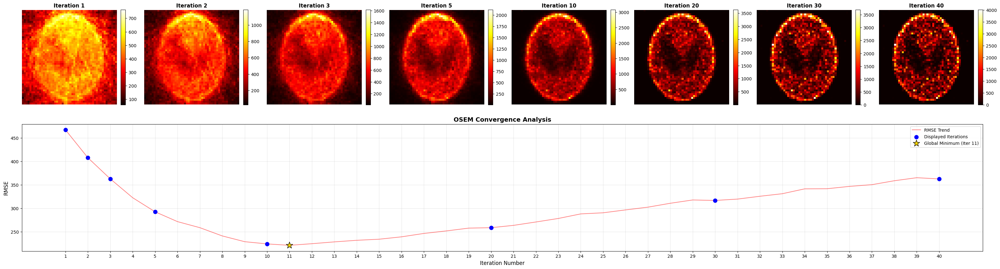

In [6]:
# --- Simulation Execution and Reconstruction Pipeline ---

# 1. Initialize the PET Simulation Environment
# Configuration based on thesis-level resolution and noise stress-testing
pet = PET(
    B_SQRT=50,       # Image resolution (50x50 pixels)
    D=150,           # Number of detectors
    beta=0.8,        # Attenuation coefficient (High attenuation regime)
    tau=1e-9,        # Coincidence timing window (Controls random noise floor)
    T=1,             # Total scan time (seconds)
    f_factor=1e6     # Activity scaling factor (Total count intensity)
)

# 2. Run the Forward Model
# Generates the ground truth phantom and simulates measured counts (n_star)
# including attenuation, randoms, and Poisson noise.
pet.run_simulation_with_randoms()

# 3. Execute Baseline OSEM Reconstruction
# This will populate self.osem_iters_history and self.osem_mse_hist for convergence analysis.
# Note: n_iters is set high to demonstrate the noise divergence phenomenon.
f_osem_final = pet.reconstruct_osem(n_iters=4, n_subsets=10)

# 4. Visualize the Reconstruction Evolution
# Displays spatial images at specific iterations to highlight the trade-off
# between resolution recovery and noise amplification (early stopping analysis).
pet.plot_osem_evolution(iters_to_show=[1, 2, 3, 5, 11, 20, 30, 40])

True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.


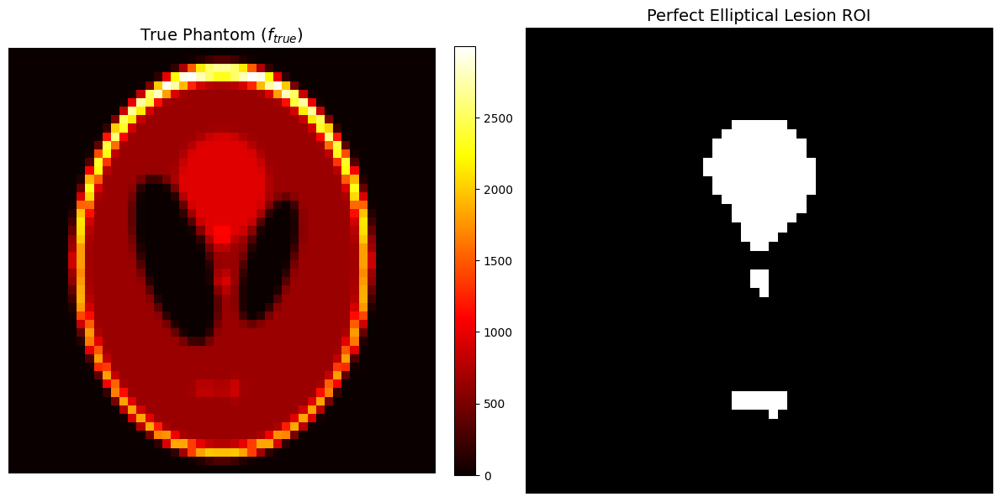

Saved perfect ROI visualization to roi_mask_visualization.png


In [43]:
pet = PET(
    B_SQRT=50,
    D=150,
    beta=0.8,
    tau=1e-9,
    T=1,
    f_factor=1e6
)

# --- ROI Mask Generation and Visualization ---

def plot_and_save_elliptical_roi(f_true, save_path="roi_mask_visualization.png"):
    """
    Generates a high-fidelity lesion ROI mask by combining spatial elliptical
    constraints with intensity-based thresholding.

    This dual-criteria approach ensures that high-intensity voxels from the
    skull boundary are excluded, focusing the analysis strictly on the
    internal diagnostic lesions.

    Args:
        f_true (numpy.ndarray): The 2D ground truth phantom intensity matrix.
        save_path (str): File path to save the mask visualization. Defaults to "roi_mask_visualization.png".

    Returns:
        numpy.ndarray: A boolean 2D mask where True represents lesion voxels.
    """
    size = f_true.shape[0]

    # 1. Spatial Masking: Define an elliptical region centered in the phantom
    # The radii are tuned to capture the brain interior while avoiding the skull.
    y, x = np.ogrid[:size, :size]
    center_x, center_y = size / 2, size / 2

    radius_x = size * 0.25  # Narrower horizontal radius
    radius_y = size * 0.35  # Longer vertical radius

    # Ellipse equation: (x/a)^2 + (y/b)^2 <= 1
    spatial_mask = (((x - center_x) / radius_x)**2 + ((y - center_y) / radius_y)**2) <= 1

    # 2. Statistical Background Analysis:
    # Calculate the median intensity of brain tissue within the elliptical boundary.
    inner_pixels = f_true[spatial_mask]
    brain_bg = np.median(inner_pixels)

    # 3. Final Lesion Masking:
    # A voxel is considered part of the lesion ROI if it is:
    # a) Inside the spatial ellipse AND
    # b) At least 5% brighter than the brain background.
    lesion_mask = spatial_mask & (f_true > brain_bg * 1.05)

    # --- Visualization for Methodology Section ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Plot Original Phantom
    im0 = axes[0].imshow(f_true, cmap='hot', interpolation='nearest')
    axes[0].set_title('True Phantom ($f_{true}$)', fontsize=14)
    axes[0].axis('off')
    fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

    # Plot Resulting Binary Mask
    im1 = axes[1].imshow(lesion_mask, cmap='gray', interpolation='nearest')
    axes[1].set_title('Perfect Elliptical Lesion ROI', fontsize=14)
    axes[1].axis('off')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Saved perfect ROI visualization to {save_path}")

    return lesion_mask

# --- Execution ---

# Reshape the 1D phantom vector back to 2D for spatial analysis
f_true_2d = pet.f_true.reshape((pet.B_SQRT, pet.B_SQRT))
# Generate and save the lesion mask
exact_lesion_mask = plot_and_save_elliptical_roi(f_true_2d)

True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-07)...
Simulation Done. Randoms fraction: 56.06%


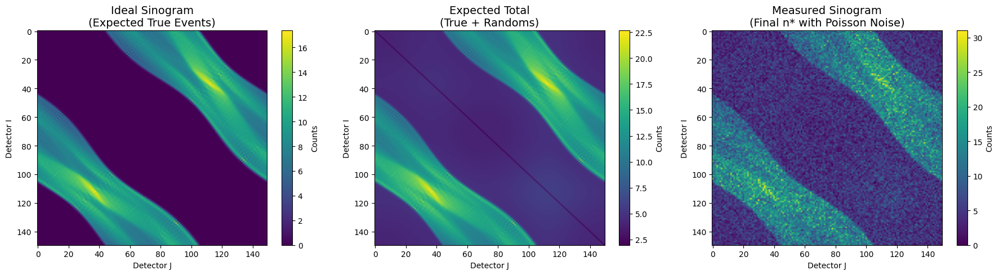

Forward modeling sinograms saved to forward_sinograms_demo.png
התמונה נוצרה ונשמרה בשם: forward_sinograms_demo.png


In [17]:
# --- 1. Simulation Initialization ---
# We use parameters corresponding to a high-noise scenario (e.g., Scenario 4)
# to clearly visualize the impact of random coincidences and Poisson noise.
pet_example = PET(
    B_SQRT=50,       # Full thesis resolution (50x50 pixels)
    D=150,           # Number of detectors (150-detector ring)
    beta=0.8,        # Attenuation coefficient (High attenuation regime)
    tau=5e-9,        # Coincidence timing window (Realistic high-noise setting)
    T=1,             # Total scan duration (seconds)
    f_factor=1e6     # Activity scaling (Total count intensity)
)

# --- 2. Forward Modeling Execution ---
# This step computes the expected photon counts (lambda) for each LOR
# and generates the noisy measurement vector (n_star) using Poisson sampling.
pet_example.run_simulation_with_randoms()

# --- 3. Visualization for the Methodology Section ---
# This method generates a three-panel comparative figure:
# 1. Ideal Sinogram (Clean signal)
# 2. Expected Total (Signal + Background Randoms)
# 3. Measured Sinogram (Final noisy data with Poisson variance)
pet_example.plot_forward_model_sinograms(save_path="forward_sinograms_demo.png")

print("[*] Forward modeling complete. Visualization saved as: forward_sinograms_demo.png")

# --- 4. Optional Next Steps: Reconstruction ---
# f_osem = pet_example.reconstruct_osem(n_iters=4, n_subsets=10)
# pet_example.plot_osem_evolution(iters_to_show=[1, 2, 3, 4])

Generating 6-scenario noise comparison and displaying to screen...
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.03%
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 0.13%
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.13%
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gib

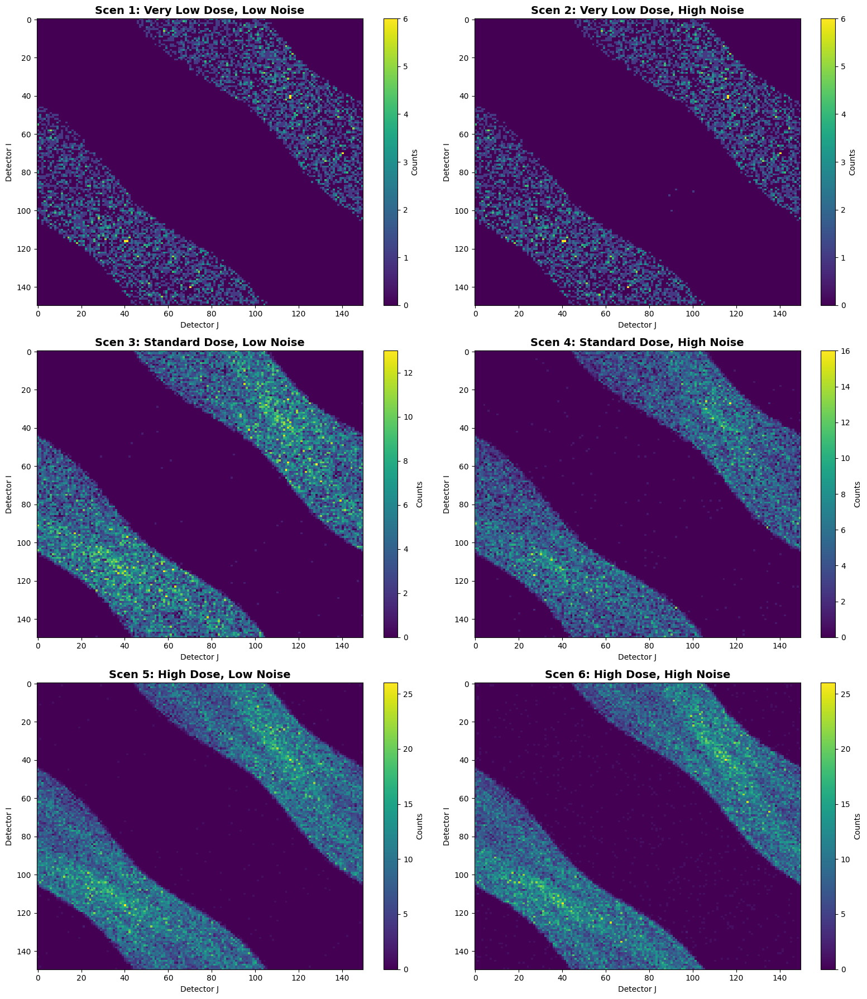

In [20]:
def plot_sinogram_noise_comparison_v2():
    """
    Generates a visual 6-panel comparison of PET sinograms to demonstrate the
    impact of activity levels (f_factor) and timing-window noise (tau).

    The function iterates through the 6 experimental scenarios defined in the thesis,
    running a localized forward simulation for each and displaying the resulting
    noisy measurement space (n_star) directly to the screen.
    """

    # Definition of the 6 experimental scenarios (Dose vs. Noise Floor)
    scenarios = [
        {"f": 1e5, "tau": 1e-9, "title": "Scen 1: Very Low Dose, Low Noise"},
        {"f": 1e5, "tau": 5e-9, "title": "Scen 2: Very Low Dose, High Noise"},
        {"f": 5e5, "tau": 1e-9, "title": "Scen 3: Standard Dose, Low Noise"},
        {"f": 5e5, "tau": 5e-9, "title": "Scen 4: Standard Dose, High Noise"},
        {"f": 1e6, "tau": 1e-9, "title": "Scen 5: High Dose, Low Noise"},
        {"f": 1e6, "tau": 5e-9, "title": "Scen 6: High Dose, High Noise"}
    ]

    # Setup a 3x2 grid layout for comparative analysis
    fig, axes = plt.subplots(3, 2, figsize=(16, 18))
    axes = axes.flatten()

    print("Generating 6-scenario noise comparison and displaying to screen...")

    for i, scen in enumerate(scenarios):
        # Initialize a temporary PET object for each specific noise/count configuration
        temp_pet = PET(B_SQRT=50, D=150, beta=0.8, tau=scen["tau"], f_factor=scen["f"], T=1)
        # Execute the forward model to generate the noisy measurement vector
        temp_pet.run_simulation_with_randoms()

        # Visualize the noisy measured sinogram (n_star)
        im = axes[i].imshow(temp_pet.n_star, cmap='viridis', aspect='auto')
        axes[i].set_title(scen["title"], fontsize=14, fontweight='bold')
        axes[i].set_xlabel("Detector J")
        axes[i].set_ylabel("Detector I")
        plt.colorbar(im, ax=axes[i], label='Counts')

    plt.tight_layout()
    # Display the final comparative grid to the screen
    plt.show()

# --- Execution ---
plot_sinogram_noise_comparison_v2()

# **OSEM Grid**


>>> Running Scenario 1/6
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.03%
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 1783.1816
Iteration 2/2 finished. Current MSE: 4247.4532
Starting OSEM: 2 iterations, 12 subsets...
Iteration 1/2 finished. Current MSE: 3495.6256
Iteration 2/2 finished. Current MSE: 7423.4474
Starting OSEM: 2 iterations, 16 subsets...
Iteration 1/2 finished. Current MSE: 4895.9358
Iteration 2/2 finished. Current MSE: 8514.1950
Scenario 1 Winner: (2, 8) (MSE: 1417.5347)


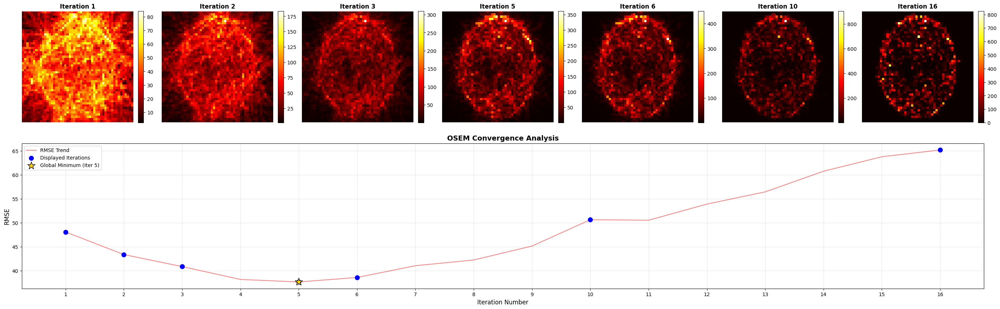


>>> Running Scenario 2/6
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 0.13%
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 1773.5821
Iteration 2/2 finished. Current MSE: 4232.3243
Starting OSEM: 2 iterations, 12 subsets...
Iteration 1/2 finished. Current MSE: 3595.7310
Iteration 2/2 finished. Current MSE: 7632.8763
Starting OSEM: 2 iterations, 16 subsets...
Iteration 1/2 finished. Current MSE: 4984.9454
Iteration 2/2 finished. Current MSE: 8558.9023
Scenario 2 Winner: (2, 8) (MSE: 1412.9993)


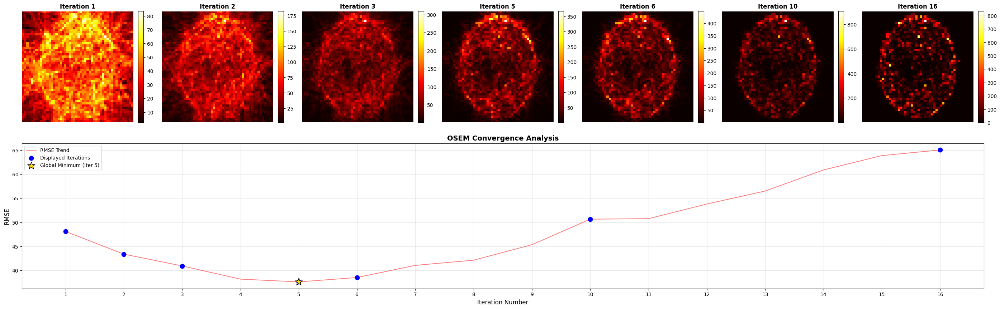


>>> Running Scenario 3/6
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.13%
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 16520.3576
Iteration 2/2 finished. Current MSE: 23618.8216
Starting OSEM: 2 iterations, 12 subsets...
Iteration 1/2 finished. Current MSE: 18581.5084
Iteration 2/2 finished. Current MSE: 37886.8576
Starting OSEM: 2 iterations, 16 subsets...
Iteration 1/2 finished. Current MSE: 25145.9623
Iteration 2/2 finished. Current MSE: 49913.0172
Scenario 3 Winner: (2, 8) (MSE: 16520.3576)


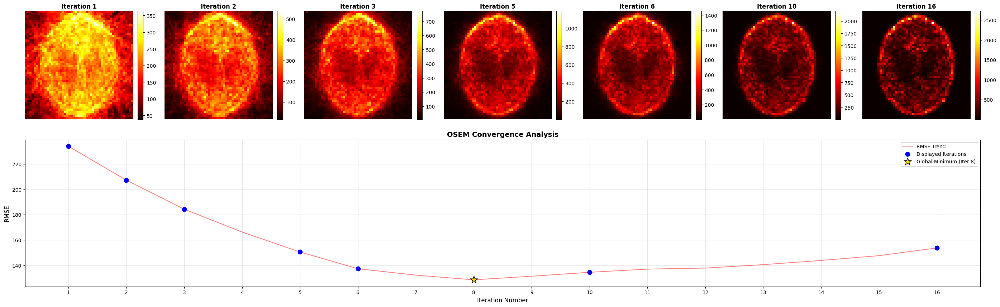


>>> Running Scenario 4/6
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 0.63%
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 17367.7144
Iteration 2/2 finished. Current MSE: 24348.1250
Starting OSEM: 2 iterations, 12 subsets...
Iteration 1/2 finished. Current MSE: 19450.2881
Iteration 2/2 finished. Current MSE: 37956.0180
Starting OSEM: 2 iterations, 16 subsets...
Iteration 1/2 finished. Current MSE: 26906.1059
Iteration 2/2 finished. Current MSE: 54078.1257
Scenario 4 Winner: (2, 8) (MSE: 17252.6933)


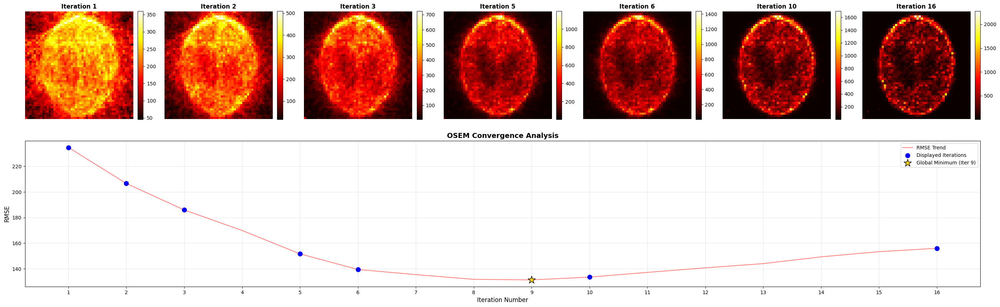


>>> Running Scenario 5/6
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.25%
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 55978.6548
Iteration 2/2 finished. Current MSE: 54797.7087
Starting OSEM: 2 iterations, 12 subsets...
Iteration 1/2 finished. Current MSE: 48283.3633
Iteration 2/2 finished. Current MSE: 81292.1222
Starting OSEM: 2 iterations, 16 subsets...
Iteration 1/2 finished. Current MSE: 55404.6762
Iteration 2/2 finished. Current MSE: 105154.0270
Scenario 5 Winner: (2, 12) (MSE: 48283.3633)


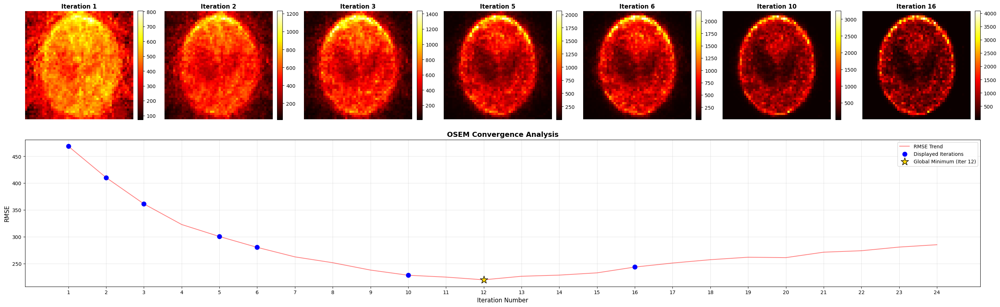


>>> Running Scenario 6/6
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 1.26%
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 53837.2409
Iteration 2/2 finished. Current MSE: 55050.4223
Starting OSEM: 2 iterations, 12 subsets...
Iteration 1/2 finished. Current MSE: 49808.2784
Iteration 2/2 finished. Current MSE: 84028.9101
Starting OSEM: 2 iterations, 16 subsets...
Iteration 1/2 finished. Current MSE: 57738.6421
Iteration 2/2 finished. Current MSE: 110870.0510
Scenario 6 Winner: (2, 8) (MSE: 49750.7738)


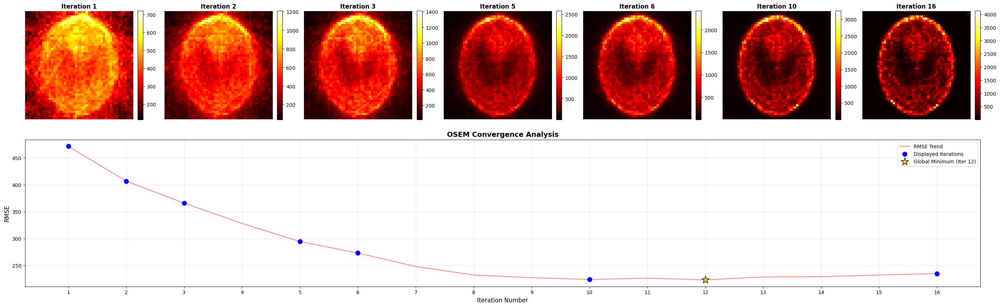

In [21]:
# --- 1. Physics Configuration & Scenario Generation ---
# Define the parameter grid that forms the 6 experimental scenarios
physics_config = {
    "B_SQRT": [50],
    "D": [150],
    "f_factor": [1e5, 5e5, 1e6], # Three levels of signal activity (Low, Med, High)
    "tau": [1e-9, 5e-9],        # Two levels of noise floor (Low, High)
    "beta": [0.8]               # Constant attenuation coefficient
}

def generate_grid(params_dict):
    """Generates a list of all parameter combinations (Scenarios)."""
    keys, values = zip(*params_dict.items())
    return [dict(zip(keys, combo)) for combo in itertools.product(*values)]

scenarios = generate_grid(physics_config)
output_dir = "thesis_results"
os.makedirs(output_dir, exist_ok=True)

# --- 2. Central Experimental Loop ---
for i, phys in enumerate(scenarios):
    print(f"\n>>> Running Scenario {i+1}/6")

    # Initialize a new PET object for each scenario to ensure clean state
    pet = PET(B_SQRT=phys["B_SQRT"],
              D=phys["D"],
              beta=phys["beta"],
              tau=phys["tau"],
              f_factor=phys["f_factor"])

    # Generate the forward model data (sinogram) for the current physics
    pet.run_simulation_with_randoms()

    best_mse_in_scenario = float('inf')
    best_data = {}

    # --- 3. Hyperparameter Optimization (Grid Search for OSEM) ---
    # We test different iteration/subset combinations to find the baseline
    # that achieves the lowest possible MSE for this specific scenario.
    for it in [2]: # Total full iterations
        for sub in [8, 12, 16]: # Subset counts
            # Execute reconstruction
            pet.reconstruct_osem(n_iters=it, n_subsets=sub)

            # Track the minimum MSE achieved during this specific run
            current_min = np.min(pet.osem_mse_hist)
            if current_min < best_mse_in_scenario:
                best_mse_in_scenario = current_min
                # Store the results of the winning hyperparameter set
                best_data = {
                    "history_imgs": pet.osem_iters_history.copy(),
                    "history_mse": pet.osem_mse_hist.copy(),
                    "params": (it, sub)
                }

    # --- 4. Result Logging and Visualization ---
    # Restore the best history to the object for plotting
    pet.osem_iters_history = best_data["history_imgs"]
    pet.osem_mse_hist = best_data["history_mse"]

    print(f"Scenario {i+1} Optimal Configuration: {best_data['params']}")
    print(f"Minimum MSE achieved: {best_mse_in_scenario:.4f}")

    # Save the convergence analysis and reconstruction evolution
    pet.plot_osem_evolution(iters_to_show=[1, 2, 3, 5, 8, 12, 16],
                            save_prefix=f"{output_dir}/Scen_{i+1}")

# **BSREM** **Grid**


 OPTIMIZING BSREM ONLY | SCENARIO 1: f_factor=1e+05, tau=1.0e-09
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.03%
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/30 | MSE: 25249.0405
BSREM Iter 6/30 | MSE: 76917.5981
BSREM Iter 11/30 | MSE: 83278.9925
BSREM Iter 16/30 | MSE: 85250.7379
BSREM Iter 21/30 | MSE: 86109.2269
BSREM Iter 26/30 | MSE: 86557.0428
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 40 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/40 | MSE: 25754.0703
BSREM Iter 6/40 | MSE: 78948.8986
BSREM Iter 11/40 | MSE: 86655.2360
BSREM Iter 16/40 | MSE: 88947.3834
BSREM Iter 21/40 | MSE: 89899.7235
BSREM Iter 26/40 | MSE: 90385.7762
BSREM Iter 31/40 | MSE: 90670.11

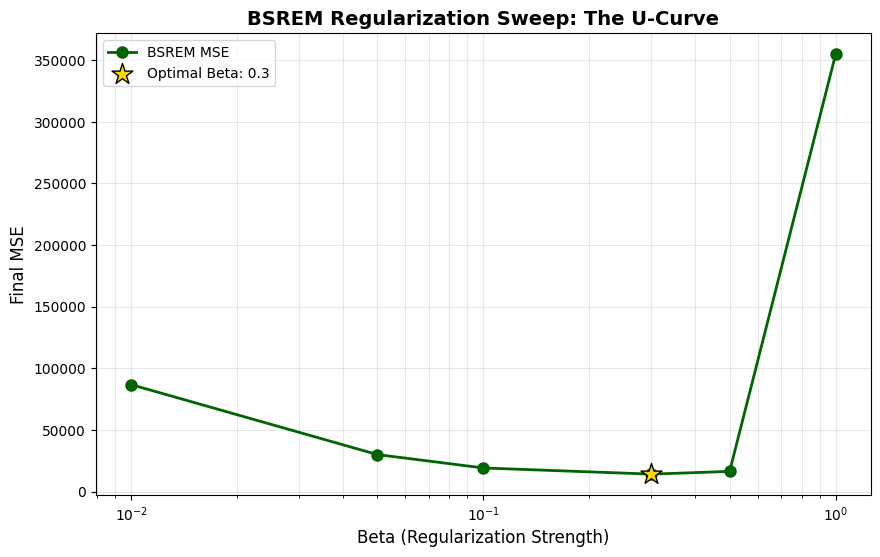

No OSEM history found. Run reconstruct_osem first.

[RESULTS SCENARIO 1]
Optimal Beta:    0.3
Optimal Subsets: 10
Optimal Iters:   30
Minimum MSE:     14132.294010

 OPTIMIZING BSREM ONLY | SCENARIO 2: f_factor=1e+05, tau=5.0e-09
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 0.13%
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/30 | MSE: 25365.0725
BSREM Iter 6/30 | MSE: 75867.9114
BSREM Iter 11/30 | MSE: 82306.2894
BSREM Iter 16/30 | MSE: 84289.4922
BSREM Iter 21/30 | MSE: 85148.5884
BSREM Iter 26/30 | MSE: 85602.8493
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 40 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/40 | MSE: 25763.5175
BSREM Iter 6/40 | MSE: 77667.1463
BSREM It

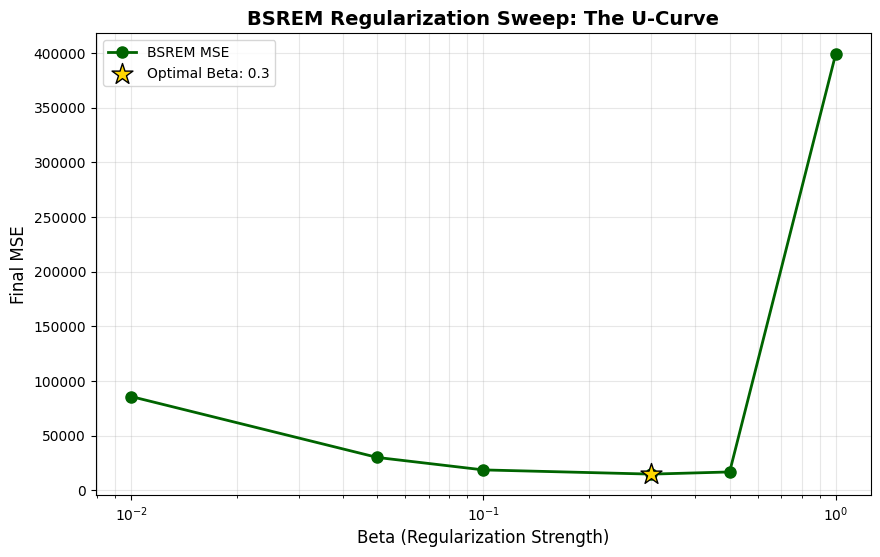

No OSEM history found. Run reconstruct_osem first.

[RESULTS SCENARIO 2]
Optimal Beta:    0.3
Optimal Subsets: 10
Optimal Iters:   30
Minimum MSE:     14869.788945

 OPTIMIZING BSREM ONLY | SCENARIO 3: f_factor=5e+05, tau=1.0e-09
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.13%
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/30 | MSE: 165814.1226
BSREM Iter 6/30 | MSE: 325532.3171
BSREM Iter 11/30 | MSE: 361389.1684
BSREM Iter 16/30 | MSE: 371991.2667
BSREM Iter 21/30 | MSE: 376445.7577
BSREM Iter 26/30 | MSE: 378741.3980
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 40 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/40 | MSE: 190798.4390
BSREM Iter 6/40 | MSE: 386719.9764


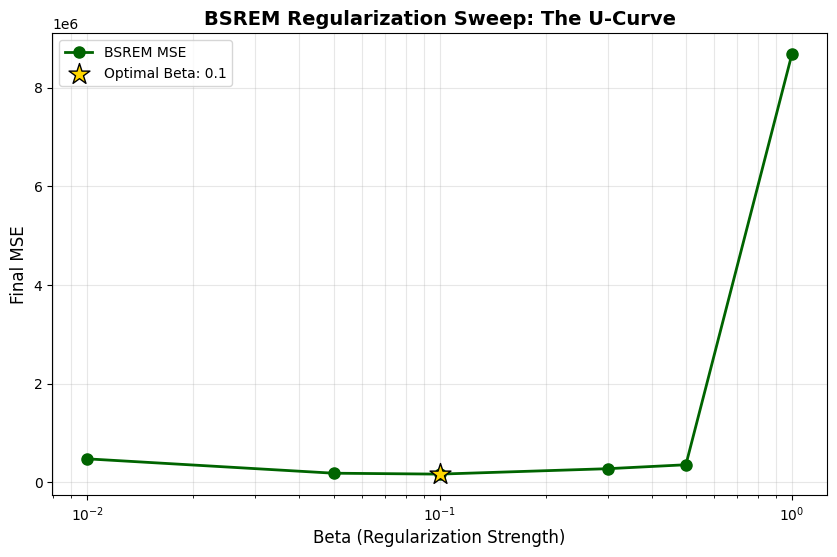

No OSEM history found. Run reconstruct_osem first.

[RESULTS SCENARIO 3]
Optimal Beta:    0.1
Optimal Subsets: 10
Optimal Iters:   50
Minimum MSE:     165395.468994

 OPTIMIZING BSREM ONLY | SCENARIO 4: f_factor=5e+05, tau=5.0e-09
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 0.63%
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/30 | MSE: 188454.0883
BSREM Iter 6/30 | MSE: 398691.2257
BSREM Iter 11/30 | MSE: 445271.5621
BSREM Iter 16/30 | MSE: 459029.4415
BSREM Iter 21/30 | MSE: 464542.3683
BSREM Iter 26/30 | MSE: 467270.9345
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 40 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/40 | MSE: 190351.8217
BSREM Iter 6/40 | MSE: 412382.8865

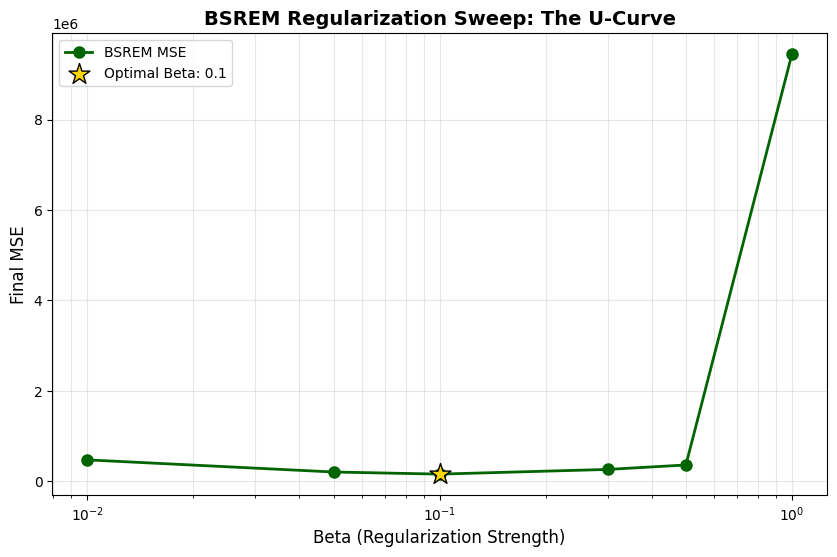

No OSEM history found. Run reconstruct_osem first.

[RESULTS SCENARIO 4]
Optimal Beta:    0.1
Optimal Subsets: 10
Optimal Iters:   50
Minimum MSE:     160931.402844

 OPTIMIZING BSREM ONLY | SCENARIO 5: f_factor=1e+06, tau=1.0e-09
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.25%
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/30 | MSE: 471552.5010
BSREM Iter 6/30 | MSE: 727362.1587
BSREM Iter 11/30 | MSE: 802735.0659
BSREM Iter 16/30 | MSE: 821112.2832
BSREM Iter 21/30 | MSE: 827695.4534
BSREM Iter 26/30 | MSE: 830720.2501
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 40 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/40 | MSE: 513615.9829
BSREM Iter 6/40 | MSE: 733627.873

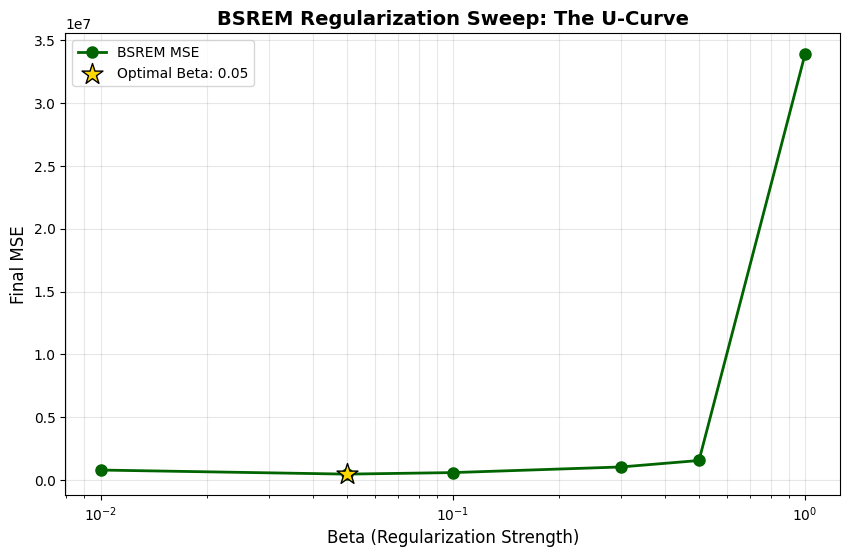

No OSEM history found. Run reconstruct_osem first.

[RESULTS SCENARIO 5]
Optimal Beta:    0.05
Optimal Subsets: 10
Optimal Iters:   50
Minimum MSE:     472422.068727

 OPTIMIZING BSREM ONLY | SCENARIO 6: f_factor=1e+06, tau=5.0e-09
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 1.25%
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/30 | MSE: 638251.5287
BSREM Iter 6/30 | MSE: 794352.5408
BSREM Iter 11/30 | MSE: 856742.4617
BSREM Iter 16/30 | MSE: 873348.4789
BSREM Iter 21/30 | MSE: 879471.4190
BSREM Iter 26/30 | MSE: 882318.2133
Starting Auto-Scaled BSREM: Beta=0.01, Gamma=2.0, 40 iters...
  -> Effective Beta (scaled): 8.00e-05
BSREM Iter 1/40 | MSE: 623066.9213
BSREM Iter 6/40 | MSE: 849358.35

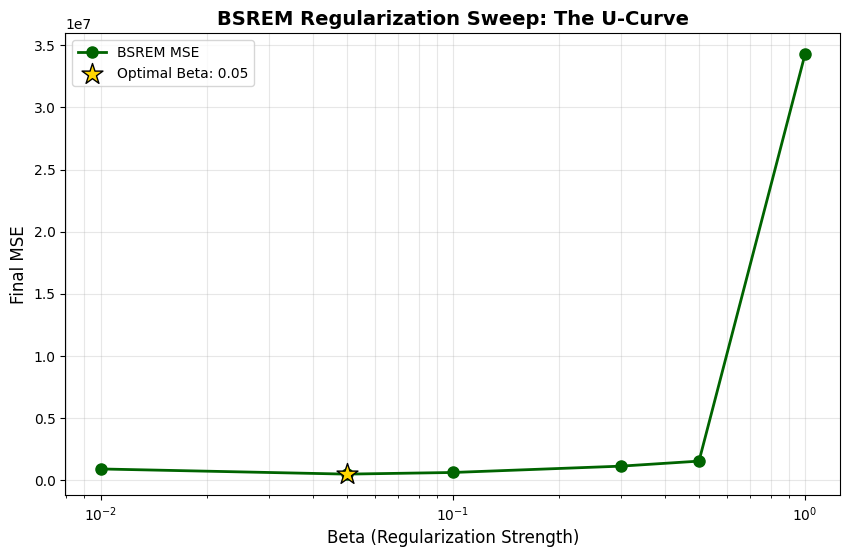

No OSEM history found. Run reconstruct_osem first.

[RESULTS SCENARIO 6]
Optimal Beta:    0.05
Optimal Subsets: 10
Optimal Iters:   50
Minimum MSE:     486393.042506

████████████████████████████████████████████████████████████████████████████████
       MASTER BSREM PARAMETERS SUMMARY
████████████████████████████████████████████████████████████████████████████████
 Scenario  f_factor          tau  Best_Beta  Best_Subsets  Best_Iters       Min_MSE
        1  100000.0 1.000000e-09       0.30            10          30  14132.294010
        2  100000.0 5.000000e-09       0.30            10          30  14869.788945
        3  500000.0 1.000000e-09       0.10            10          50 165395.468994
        4  500000.0 5.000000e-09       0.10            10          50 160931.402844
        5 1000000.0 1.000000e-09       0.05            10          50 472422.068727
        6 1000000.0 5.000000e-09       0.05            10          50 486393.042506


In [27]:
def plot_bsrem_u_curve(beta_results, best_beta, save_prefix):
    """
    Visualizes the Mean Squared Error (MSE) as a function of the regularization
    parameter (Beta) to demonstrate the Bias-Variance tradeoff.

    In PET reconstruction, this typically forms a 'U-Curve' where the minimum
    represents the optimal balance between noise suppression and structural preservation.
    """
    df_beta = pd.DataFrame(beta_results)
    # Sorting values to ensure a smooth line plot for the sweep
    df_beta = df_beta.sort_values('beta')

    plt.figure(figsize=(10, 6))
    plt.plot(df_beta['beta'], df_beta['mse'], marker='o', linestyle='-',
             color='darkgreen', linewidth=2, markersize=8, label='BSREM MSE')

    # Highlight the optimal beta identified by the Grid Search
    opt_mse = df_beta[df_beta['beta'] == best_beta]['mse'].values[0]
    plt.scatter(best_beta, opt_mse, color='gold', s=250, marker='*',
                edgecolors='black', zorder=5, label=f'Optimal Beta: {best_beta}')

    # Regularization parameters are traditionally scanned on a logarithmic scale
    plt.xscale('log')
    plt.title('BSREM Regularization Sweep: The U-Curve Analysis', fontsize=14, fontweight='bold')
    plt.xlabel('Beta (Regularization Strength)', fontsize=12)
    plt.ylabel('Final MSE', fontsize=12)
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()

    if save_prefix:
        plt.savefig(f"{save_prefix}_bsrem_u_curve.png", bbox_inches='tight', dpi=150)
    plt.show()

# ==============================================================================
# 1. EXPERIMENTAL CONFIGURATION & HYPERPARAMETER GRID
# ==============================================================================

# Physical scenarios as defined in the thesis methodology
physics_config = {
    "B_SQRT": [50],                  # Image resolution
    "D": [150],                      # Number of detectors
    "f_factor": [1e5, 5e5, 1e6],     # Signal activity levels
    "tau": [1e-9, 5e-9],             # Timing window noise levels
    "beta": [0.8]                    # Attenuation factor
}

# Grid Search parameters for the BSREM algorithm
bsrem_param_grid = {
    "subsets": [10, 15, 20],                   # Subset count for update stability
    "betas": [0.01, 0.05, 0.1, 0.3, 0.5, 1.0], # Regularization strength sweep
    "iters": [30, 40, 50]                      # Convergence depth testing
}

# Generate all 6 physical scenarios
scenarios = generate_grid(physics_config)
output_dir = "thesis_results"
os.makedirs(output_dir, exist_ok=True)

bsrem_final_report = []

# ==============================================================================
# 2. MAIN OPTIMIZATION LOOP
# ==============================================================================

for i, phys in enumerate(scenarios):
    print(f"\n" + "="*60)
    print(f" OPTIMIZING BSREM | SCENARIO {i+1}: f={phys['f_factor']:.0e}, tau={phys['tau']:.1e}")
    print("="*60)

    # Initialize the PET simulation for the current scenario
    pet = PET(B_SQRT=phys["B_SQRT"], D=phys["D"],
              beta=phys["beta"], tau=phys["tau"], f_factor=phys["f_factor"])
    pet.run_simulation_with_randoms()
    prefix = f"{output_dir}/Scen_{i+1}_BSREM"

    best_bsrem_mse = float('inf')
    best_bsrem_run = {}
    u_curve_log = []

    # --- Systematic Grid Search over BSREM Hyperparameters ---
    for n_sub in bsrem_param_grid["subsets"]:
        for b in bsrem_param_grid["betas"]:
            for n_it in bsrem_param_grid["iters"]:

                # Execute reconstruction with Auto-Scaling BSREM
                f_final = pet.reconstruct_bsrem(n_iters=n_it, n_subsets=n_sub, beta=b, gamma=2.0)
                final_mse = pet.bsrem_mse_hist[-1]

                # Log metrics for U-Curve visualization
                u_curve_log.append({'beta': b, 'mse': final_mse, 'subsets': n_sub, 'iters': n_it})

                # Update best-performing parameters for this scenario
                if final_mse < best_bsrem_mse:
                    best_bsrem_mse = final_mse
                    best_bsrem_run = {
                        "params": {"beta": b, "subsets": n_sub, "iters": n_it},
                        "mse": final_mse,
                        "history_mse": pet.bsrem_mse_hist.copy(),
                        "history_imgs": pet.bsrem_iters_history.copy()
                    }

    # --- Result Synthesis & Plotting ---
    win_p = best_bsrem_run["params"]

    # 1. Generate U-Curve (Filtered by winning subset and iteration counts)
    filtered_u = [d for d in u_curve_log if d['subsets'] == win_p['subsets'] and d['iters'] == win_p['iters']]
    plot_bsrem_u_curve(filtered_u, win_p['beta'], prefix)

    # 2. Visualize optimal reconstruction evolution
    pet.bsrem_iters_history = best_bsrem_run["history_imgs"]
    pet.bsrem_mse_hist = best_bsrem_run["history_mse"]
    pet.plot_osem_evolution(save_prefix=f"{prefix}_Conv")

    # --- Scenario Summary Console Output ---
    print(f"\n[RESULTS SCENARIO {i+1}]")
    print(f"Optimal Beta:    {win_p['beta']}")
    print(f"Optimal Subsets: {win_p['subsets']}")
    print(f"Optimal Iters:   {win_p['iters']}")
    print(f"Minimum MSE:     {best_bsrem_mse:.6f}")

    # Append data for the master summary table
    bsrem_final_report.append({
        "Scenario": i + 1,
        "f_factor": phys['f_factor'],
        "tau": phys['tau'],
        "Best_Beta": win_p['beta'],
        "Best_Subsets": win_p['subsets'],
        "Best_Iters": win_p['iters'],
        "Min_MSE": best_bsrem_mse
    })

# ==============================================================================
# 3. MASTER PARAMETER REPORT
# ==============================================================================
df_bsrem_master = pd.DataFrame(bsrem_final_report)
print("\n" + "█"*80)
print("       MASTER BSREM PARAMETERS SUMMARY (Optimized Results)")
print("█"*80)
print(df_bsrem_master.to_string(index=False))

# Export summary to CSV for thesis tables/results
df_bsrem_master.to_csv(f"{output_dir}/bsrem_optimized_params.csv", index=False)

# **Final Comparison**

--- Starting Final Production Run: 6 Scenarios ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 1/6 | f=1e+05 | tau=1.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.03%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 1783.1816
Iteration 2/2 finished. Current MSE: 4247.4532
[2/3] Running BSREM (Fixed: Beta=0.3, Subsets=10, Iters=30)
Starting Auto-Scaled BSREM: Beta=0.3, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 2.40e-03
BSREM Iter 1/30 | MSE: 1118.0612
BSREM Iter 6/30 | MSE: 1283.1072
BSREM Iter 11/30 | MSE: 1296.3552
BSREM Iter 16/30


--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_1

SUMMARY STATISTICS
OSEM   -> RMSE: 65.172488 | SNR: 0.27 dB
BSREM  -> RMSE: 36.089707 | SNR: 5.40 dB
Oracle -> RMSE: 39.997881 | SNR: 4.51 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  38.63%
Oracle RMSE Improvement over BSREM: -10.83%


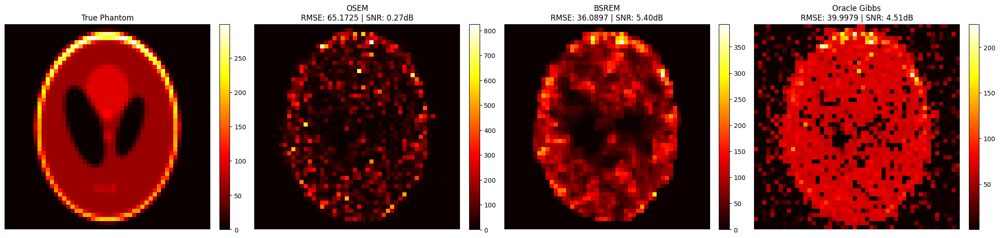

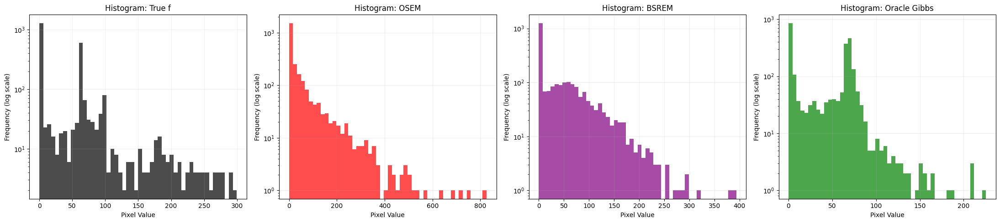

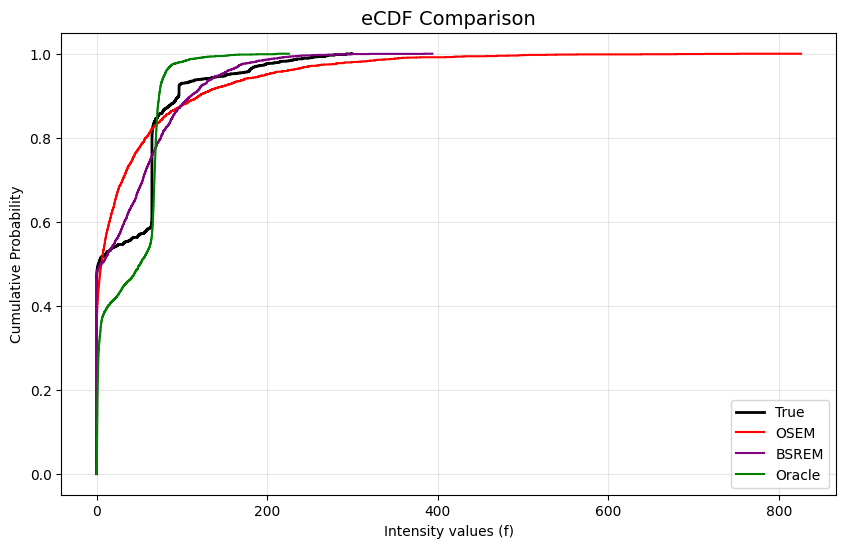

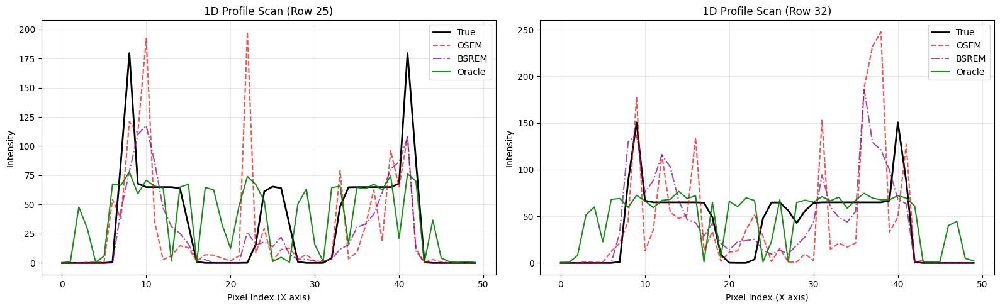

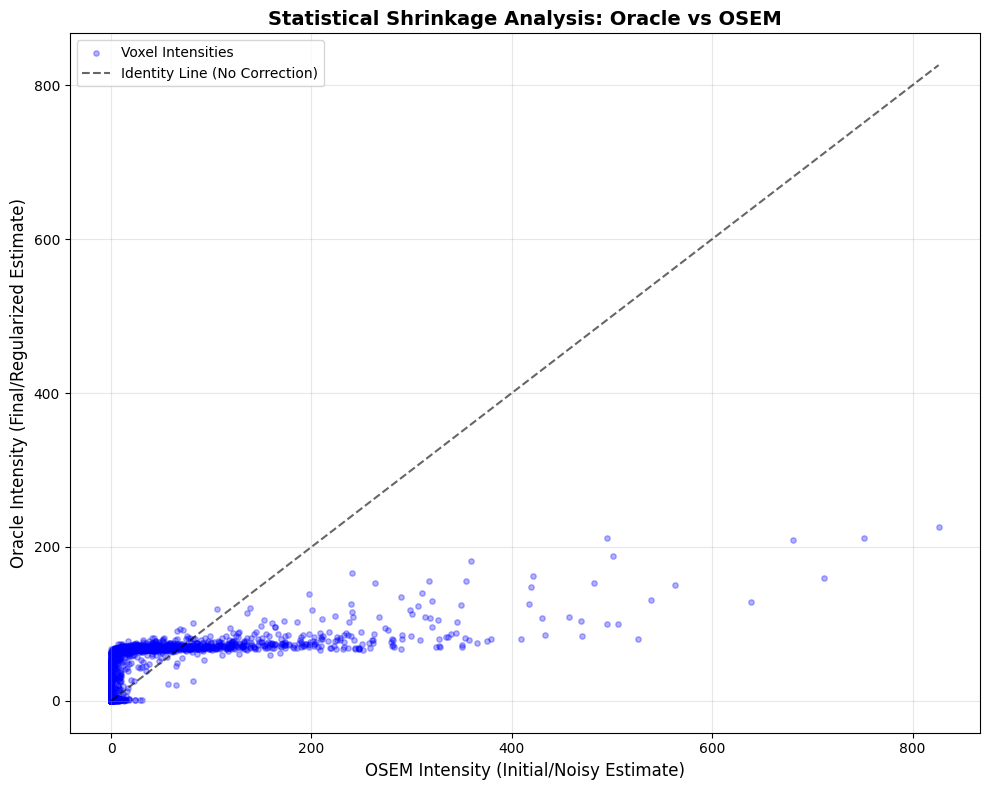

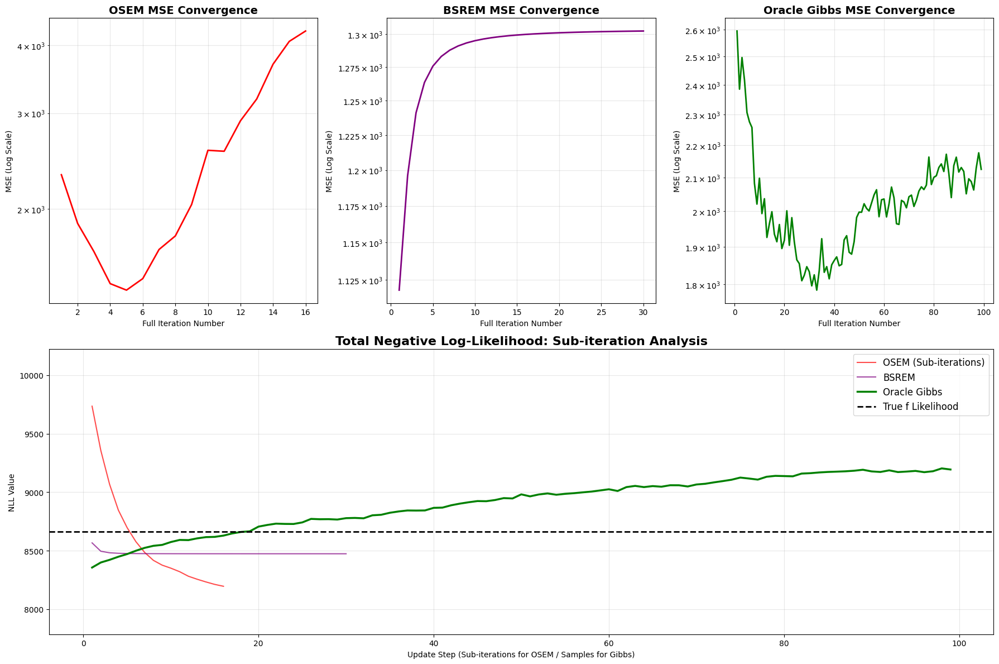


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 2/6 | f=1e+05 | tau=5.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 0.13%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 1773.5821
Iteration 2/2 finished. Current MSE: 4232.3243
[2/3] Running BSREM (Fixed: Beta=0.3, Subsets=10, Iters=30)
Starting Auto-Scaled BSREM: Beta=0.3, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 2.40e-03
BSREM Iter 1/30 | MSE: 1131.2672
BSREM Iter 6/30 | MSE: 1298.2106
BSREM Iter 11/30 | MSE: 1311.4419
BSREM Iter 16/30 | MSE: 1


--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_2

SUMMARY STATISTICS
OSEM   -> RMSE: 65.056316 | SNR: 0.29 dB
BSREM  -> RMSE: 36.296035 | SNR: 5.35 dB
Oracle -> RMSE: 40.118839 | SNR: 4.48 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  38.33%
Oracle RMSE Improvement over BSREM: -10.53%


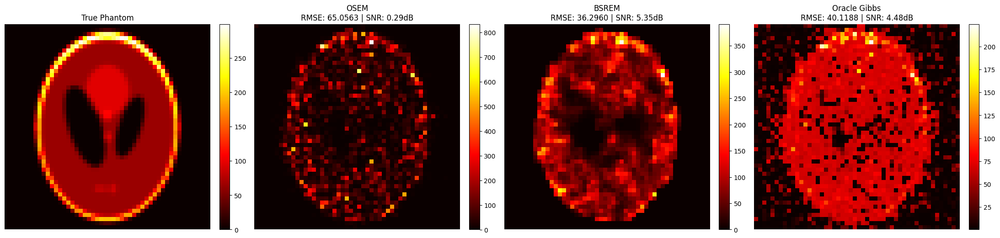

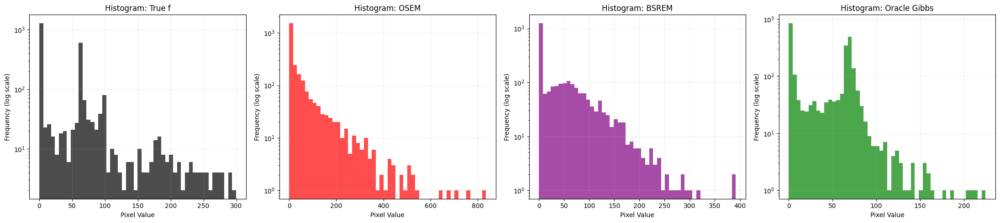

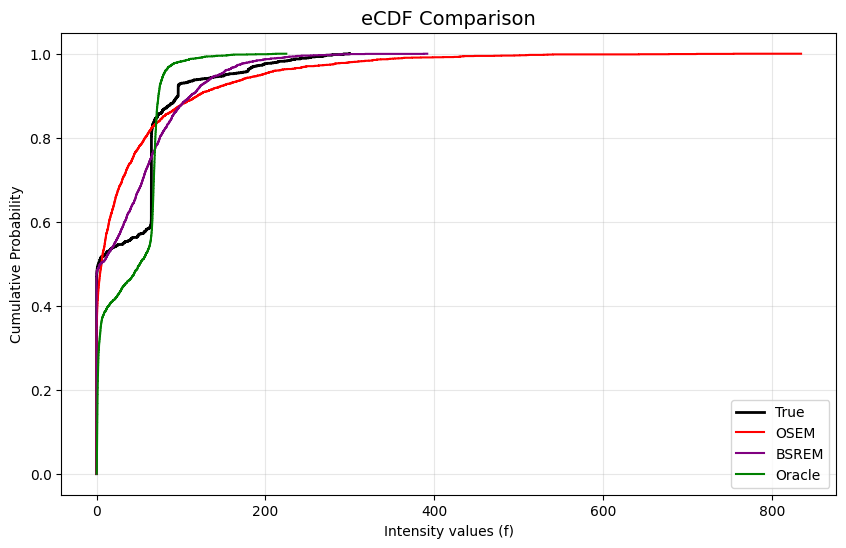

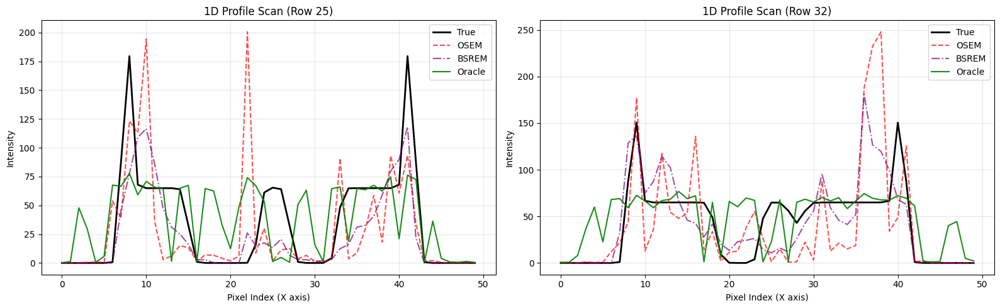

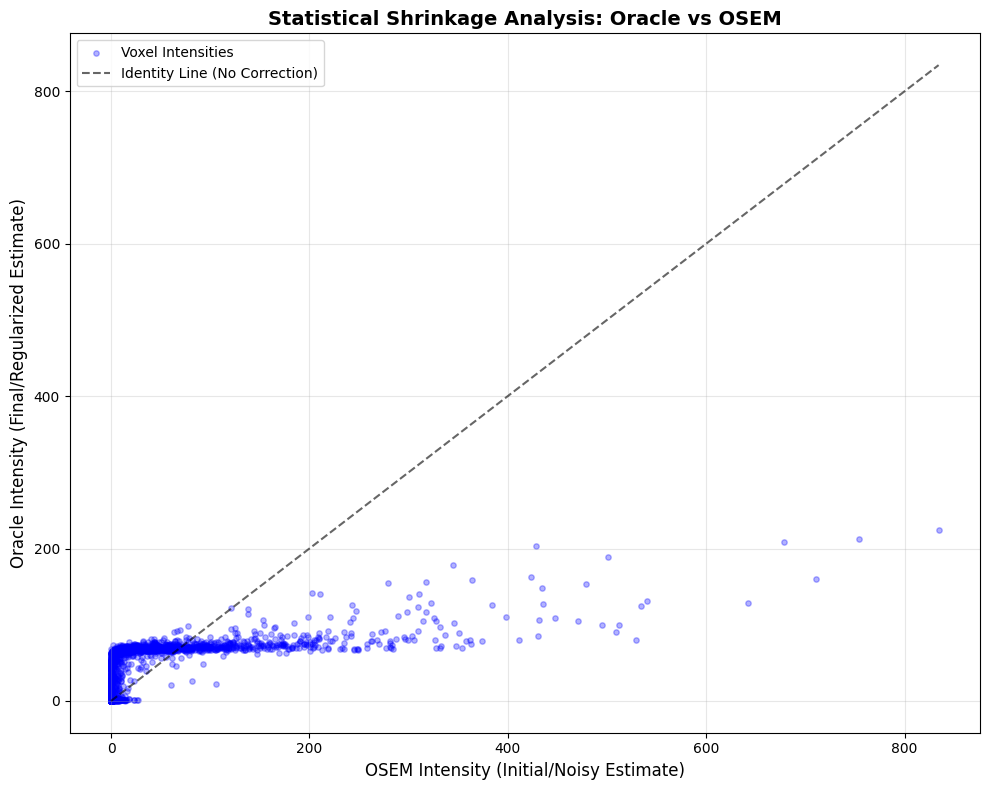

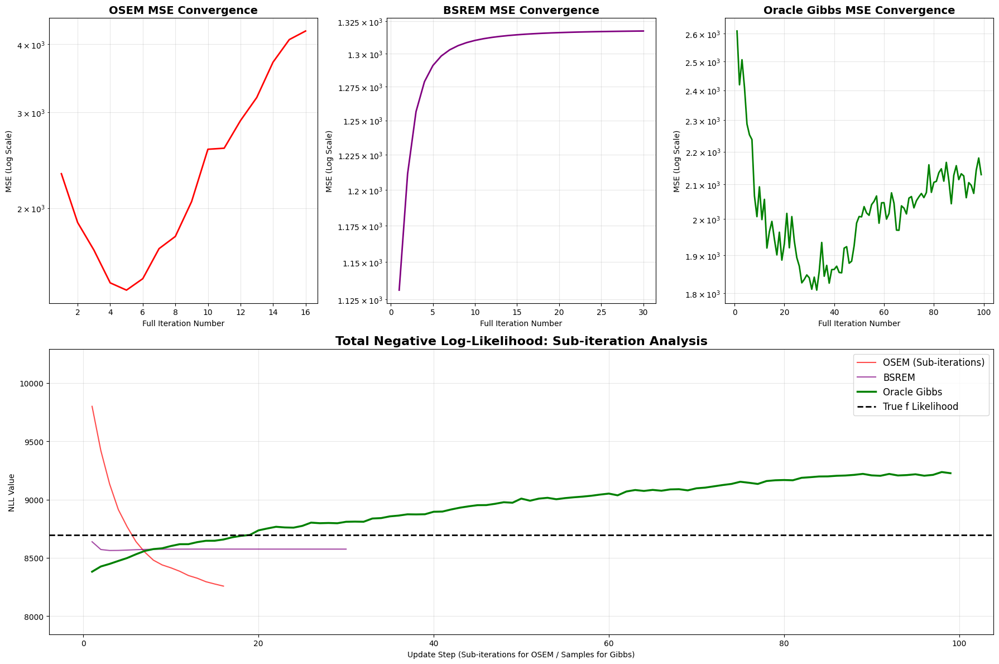


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 3/6 | f=5e+05 | tau=1.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.13%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 16520.3576
Iteration 2/2 finished. Current MSE: 23618.8216
[2/3] Running BSREM (Fixed: Beta=0.1, Subsets=10, Iters=50)
Starting Auto-Scaled BSREM: Beta=0.1, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 8.00e-04
BSREM Iter 1/50 | MSE: 14179.5850
BSREM Iter 6/50 | MSE: 15363.1467
BSREM Iter 11/50 | MSE: 15581.4558
BSREM Iter 16/50 | M


--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_3

SUMMARY STATISTICS
OSEM   -> RMSE: 153.684162 | SNR: 6.80 dB
BSREM  -> RMSE: 125.337060 | SNR: 8.57 dB
Oracle -> RMSE: 140.535248 | SNR: 7.58 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  8.56%
Oracle RMSE Improvement over BSREM: -12.13%


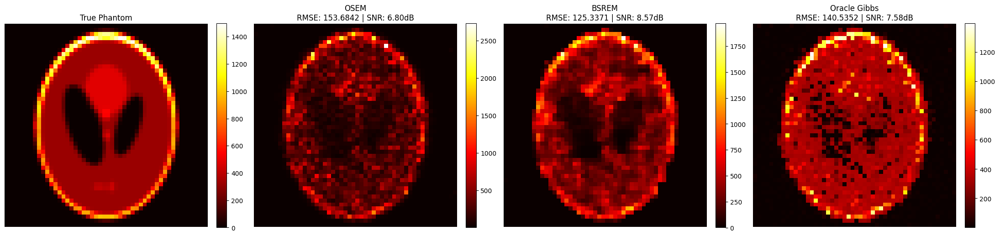

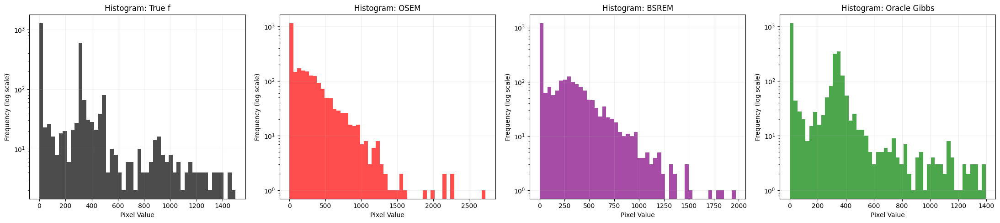

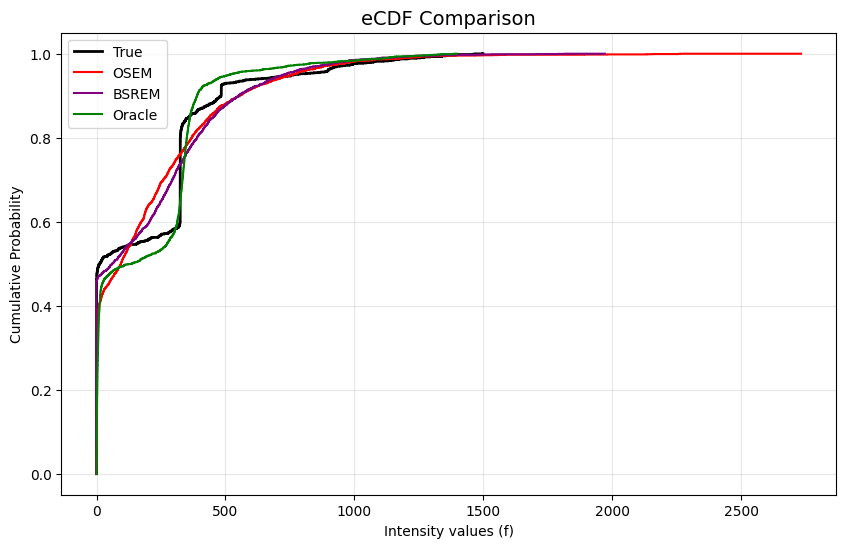

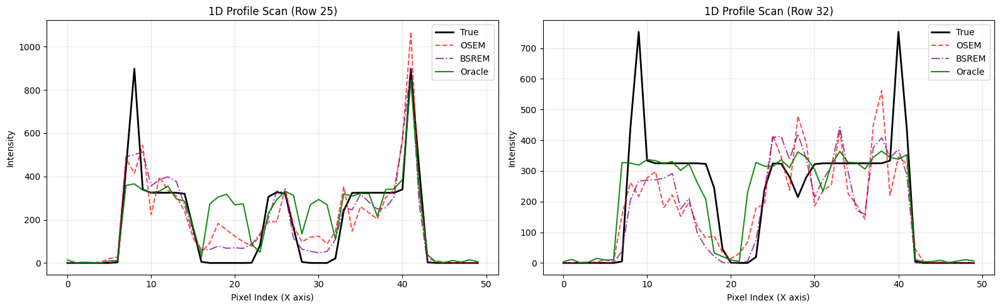

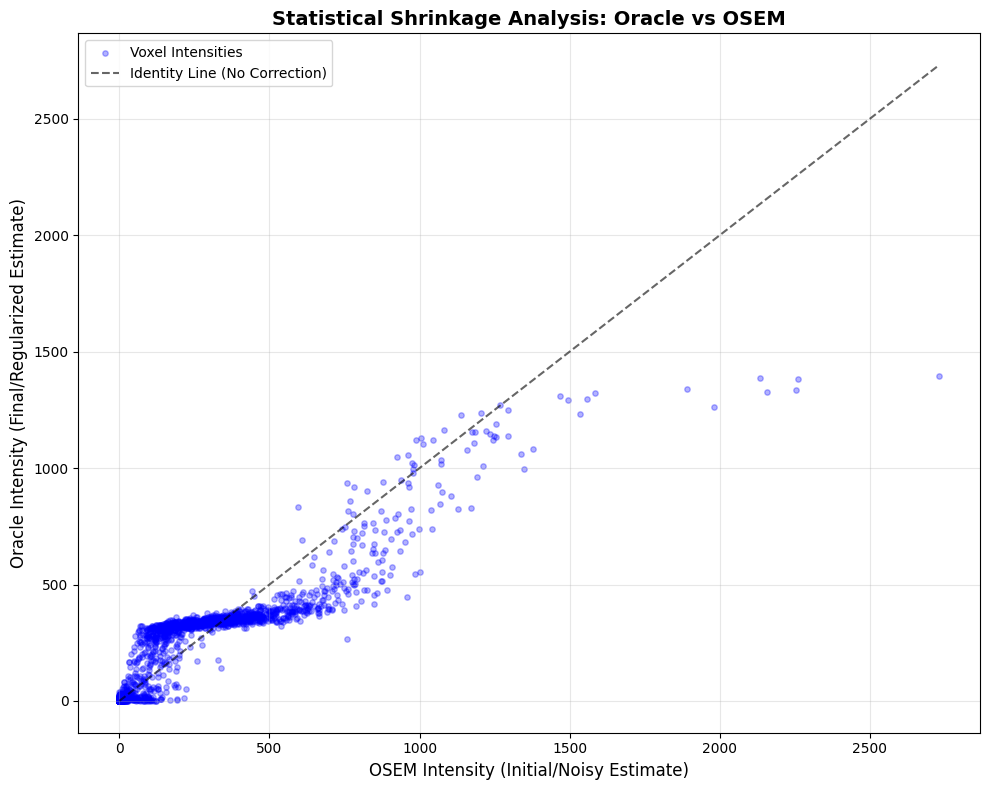

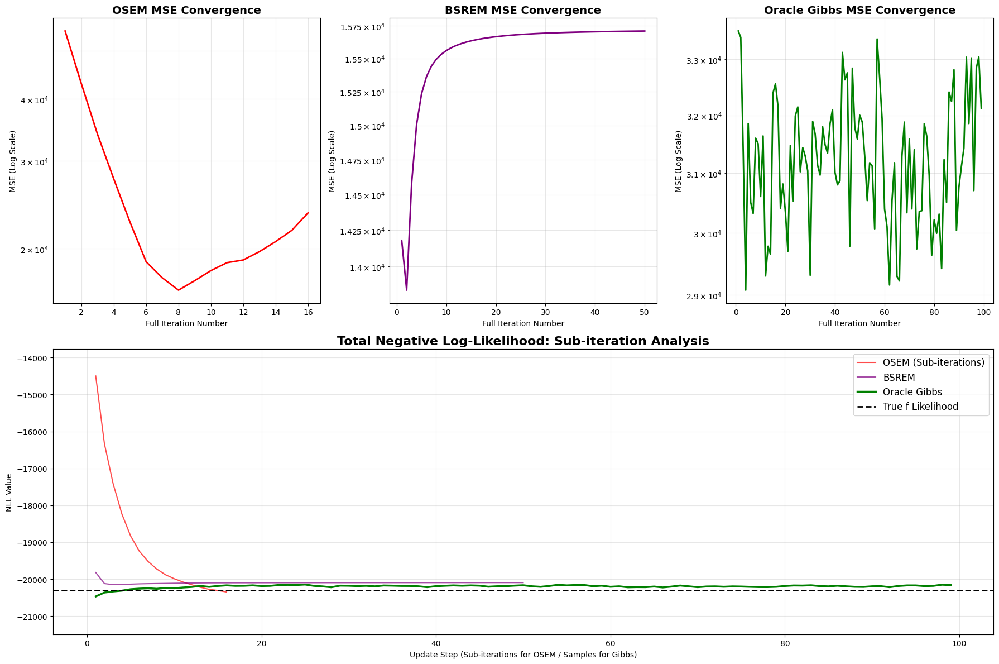


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 4/6 | f=5e+05 | tau=5.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 0.63%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 17367.7144
Iteration 2/2 finished. Current MSE: 24348.1250
[2/3] Running BSREM (Fixed: Beta=0.1, Subsets=10, Iters=50)
Starting Auto-Scaled BSREM: Beta=0.1, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 8.00e-04
BSREM Iter 1/50 | MSE: 15518.6536
BSREM Iter 6/50 | MSE: 16407.0735
BSREM Iter 11/50 | MSE: 16666.7034
BSREM Iter 16/50 | M


--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_4

SUMMARY STATISTICS
OSEM   -> RMSE: 156.038857 | SNR: 6.67 dB
BSREM  -> RMSE: 129.491873 | SNR: 8.29 dB
Oracle -> RMSE: 142.693762 | SNR: 7.44 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  8.55%
Oracle RMSE Improvement over BSREM: -10.20%


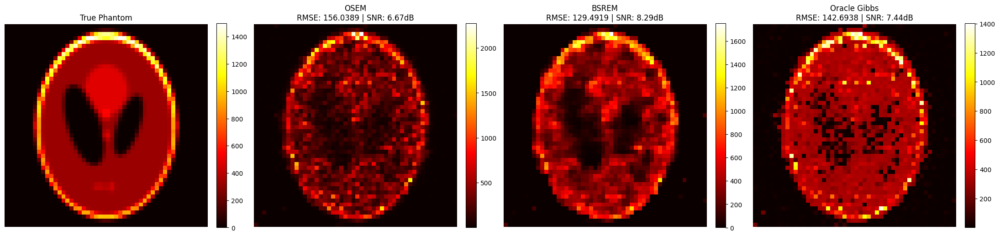

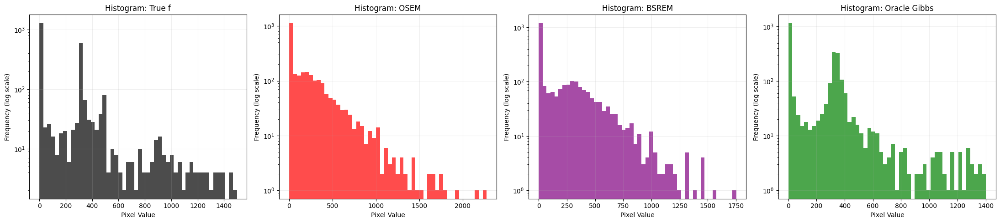

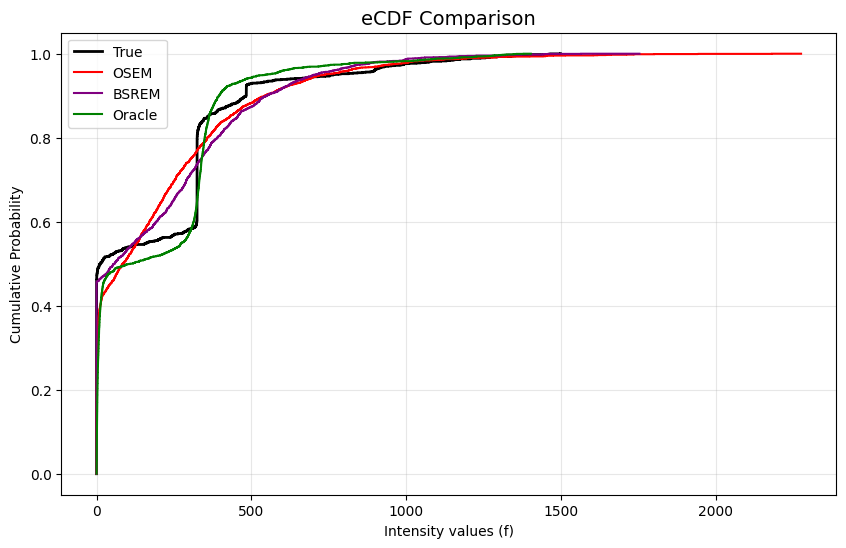

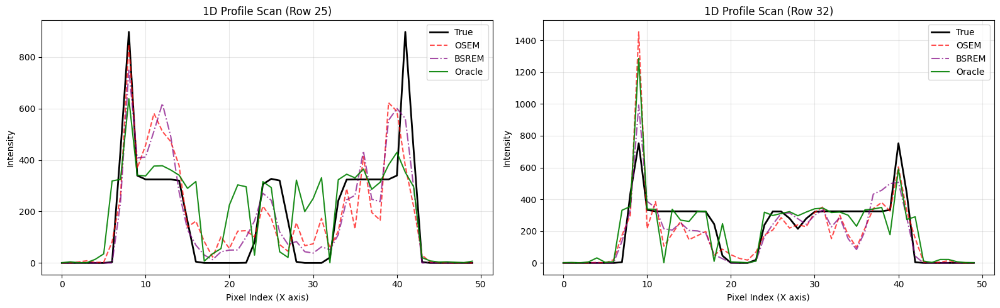

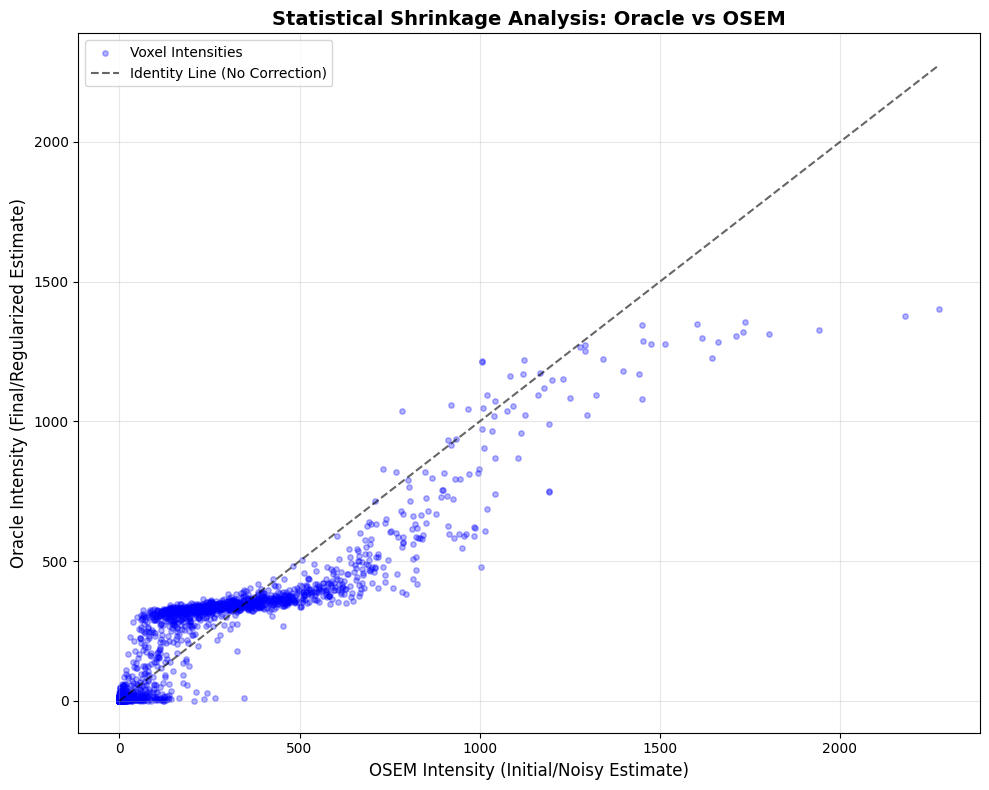

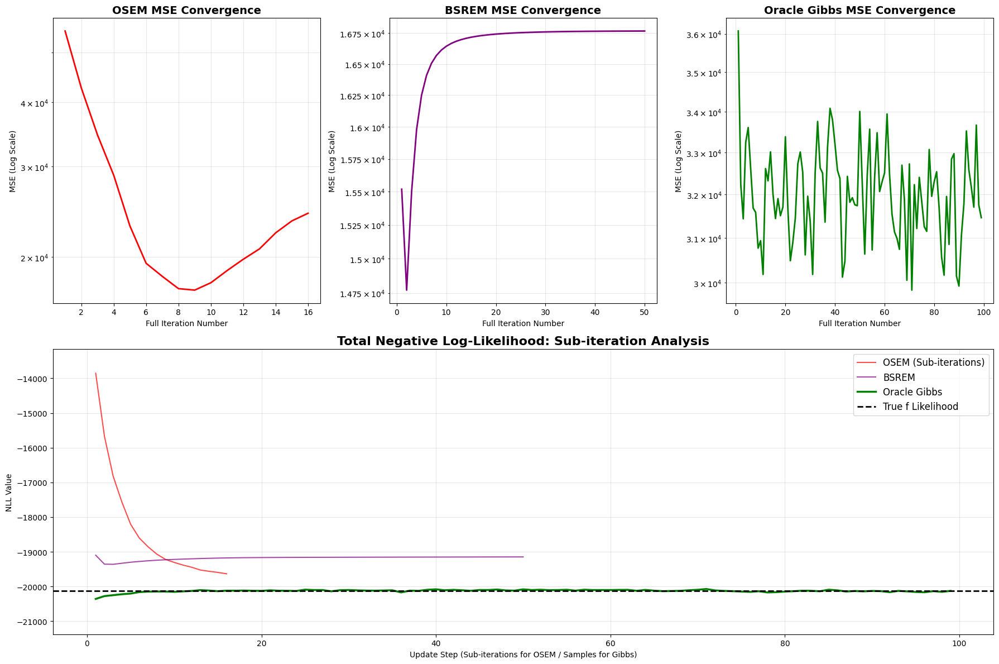


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 5/6 | f=1e+06 | tau=1.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.25%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 55978.6548
Iteration 2/2 finished. Current MSE: 54797.7087
[2/3] Running BSREM (Fixed: Beta=0.05, Subsets=10, Iters=50)
Starting Auto-Scaled BSREM: Beta=0.05, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 4.00e-04
BSREM Iter 1/50 | MSE: 47970.4161
BSREM Iter 6/50 | MSE: 53263.5413
BSREM Iter 11/50 | MSE: 55559.1560
BSREM Iter 16/50 


--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_5

SUMMARY STATISTICS
OSEM   -> RMSE: 234.089104 | SNR: 9.16 dB
BSREM  -> RMSE: 237.879407 | SNR: 9.02 dB
Oracle -> RMSE: 271.226843 | SNR: 7.88 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  -15.86%
Oracle RMSE Improvement over BSREM: -14.02%


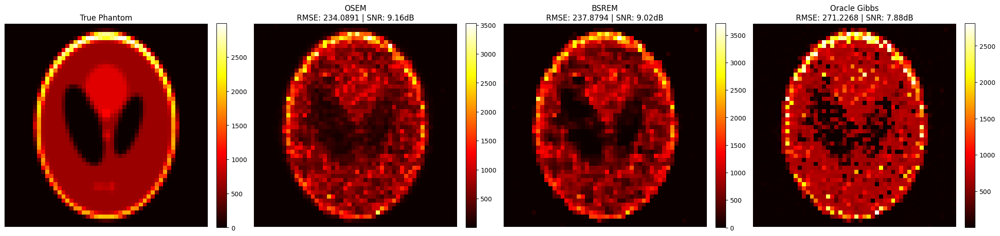

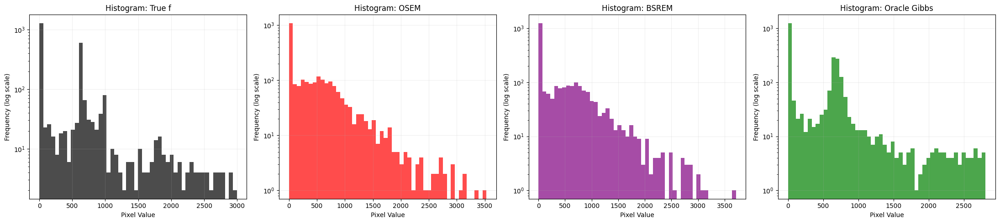

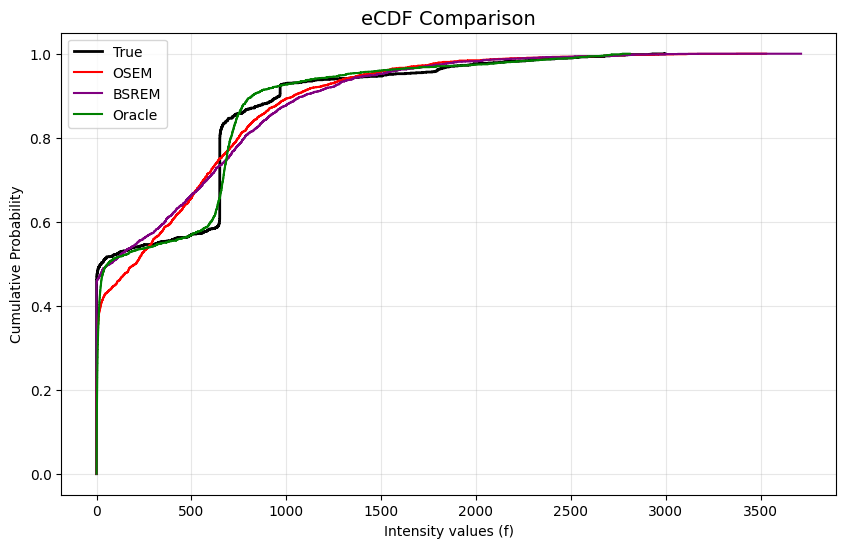

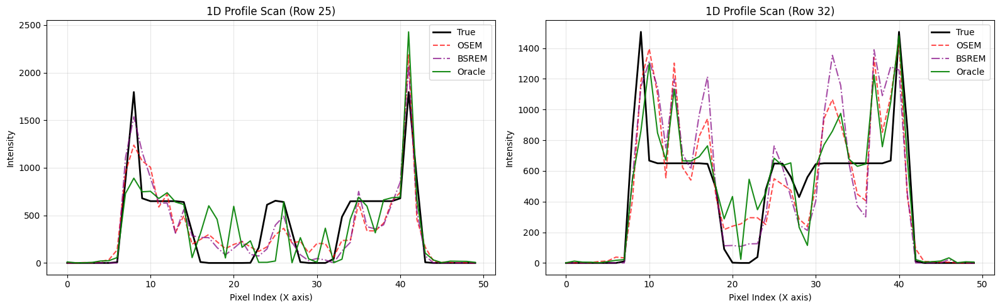

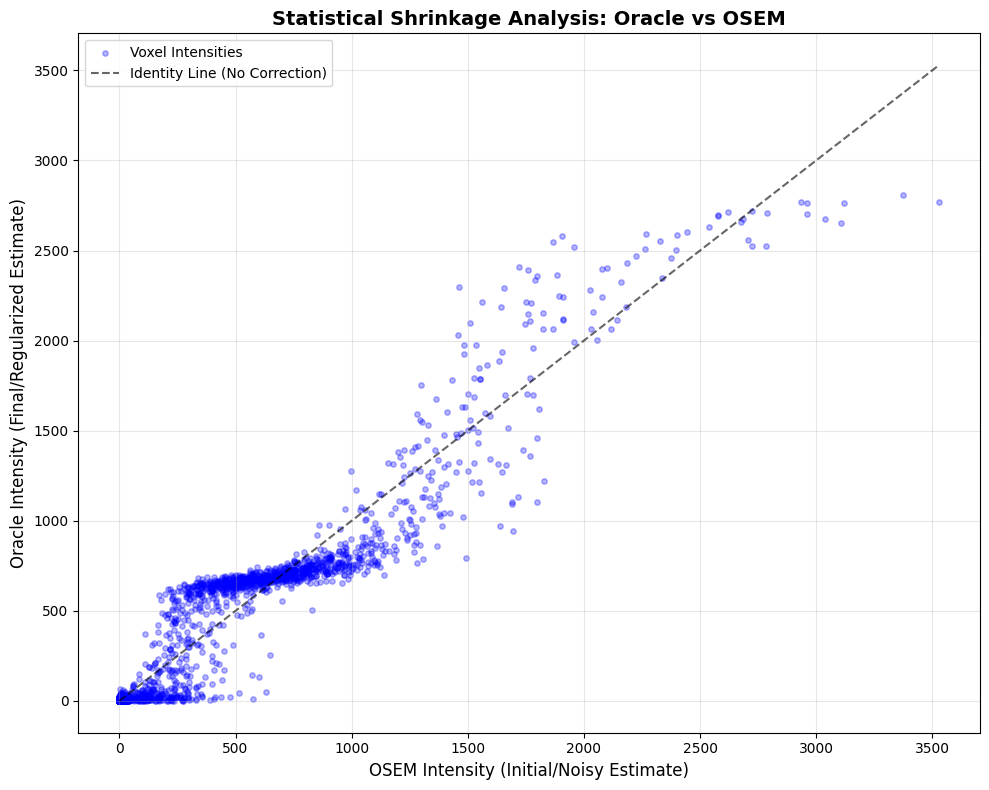

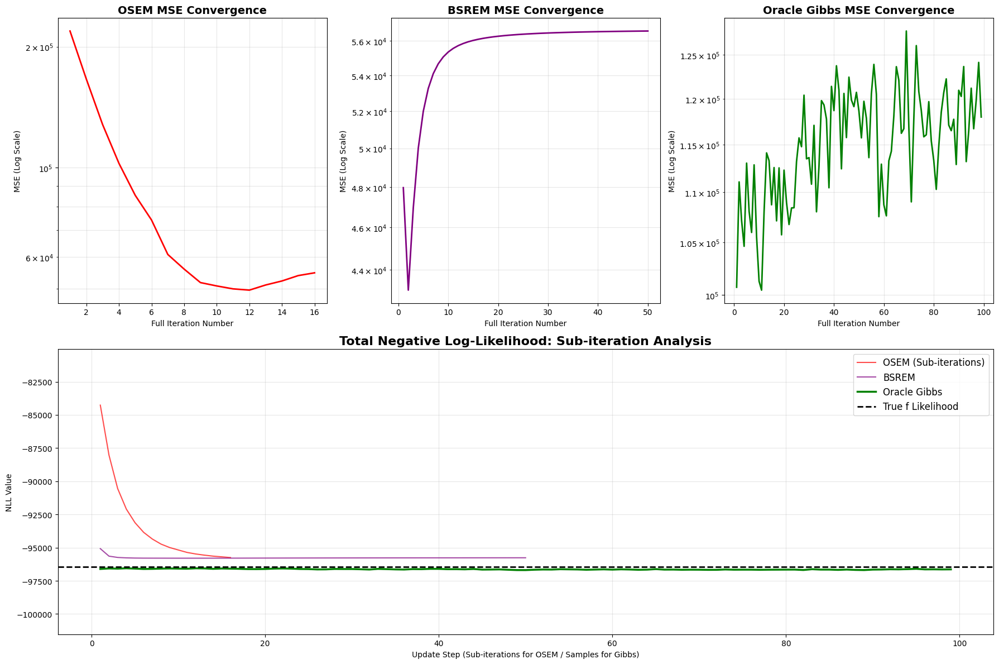


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 6/6 | f=1e+06 | tau=5.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 1.26%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 53837.2409
Iteration 2/2 finished. Current MSE: 55050.4223
[2/3] Running BSREM (Fixed: Beta=0.05, Subsets=10, Iters=50)
Starting Auto-Scaled BSREM: Beta=0.05, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 4.00e-04
BSREM Iter 1/50 | MSE: 47285.1591
BSREM Iter 6/50 | MSE: 53625.3781
BSREM Iter 11/50 | MSE: 56097.5470
BSREM Iter 16/50 


--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_6

SUMMARY STATISTICS
OSEM   -> RMSE: 234.628264 | SNR: 9.14 dB
BSREM  -> RMSE: 239.055002 | SNR: 8.98 dB
Oracle -> RMSE: 264.516796 | SNR: 8.10 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  -12.74%
Oracle RMSE Improvement over BSREM: -10.65%


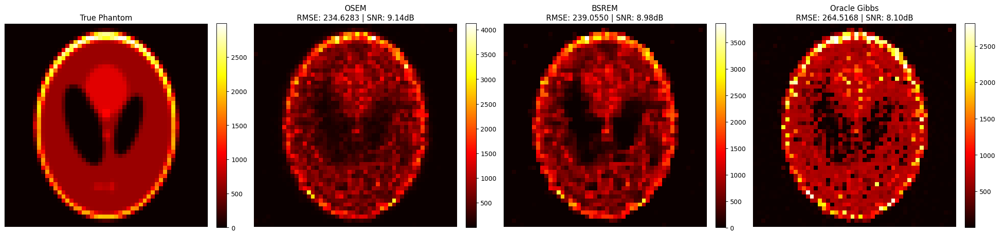

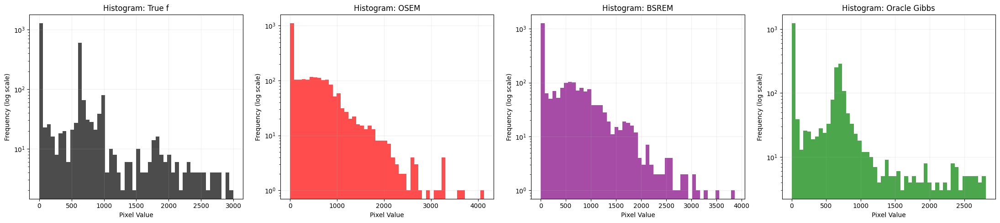

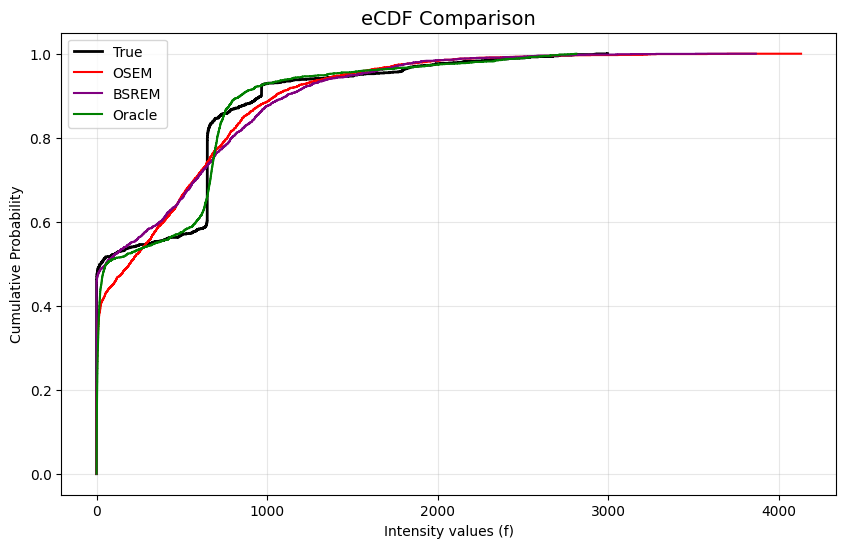

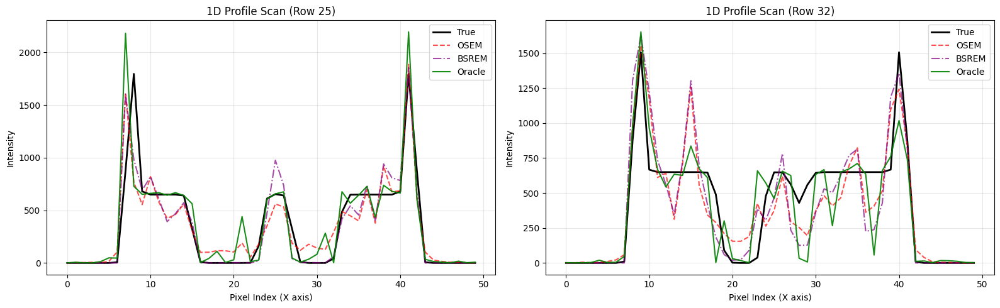

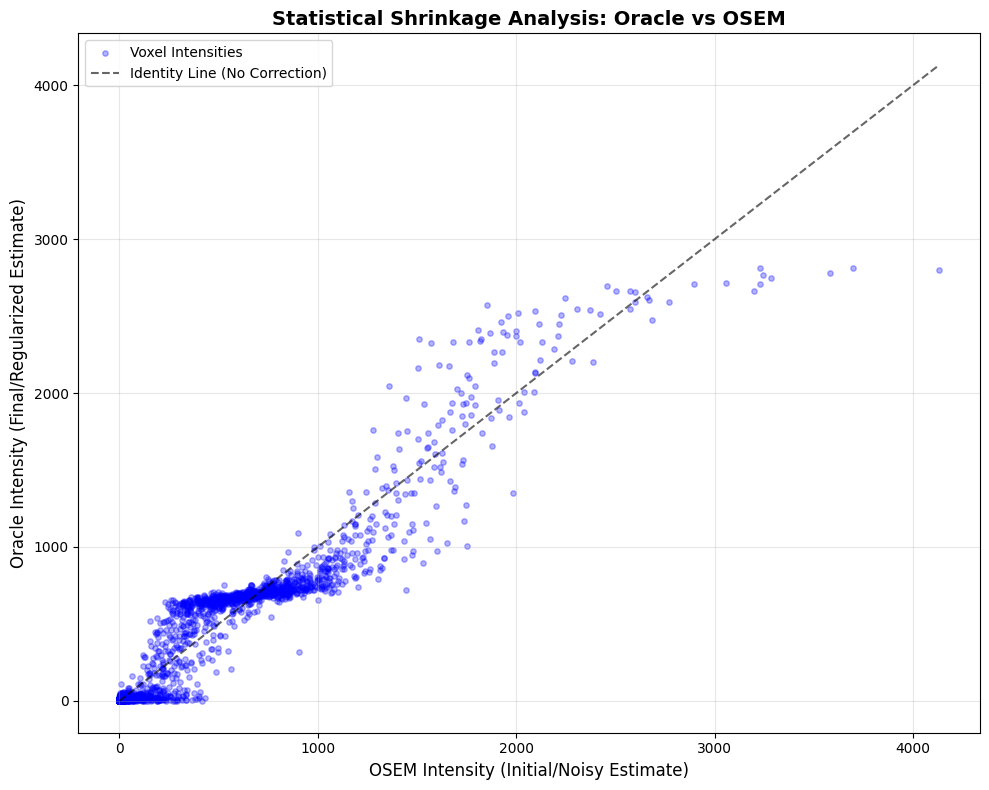

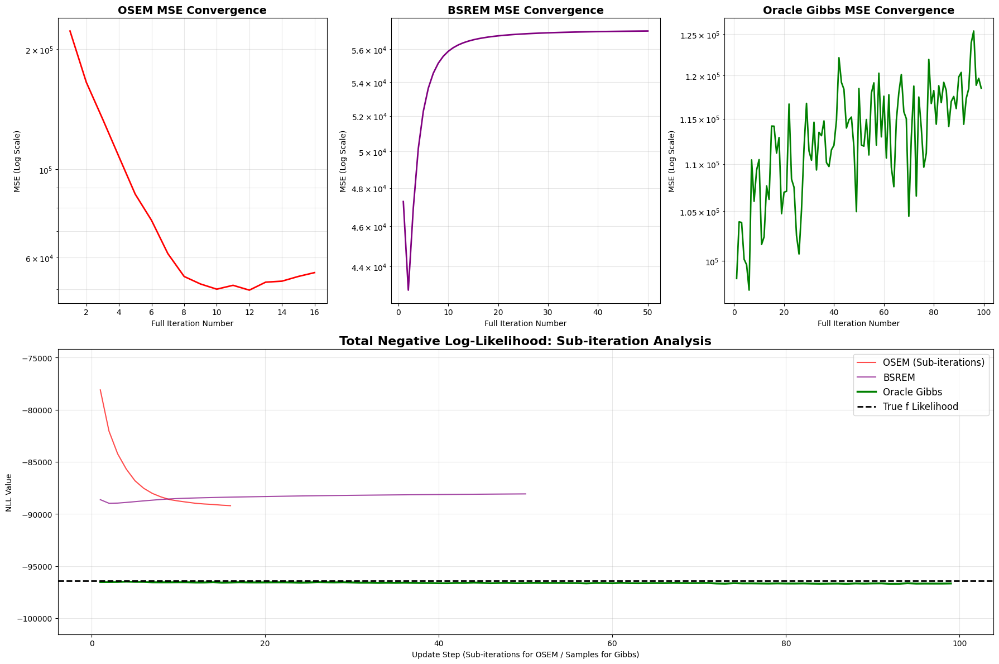


--- Master Evaluation Suite Complete ---

FINAL COMPARISON SUMMARY
 f_factor          tau  RMSE_OSEM  RMSE_BSREM  RMSE_Oracle
 100000.0 1.000000e-09  65.172488   36.089707    39.997881
 100000.0 5.000000e-09  65.056316   36.296035    40.118839
 500000.0 1.000000e-09 153.684162  125.337060   140.535248
 500000.0 5.000000e-09 156.038857  129.491873   142.693762
1000000.0 1.000000e-09 234.089104  237.879407   271.226843
1000000.0 5.000000e-09 234.628264  239.055002   264.516796


In [28]:
# ==============================================================================
# 1. FIXED PARAMETERS FROM OPTIMIZATION PHASE
# ==============================================================================
# Mapping scenarios to their respective optimal hyperparameters identified
# during the Grid Search phase.
bsrem_best_configs = {
    # (f_factor, tau): (beta, subsets, iters)
    (1e5, 1e-9): (0.30, 10, 30),
    (1e5, 5e-9): (0.30, 10, 30),
    (5e5, 1e-9): (0.10, 10, 50),
    (5e5, 5e-9): (0.10, 10, 50),
    (1e6, 1e-9): (0.05, 10, 50),
    (1e6, 5e-9): (0.05, 10, 50)
}

# Configuration for the baseline OSEM and the proposed Oracle Gibbs sampler
experiment_config = {
    "physics": {
        "B_SQRT": [50], # Increase to 90 for high-resolution overnight production
        "D": [150],     # Increase to 270 for high-resolution overnight production
        "f_factor": [1e5, 5e5, 1e6],
        "tau": [1e-9, 5e-9],
        "beta_physics": [0.8]
    },
    "osem": {
        "n_iters": 2,
        "n_subsets": 8
    },
    "oracle": {
        "G": 100,
        "burn_in": 20,
        "n_prior_points": 1000,
        "window_size": 101
    }
}

# ==============================================================================
# 2. FINAL PRODUCTION EXECUTION ENGINE
# ==============================================================================
output_dir = "final_thesis_production"
os.makedirs(output_dir, exist_ok=True)

def generate_grid(params_dict):
    """Generates a list of all parameter combinations for the final run."""
    keys, values = zip(*params_dict.items())
    return [dict(zip(keys, combo)) for combo in itertools.product(*values)]

scenarios = generate_grid(experiment_config["physics"])
results_summary = []

print(f"--- Starting Final Production Run: {len(scenarios)} Scenarios ---")

for i, phys in enumerate(scenarios):
    print("\n" + "█"*80)
    print(f" RUNNING SCENARIO {i+1}/6 | f={phys['f_factor']:.0e} | tau={phys['tau']:.1e}")
    print("█"*80)

    # --- A. Setup Simulation ---
    pet = PET(
        B_SQRT=phys["B_SQRT"], D=phys["D"],
        beta=phys["beta_physics"], tau=phys["tau"], f_factor=phys["f_factor"]
    )
    pet.run_simulation_with_randoms()
    prefix = f"{output_dir}/Final_Scen_{i+1}"

    # --- B. Standard OSEM Reconstruction ---
    print(f"[1/3] Running OSEM (Fixed: {experiment_config['osem']['n_iters']} iters, {experiment_config['osem']['n_subsets']} subs)")
    f_osem = pet.reconstruct_osem(
        n_iters=experiment_config['osem']['n_iters'],
        n_subsets=experiment_config['osem']['n_subsets']
    )

    # --- C. Optimized BSREM Reconstruction ---
    # Retrieve the best-performing hyperparameters for this specific noise scenario
    b_val, s_val, i_val = bsrem_best_configs[(phys['f_factor'], phys['tau'])]
    print(f"[2/3] Running BSREM (Fixed: Beta={b_val}, Subsets={s_val}, Iters={i_val})")
    f_bsrem = pet.reconstruct_bsrem(
        n_iters=i_val,
        n_subsets=s_val,
        beta=b_val,
        gamma=2.0
    )

    # --- D. Proposed Oracle Gibbs Sampler ---
    print(f"[3/3] Running Oracle Gibbs (Initialized from OSEM)...")
    ora_c = experiment_config["oracle"]
    f_oracle = pet.run_oracle_gibbs(
        G=ora_c["G"], burn_in=ora_c["burn_in"],
        f_start=f_osem,
        n_prior_points=ora_c["n_prior_points"],
        window_size=ora_c["window_size"]
    )

    # --- E. Quantitative Metrics & Comparative Reporting ---
    _, rmse_osem, snr_osem = pet._get_metrics(f_osem)
    _, rmse_bsrem, snr_bsrem = pet._get_metrics(f_bsrem)
    _, rmse_ora, snr_ora = pet._get_metrics(f_oracle)

    results_summary.append({
        "Scenario": i+1,
        "f_factor": phys['f_factor'],
        "tau": phys['tau'],
        "RMSE_OSEM": rmse_osem,
        "RMSE_BSREM": rmse_bsrem,
        "RMSE_Oracle": rmse_ora,
        "SNR_OSEM": snr_osem,
        "SNR_BSREM": snr_bsrem,
        "SNR_Oracle": snr_ora
    })

    # Generate the comprehensive graphical suite (Profiles, Comparison Heatmaps, etc.)
    rows_to_plot = [phys["B_SQRT"] // 2, int(phys["B_SQRT"] * 0.65)]
    pet.plot_full_comparison_suite(
        f_osem, f_bsrem, f_oracle,
        rows_to_plot=rows_to_plot,
        save_prefix=prefix
    )

# ==============================================================================
# 3. FINAL SUMMARY EXPORT
# ==============================================================================
df_final = pd.DataFrame(results_summary)
df_final.to_csv(f"{output_dir}/final_comparison_results.csv", index=False)

print("\n" + "="*80)
print("FINAL COMPARISON SUMMARY - PRODUCTION COMPLETE")
print("="*80)
print(df_final[["f_factor", "tau", "RMSE_OSEM", "RMSE_BSREM", "RMSE_Oracle"]].to_string(index=False))

--- Starting Final Production Run: 6 Scenarios ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 1/6 | f=1e+05 | tau=1.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.03%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 1783.1816
Iteration 2/2 finished. Current MSE: 4247.4532
[2/3] Running BSREM (Fixed: Beta=0.3, Subsets=10, Iters=30)
Starting Auto-Scaled BSREM: Beta=0.3, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 2.40e-03
BSREM Iter 1/30 | MSE: 1118.0612
BSREM Iter 6/30 | MSE: 1283.1072
BSREM Iter 11/30 | MSE: 1296.3552
BSREM Iter 16/30

   --> [Lesion ROI] RelErr: OSEM=74.8% | BSREM=41.3% | Oracle=30.4%

--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_1

SUMMARY STATISTICS
OSEM   -> RMSE: 65.172488 | SNR: 0.27 dB
BSREM  -> RMSE: 36.089707 | SNR: 5.40 dB
Oracle -> RMSE: 39.997881 | SNR: 4.51 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  38.63%
Oracle RMSE Improvement over BSREM: -10.83%


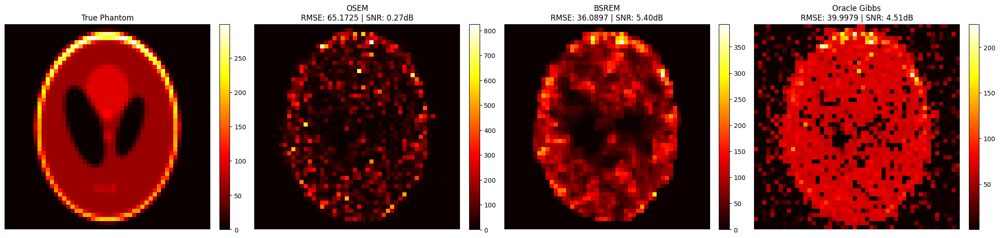

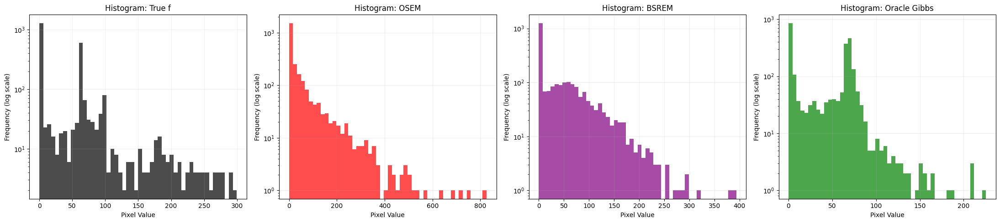

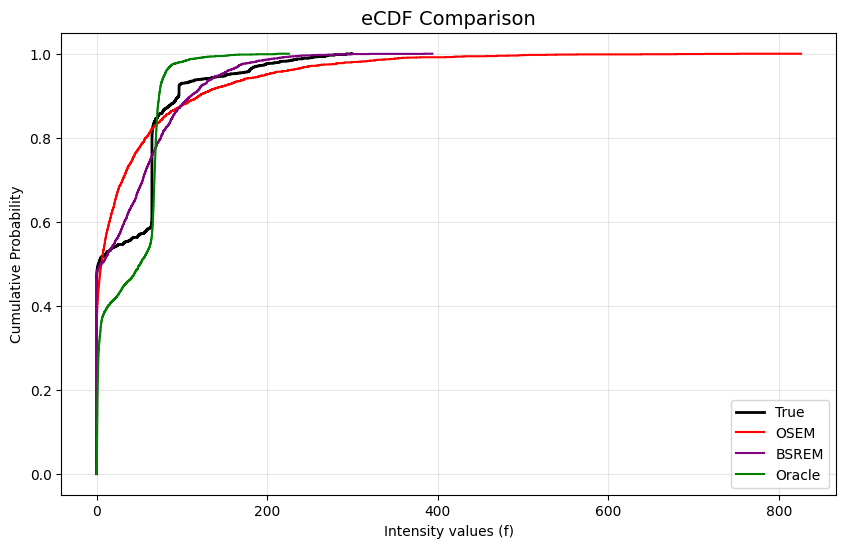

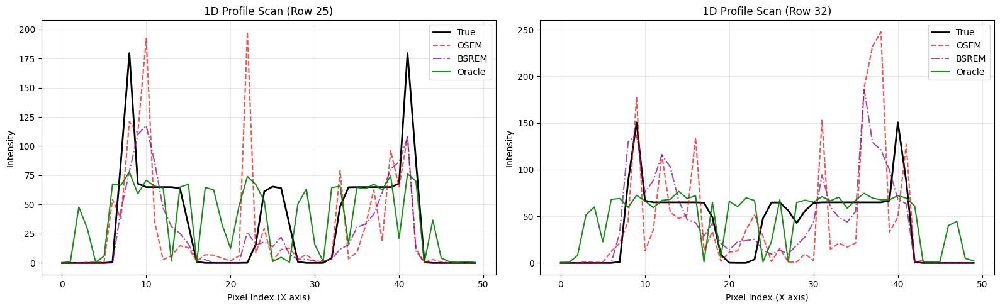

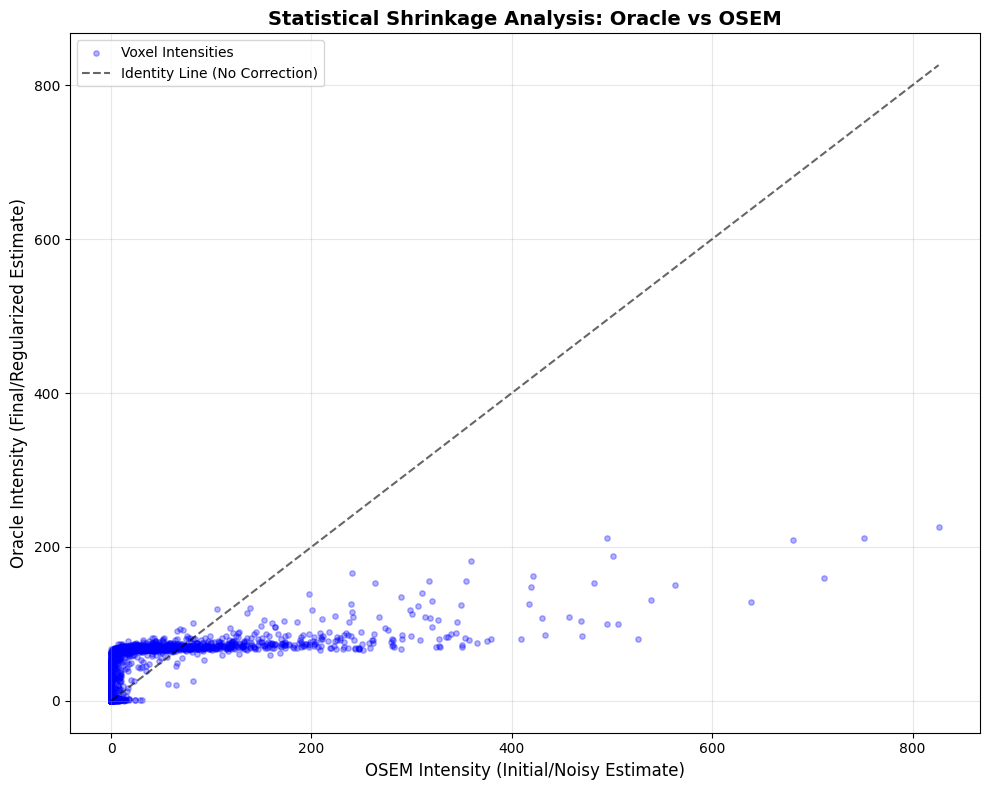

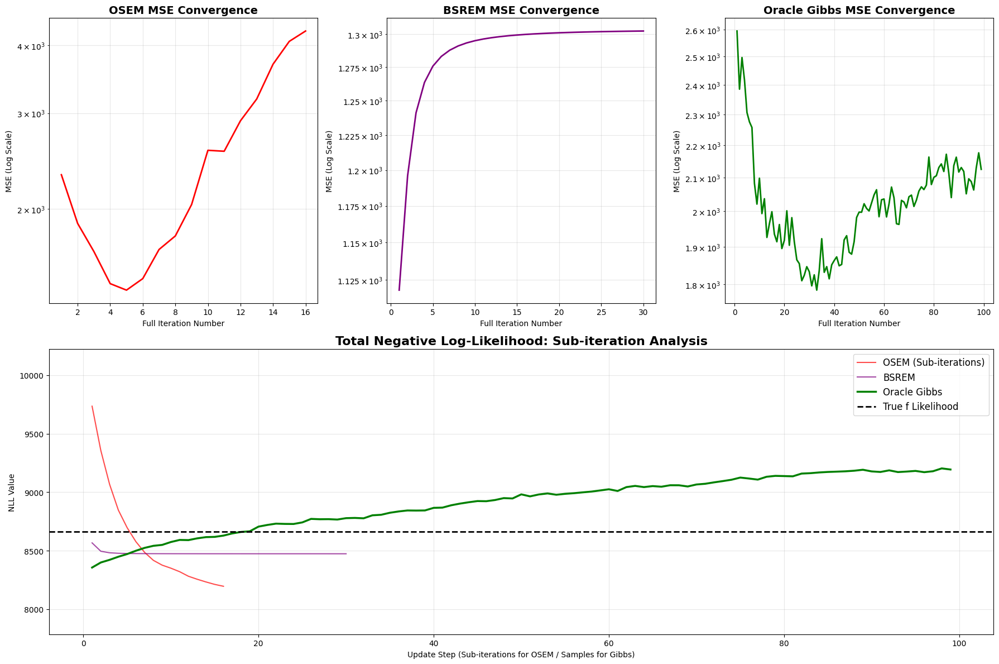


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 2/6 | f=1e+05 | tau=5.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 0.13%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 1773.5821
Iteration 2/2 finished. Current MSE: 4232.3243
[2/3] Running BSREM (Fixed: Beta=0.3, Subsets=10, Iters=30)
Starting Auto-Scaled BSREM: Beta=0.3, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 2.40e-03
BSREM Iter 1/30 | MSE: 1131.2672
BSREM Iter 6/30 | MSE: 1298.2106
BSREM Iter 11/30 | MSE: 1311.4419
BSREM Iter 16/30 | MSE: 1

   --> [Lesion ROI] RelErr: OSEM=74.7% | BSREM=41.4% | Oracle=30.4%

--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_2

SUMMARY STATISTICS
OSEM   -> RMSE: 65.056316 | SNR: 0.29 dB
BSREM  -> RMSE: 36.296035 | SNR: 5.35 dB
Oracle -> RMSE: 40.118839 | SNR: 4.48 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  38.33%
Oracle RMSE Improvement over BSREM: -10.53%


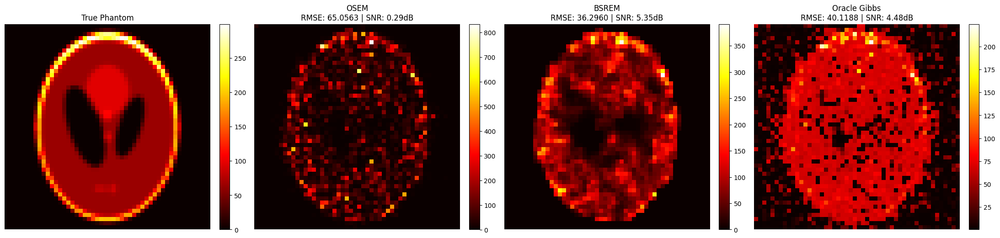

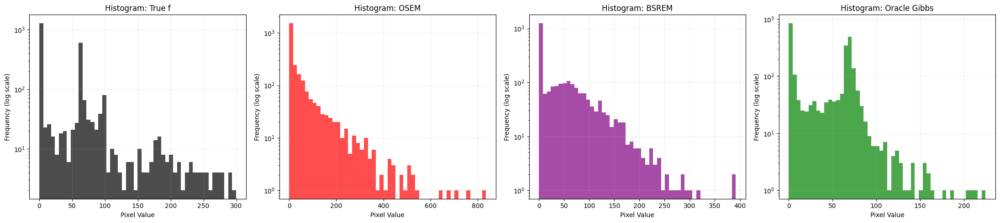

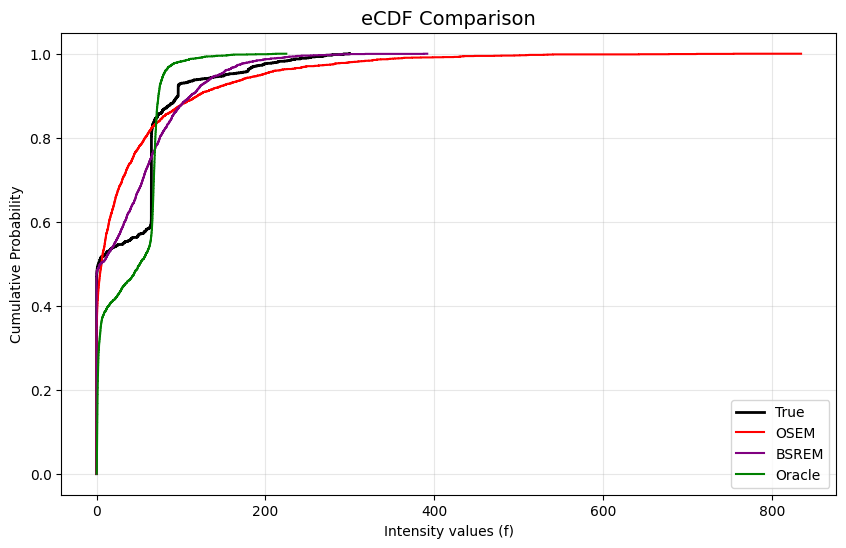

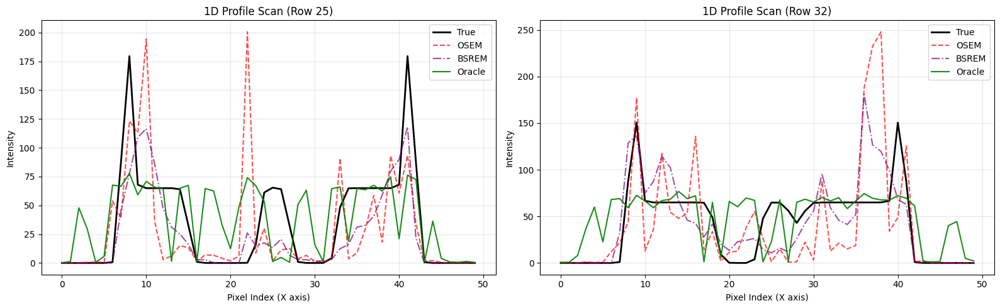

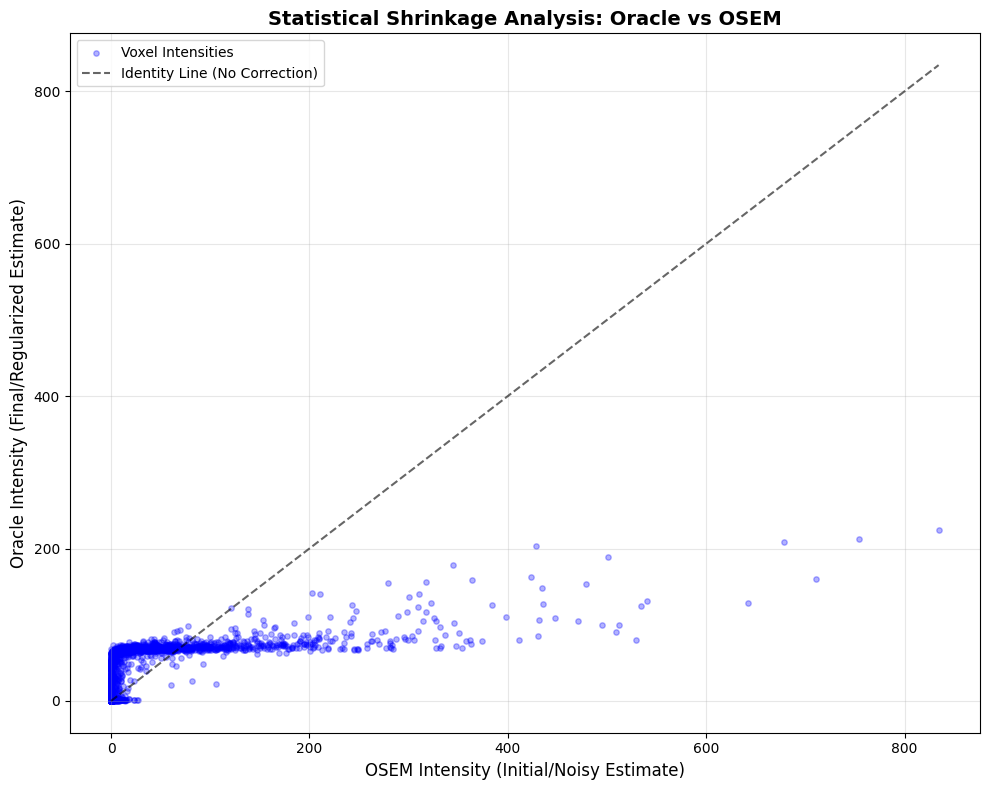

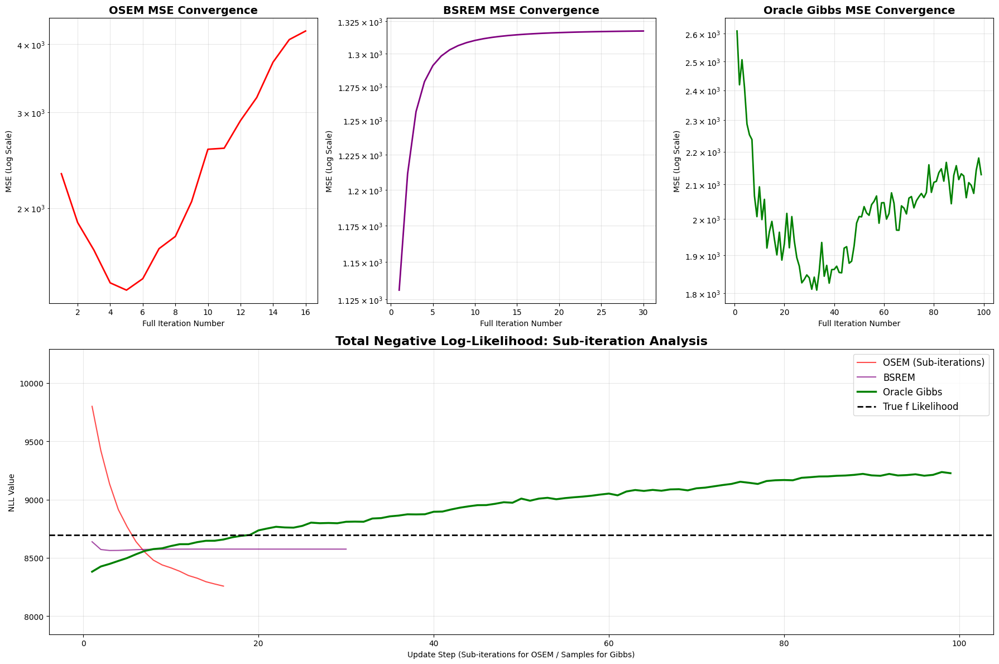


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 3/6 | f=5e+05 | tau=1.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.13%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 16520.3576
Iteration 2/2 finished. Current MSE: 23618.8216
[2/3] Running BSREM (Fixed: Beta=0.1, Subsets=10, Iters=50)
Starting Auto-Scaled BSREM: Beta=0.1, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 8.00e-04
BSREM Iter 1/50 | MSE: 14179.5850
BSREM Iter 6/50 | MSE: 15363.1467
BSREM Iter 11/50 | MSE: 15581.4558
BSREM Iter 16/50 | M

   --> [Lesion ROI] RelErr: OSEM=40.9% | BSREM=29.5% | Oracle=27.2%

--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_3

SUMMARY STATISTICS
OSEM   -> RMSE: 153.684162 | SNR: 6.80 dB
BSREM  -> RMSE: 125.337060 | SNR: 8.57 dB
Oracle -> RMSE: 140.535248 | SNR: 7.58 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  8.56%
Oracle RMSE Improvement over BSREM: -12.13%


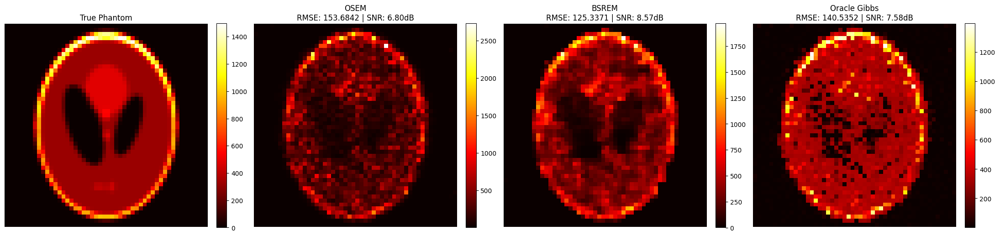

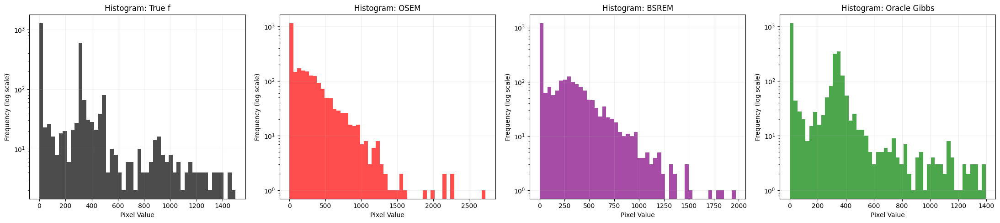

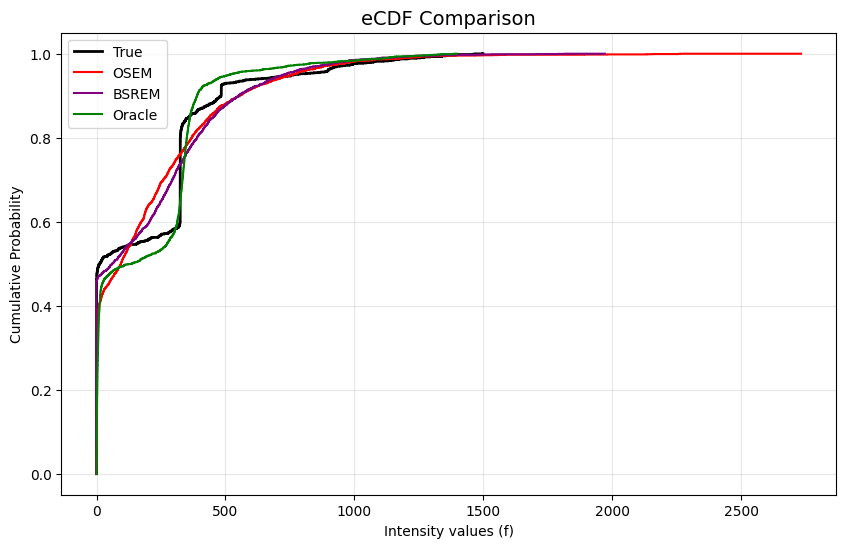

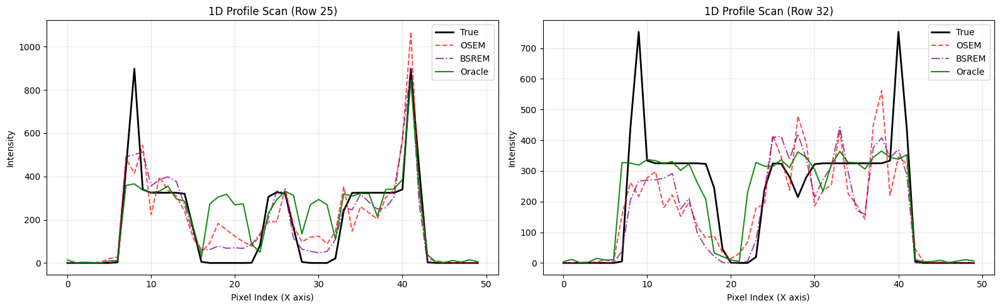

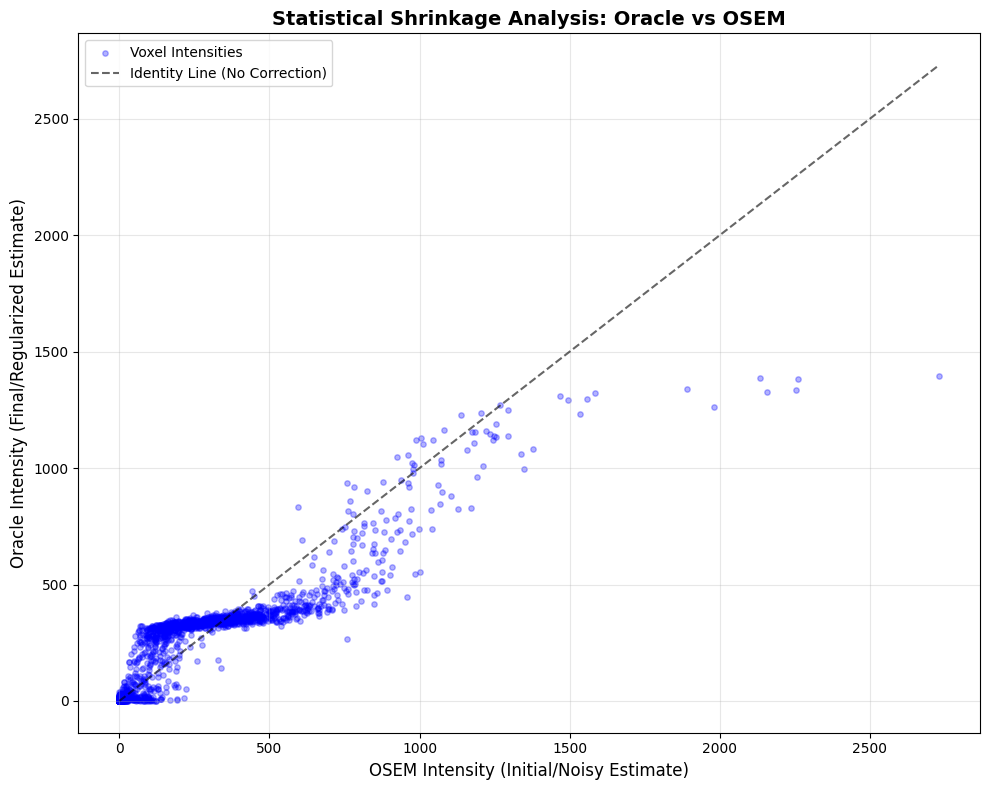

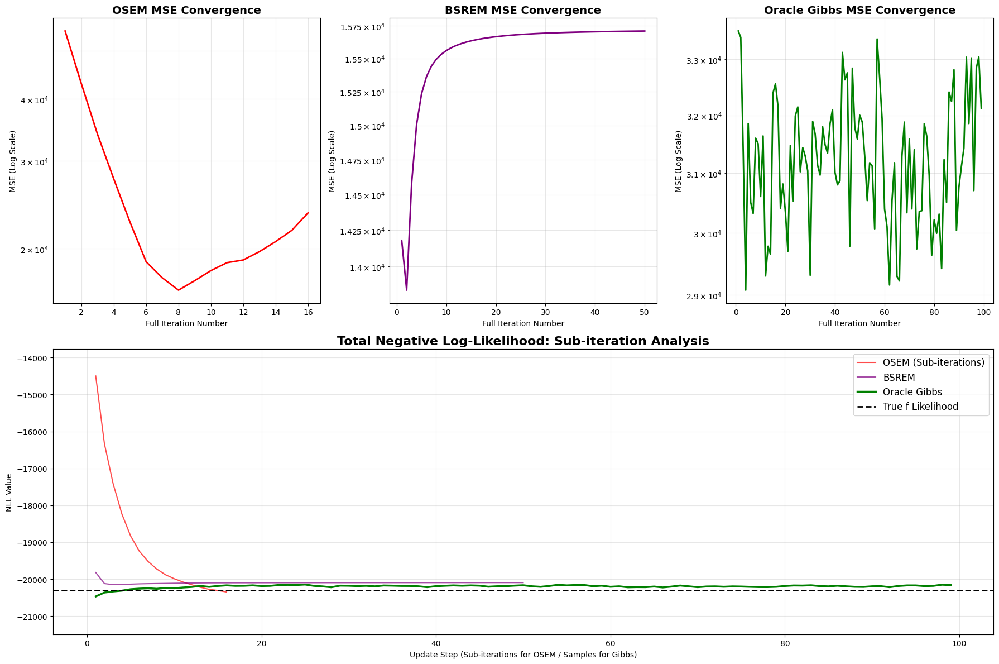


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 4/6 | f=5e+05 | tau=5.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 0.63%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 17367.7144
Iteration 2/2 finished. Current MSE: 24348.1250
[2/3] Running BSREM (Fixed: Beta=0.1, Subsets=10, Iters=50)
Starting Auto-Scaled BSREM: Beta=0.1, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 8.00e-04
BSREM Iter 1/50 | MSE: 15518.6536
BSREM Iter 6/50 | MSE: 16407.0735
BSREM Iter 11/50 | MSE: 16666.7034
BSREM Iter 16/50 | M

   --> [Lesion ROI] RelErr: OSEM=36.6% | BSREM=26.3% | Oracle=25.5%

--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_4

SUMMARY STATISTICS
OSEM   -> RMSE: 156.038857 | SNR: 6.67 dB
BSREM  -> RMSE: 129.491873 | SNR: 8.29 dB
Oracle -> RMSE: 142.693762 | SNR: 7.44 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  8.55%
Oracle RMSE Improvement over BSREM: -10.20%


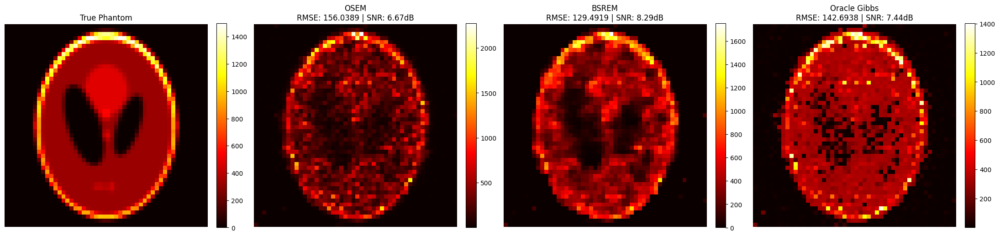

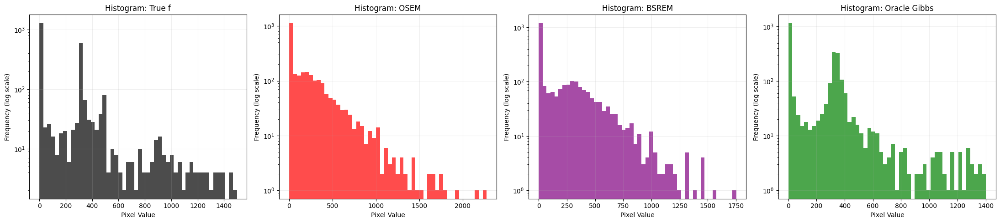

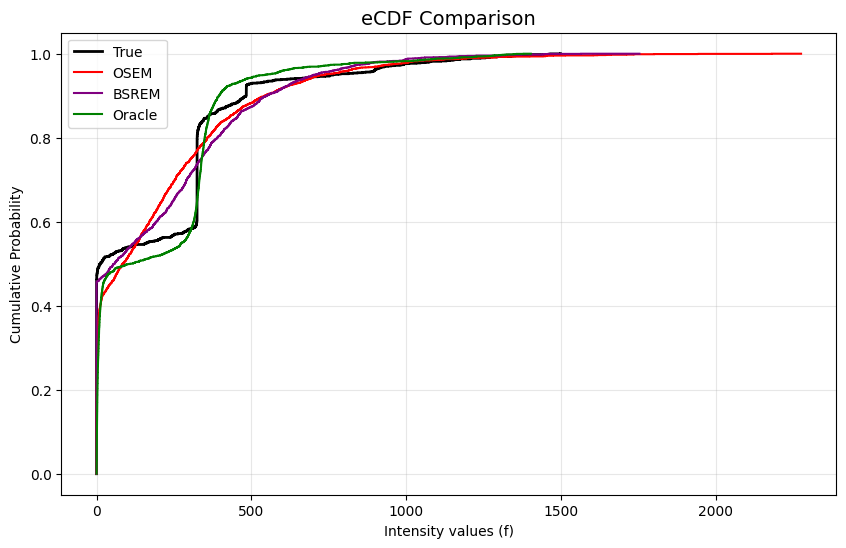

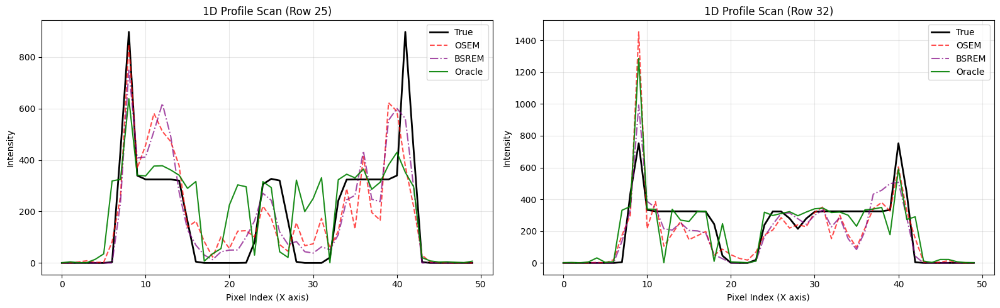

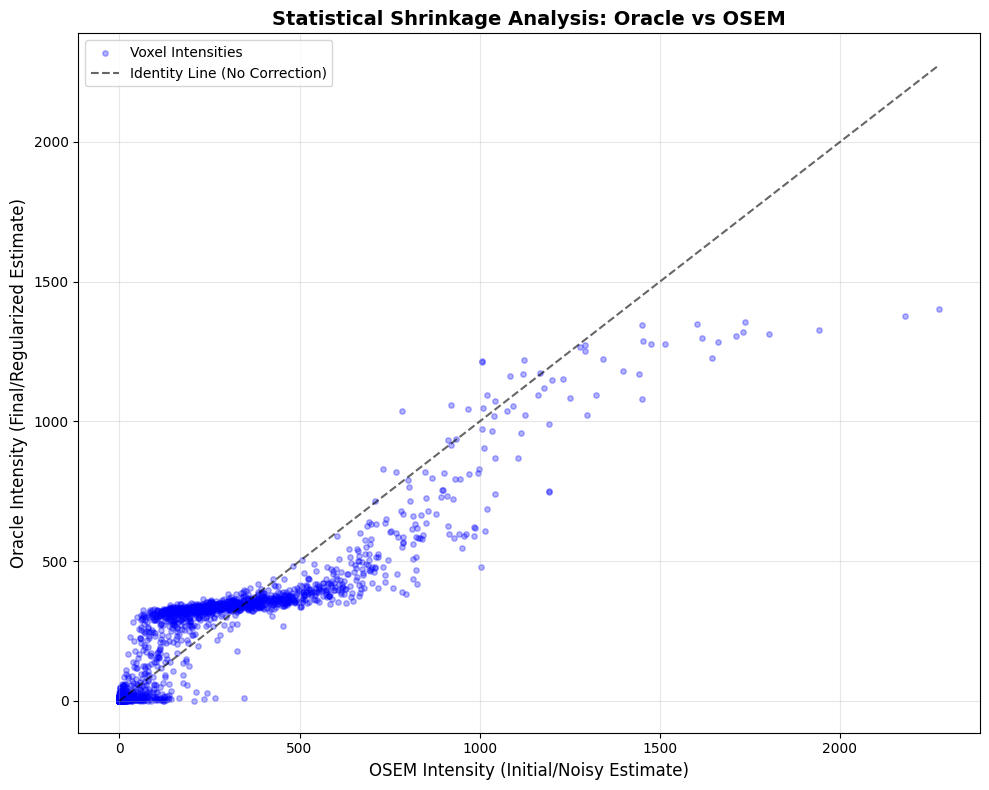

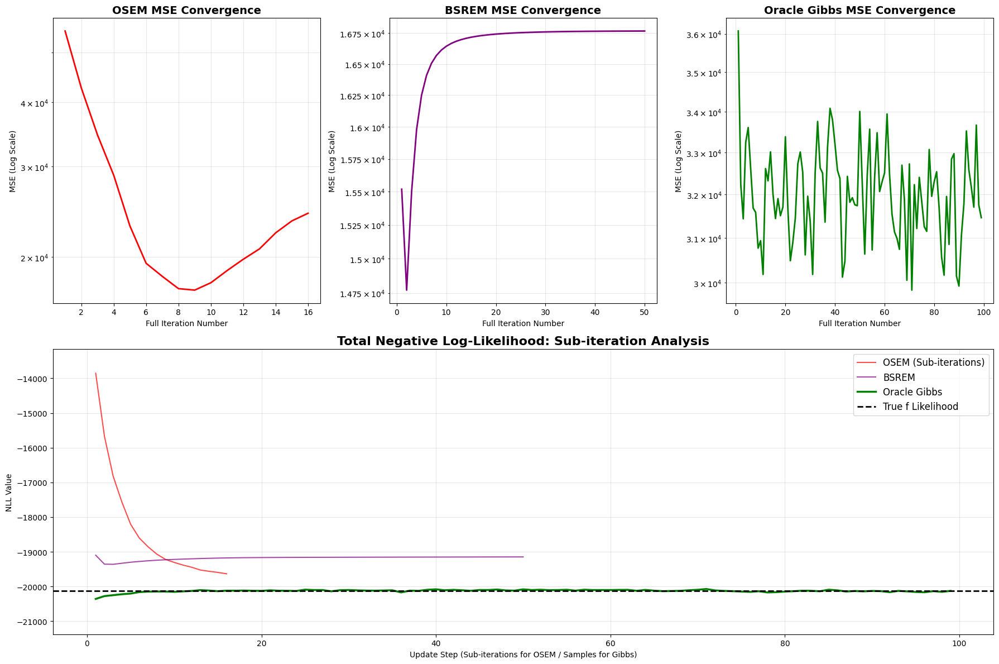


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 5/6 | f=1e+06 | tau=1.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.25%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 55978.6548
Iteration 2/2 finished. Current MSE: 54797.7087
[2/3] Running BSREM (Fixed: Beta=0.05, Subsets=10, Iters=50)
Starting Auto-Scaled BSREM: Beta=0.05, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 4.00e-04
BSREM Iter 1/50 | MSE: 47970.4161
BSREM Iter 6/50 | MSE: 53263.5413
BSREM Iter 11/50 | MSE: 55559.1560
BSREM Iter 16/50 

   --> [Lesion ROI] RelErr: OSEM=26.5% | BSREM=24.2% | Oracle=25.7%

--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_5

SUMMARY STATISTICS
OSEM   -> RMSE: 234.089104 | SNR: 9.16 dB
BSREM  -> RMSE: 237.879407 | SNR: 9.02 dB
Oracle -> RMSE: 271.226843 | SNR: 7.88 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  -15.86%
Oracle RMSE Improvement over BSREM: -14.02%


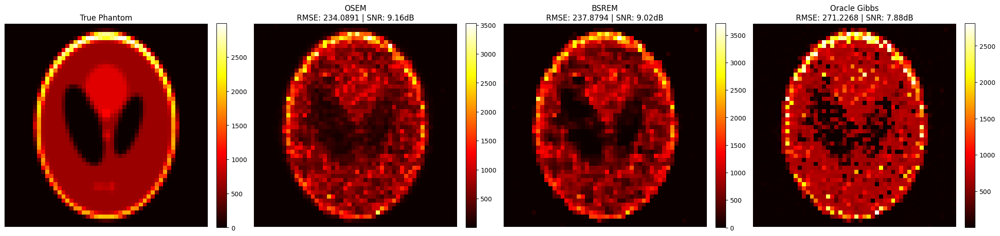

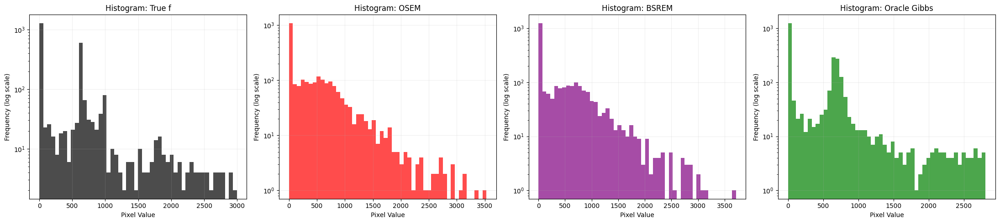

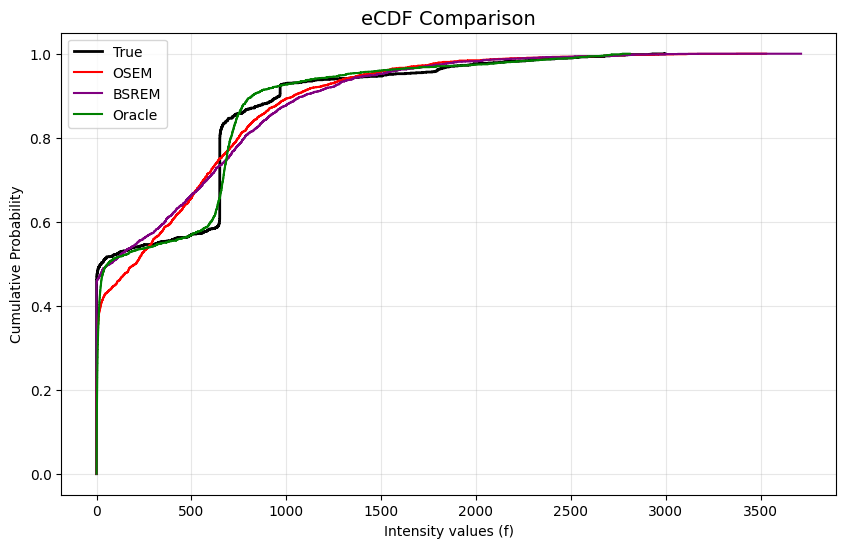

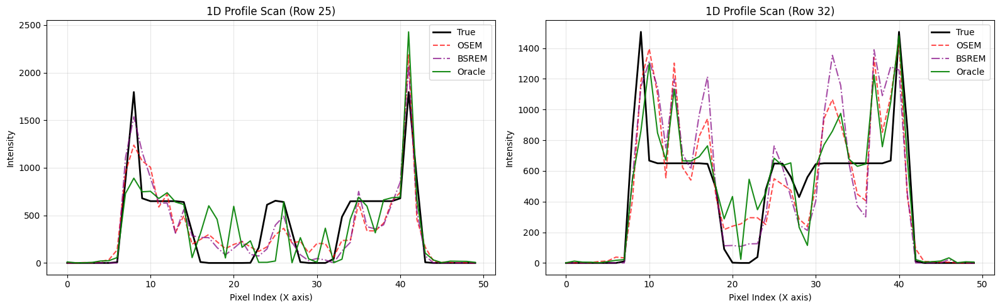

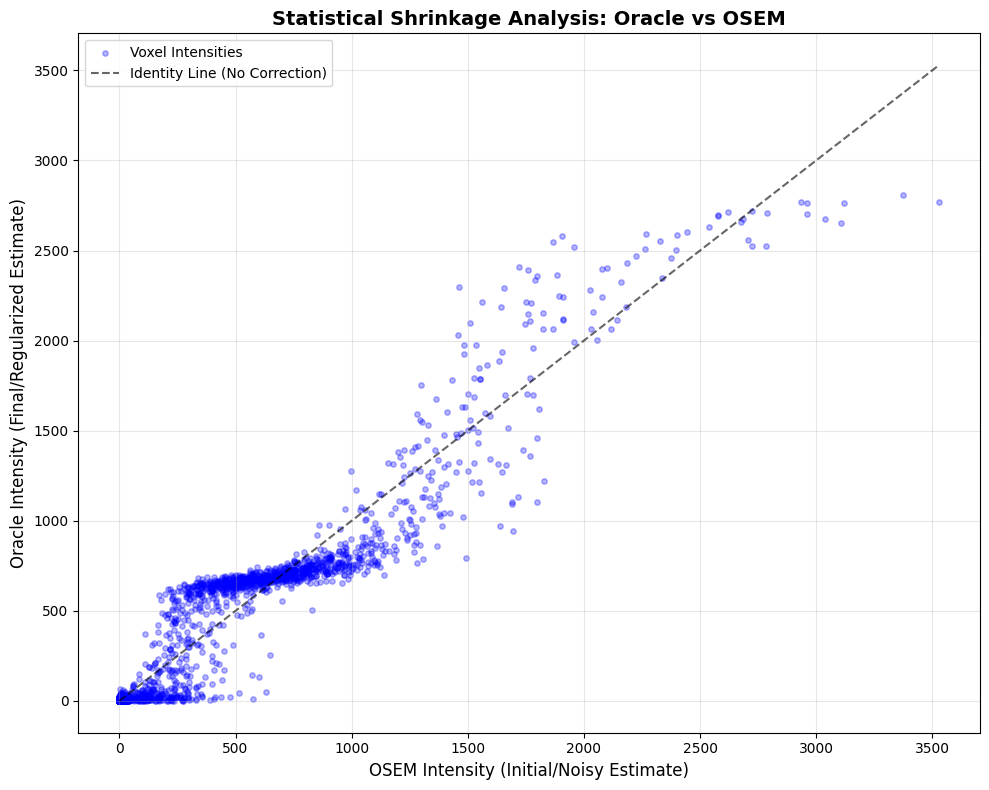

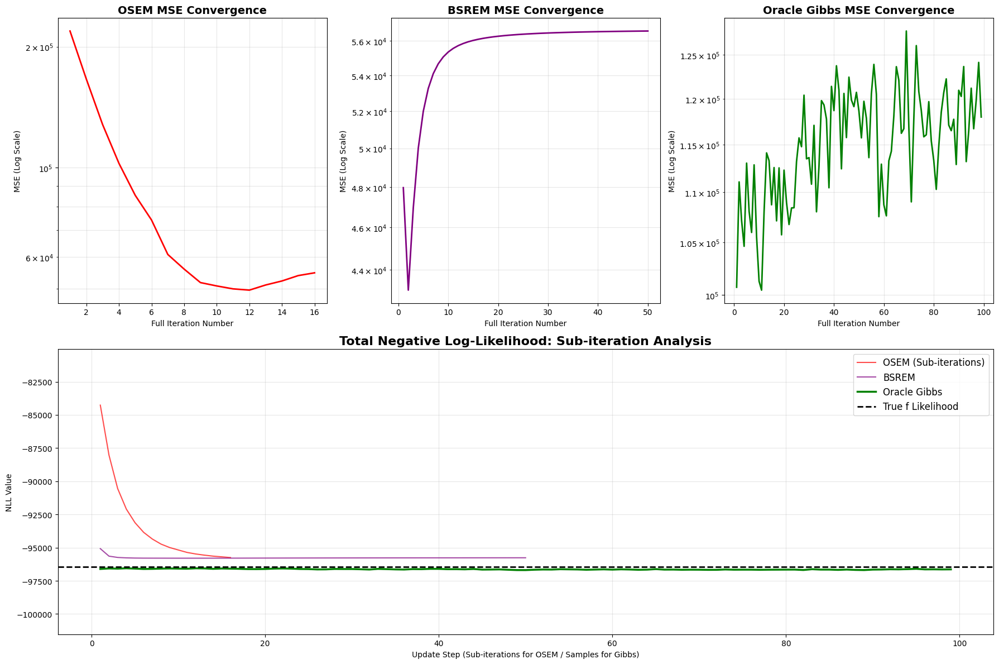


--- Master Evaluation Suite Complete ---

████████████████████████████████████████████████████████████████████████████████
 RUNNING SCENARIO 6/6 | f=1e+06 | tau=5.0e-09
████████████████████████████████████████████████████████████████████████████████
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 1.26%
[1/3] Running OSEM (Fixed: 2 iters, 8 subs)
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 53837.2409
Iteration 2/2 finished. Current MSE: 55050.4223
[2/3] Running BSREM (Fixed: Beta=0.05, Subsets=10, Iters=50)
Starting Auto-Scaled BSREM: Beta=0.05, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 4.00e-04
BSREM Iter 1/50 | MSE: 47285.1591
BSREM Iter 6/50 | MSE: 53625.3781
BSREM Iter 11/50 | MSE: 56097.5470
BSREM Iter 16/50 

   --> [Lesion ROI] RelErr: OSEM=25.0% | BSREM=23.7% | Oracle=25.4%

--- Generating Master Evaluation Suite ---
[*] Images will be saved to disk with prefix: final_thesis_production/Final_Scen_6

SUMMARY STATISTICS
OSEM   -> RMSE: 234.628264 | SNR: 9.14 dB
BSREM  -> RMSE: 239.055002 | SNR: 8.98 dB
Oracle -> RMSE: 264.516796 | SNR: 8.10 dB
--------------------------------------------------
Oracle RMSE Improvement over OSEM:  -12.74%
Oracle RMSE Improvement over BSREM: -10.65%


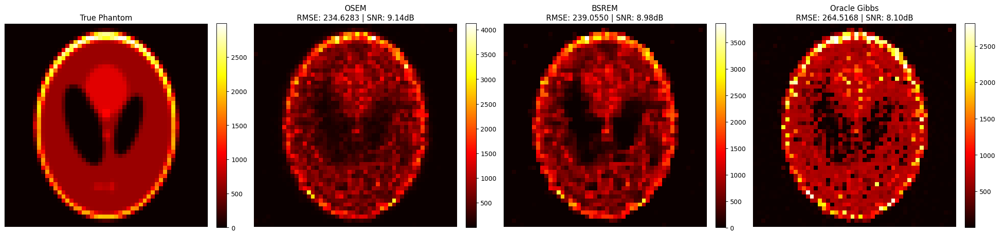

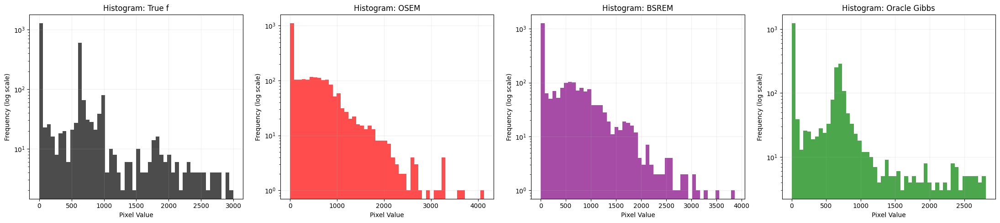

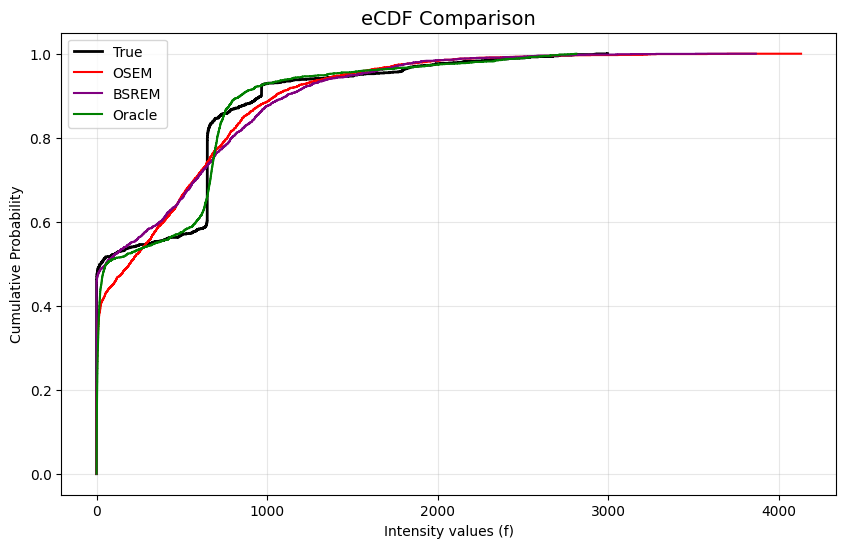

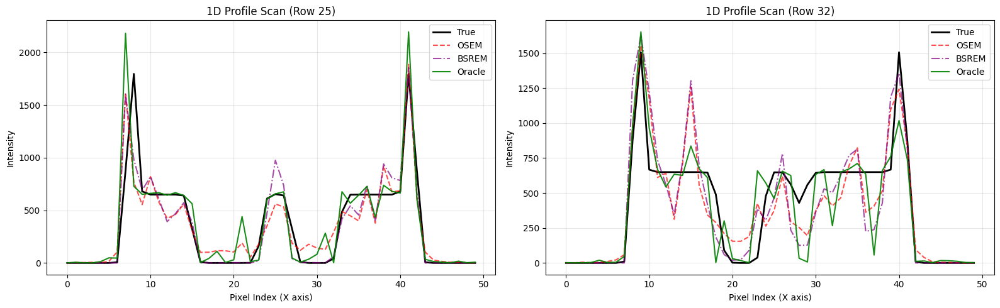

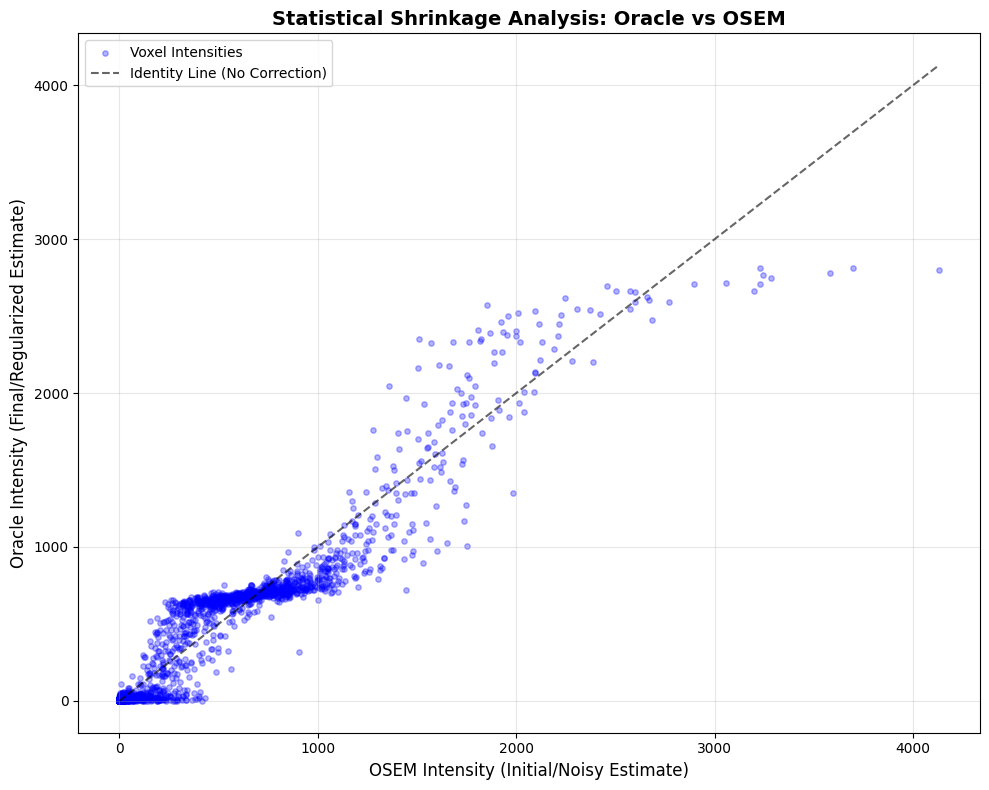

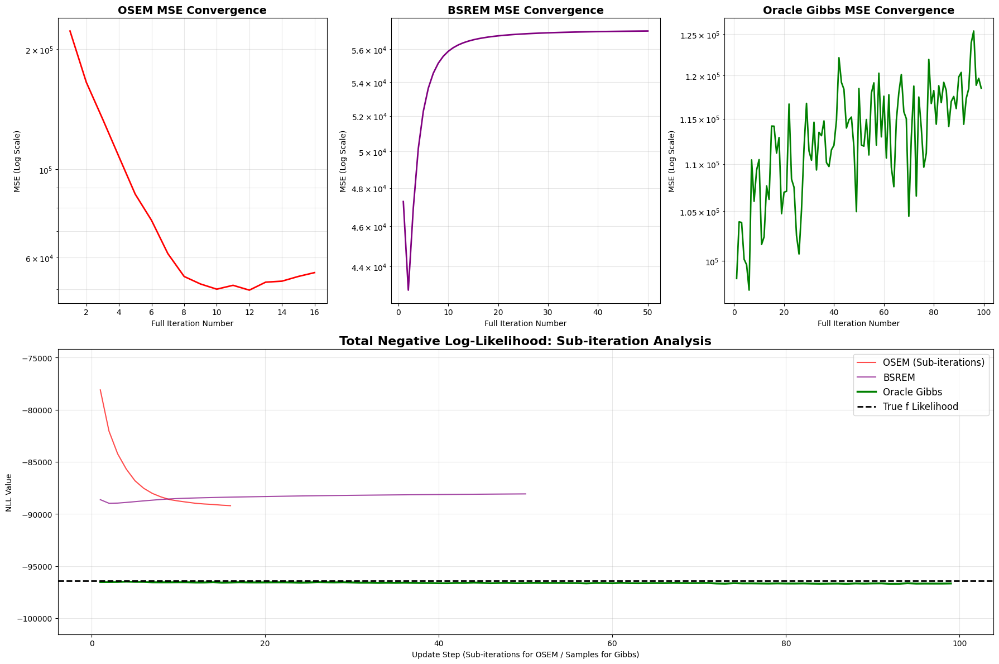


--- Master Evaluation Suite Complete ---

FINAL COMPARISON SUMMARY
 f_factor          tau  RMSE_OSEM  RMSE_BSREM  RMSE_Oracle
 100000.0 1.000000e-09  65.172488   36.089707    39.997881
 100000.0 5.000000e-09  65.056316   36.296035    40.118839
 500000.0 1.000000e-09 153.684162  125.337060   140.535248
 500000.0 5.000000e-09 156.038857  129.491873   142.693762
1000000.0 1.000000e-09 234.089104  237.879407   271.226843
1000000.0 5.000000e-09 234.628264  239.055002   264.516796


In [49]:
# ==============================================================================
# 1. FIXED PARAMETERS FROM OPTIMIZATION PHASE
# ==============================================================================
# Mapping scenarios to their respective optimal hyperparameters identified
# during the Grid Search phase.
bsrem_best_configs = {
    # (f_factor, tau): (beta, subsets, iters)
    (1e5, 1e-9): (0.30, 10, 30),
    (1e5, 5e-9): (0.30, 10, 30),
    (5e5, 1e-9): (0.10, 10, 50),
    (5e5, 5e-9): (0.10, 10, 50),
    (1e6, 1e-9): (0.05, 10, 50),
    (1e6, 5e-9): (0.05, 10, 50)
}

# Configuration for the baseline OSEM and the proposed Oracle Gibbs sampler
experiment_config = {
    "physics": {
        "B_SQRT": [50], # Increase to 90 for high-resolution overnight production
        "D": [150],     # Increase to 270 for high-resolution overnight production
        "f_factor": [1e5, 5e5, 1e6],
        "tau": [1e-9, 5e-9],
        "beta_physics": [0.8]
    },
    "osem": {
        "n_iters": 2,
        "n_subsets": 8
    },
    "oracle": {
        "G": 100,
        "burn_in": 20,
        "n_prior_points": 1000,
        "window_size": 101
    }
}

# ==============================================================================
# 2. FINAL PRODUCTION EXECUTION ENGINE
# ==============================================================================
output_dir = "final_thesis_production"
os.makedirs(output_dir, exist_ok=True)

def generate_grid(params_dict):
    """Generates a list of all parameter combinations for the final run."""
    keys, values = zip(*params_dict.items())
    return [dict(zip(keys, combo)) for combo in itertools.product(*values)]

scenarios = generate_grid(experiment_config["physics"])
results_summary = []

print(f"--- Starting Final Production Run: {len(scenarios)} Scenarios ---")

for i, phys in enumerate(scenarios):
    print("\n" + "█"*80)
    print(f" RUNNING SCENARIO {i+1}/6 | f={phys['f_factor']:.0e} | tau={phys['tau']:.1e}")
    print("█"*80)

    # --- A. Setup Simulation ---
    pet = PET(
        B_SQRT=phys["B_SQRT"], D=phys["D"],
        beta=phys["beta_physics"], tau=phys["tau"], f_factor=phys["f_factor"]
    )
    pet.run_simulation_with_randoms()
    prefix = f"{output_dir}/Final_Scen_{i+1}"

    # --- B. Standard OSEM Reconstruction ---
    print(f"[1/3] Running OSEM (Fixed: {experiment_config['osem']['n_iters']} iters, {experiment_config['osem']['n_subsets']} subs)")
    f_osem = pet.reconstruct_osem(
        n_iters=experiment_config['osem']['n_iters'],
        n_subsets=experiment_config['osem']['n_subsets']
    )

    # --- C. Optimized BSREM Reconstruction ---
    # Retrieve the best-performing hyperparameters for this specific noise scenario
    b_val, s_val, i_val = bsrem_best_configs[(phys['f_factor'], phys['tau'])]
    print(f"[2/3] Running BSREM (Fixed: Beta={b_val}, Subsets={s_val}, Iters={i_val})")
    f_bsrem = pet.reconstruct_bsrem(
        n_iters=i_val,
        n_subsets=s_val,
        beta=b_val,
        gamma=2.0
    )

    # --- D. Proposed Oracle Gibbs Sampler ---
    print(f"[3/3] Running Oracle Gibbs (Initialized from OSEM)...")
    ora_c = experiment_config["oracle"]
    f_oracle = pet.run_oracle_gibbs(
        G=ora_c["G"], burn_in=ora_c["burn_in"],
        f_start=f_osem,
        n_prior_points=ora_c["n_prior_points"],
        window_size=ora_c["window_size"]
    )

    # --- E. Quantitative Metrics & ROI Analysis ---
    # Global metrics
    _, rmse_osem, snr_osem = pet._get_metrics(f_osem)
    _, rmse_bsrem, snr_bsrem = pet._get_metrics(f_bsrem)
    _, rmse_ora, snr_ora = pet._get_metrics(f_oracle)

    # Local ROI metrics (Diagnostic Lesions)
    lesion_metrics = pet.run_roi_analysis(f_osem, f_bsrem, f_oracle)

    # Store results for comparative reporting
    results_summary.append({
        "Scenario": i+1,
        "f_factor": phys['f_factor'],
        "tau": phys['tau'],
        "RMSE_OSEM": rmse_osem,
        "RMSE_BSREM": rmse_bsrem,
        "RMSE_Oracle": rmse_ora,
        "SNR_OSEM": snr_osem,
        "SNR_BSREM": snr_bsrem,
        "SNR_Oracle": snr_ora,
        "Lesion_RMSE_Oracle": lesion_metrics["Oracle"]["RMSE"],
        "Lesion_RelErr_Oracle": lesion_metrics["Oracle"]["RelErr"],
        "Lesion_RelErr_BSREM": lesion_metrics["BSREM"]["RelErr"],
        "Lesion_RelErr_OSEM": lesion_metrics["OSEM"]["RelErr"]
    })

    # Real-time console update for localized ROI performance
    print(f"   --> [Lesion ROI] RelErr: OSEM={lesion_metrics['OSEM']['RelErr']:.1f}% | "
          f"BSREM={lesion_metrics['BSREM']['RelErr']:.1f}% | "
          f"Oracle={lesion_metrics['Oracle']['RelErr']:.1f}%")

    # Generate the comprehensive graphical suite (Profiles, Histograms, eCDF, etc.)
    rows_to_plot = [phys["B_SQRT"] // 2, int(phys["B_SQRT"] * 0.65)]
    pet.plot_full_comparison_suite(
        f_osem, f_bsrem, f_oracle,
        rows_to_plot=rows_to_plot,
        save_prefix=prefix
    )

# ==============================================================================
# 3. FINAL RESULTS SYNTHESIS & EXPORT
# ==============================================================================
df_final = pd.DataFrame(results_summary)
df_final.to_csv(f"{output_dir}/final_comparison_results.csv", index=False)

print("\n" + "="*80)
print("FINAL COMPARISON SUMMARY - PRODUCTION COMPLETE")
print("="*80)
print(df_final[["f_factor", "tau", "RMSE_OSEM", "RMSE_BSREM", "RMSE_Oracle"]].to_string(index=False))

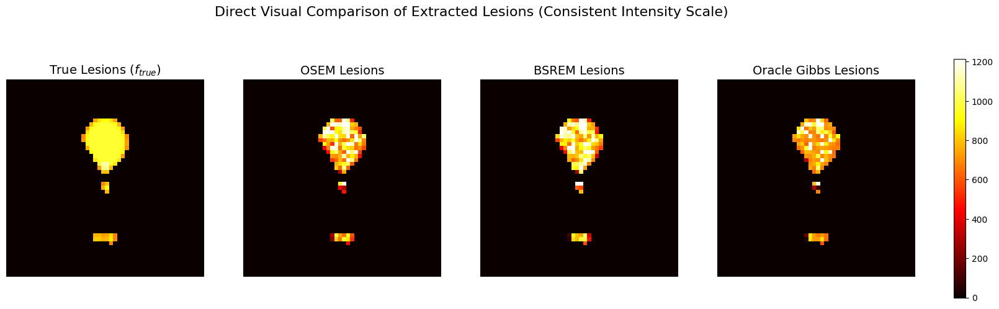

In [50]:
def visualize_algorithm_rois(f_true, f_osem, f_bsrem, f_oracle, size=50):
    """
    Generates a localized visual comparison of the extracted lesions across all algorithms.

    By applying the elliptical spatial mask and an intensity threshold, this function
    isolates the diagnostic targets from the background brain and skull. It uses a
    consistent color scale (vmax/vmin) to ensure a fair visual assessment of contrast
    recovery and noise levels.

    Args:
        f_true (numpy.ndarray): Ground truth phantom.
        f_osem (numpy.ndarray): OSEM reconstruction.
        f_bsrem (numpy.ndarray): BSREM reconstruction.
        f_oracle (numpy.ndarray): Oracle Gibbs reconstruction.
        size (int): Spatial dimension of the image (B_SQRT). Defaults to 50.
    """
    # 1. Reshape 1D vectors into 2D spatial matrices
    f_t_2d = f_true.reshape((size, size))
    f_o_2d = f_osem.reshape((size, size))
    f_b_2d = f_bsrem.reshape((size, size))
    f_or_2d = f_oracle.reshape((size, size))

    # 2. Define the exact elliptical spatial mask (consistent with ROI metrics calculation)
    y, x = np.ogrid[:size, :size]
    center_x, center_y = size / 2, size / 2
    radius_x = size * 0.25
    radius_y = size * 0.35
    spatial_mask = (((x - center_x) / radius_x)**2 + ((y - center_y) / radius_y)**2) <= 1

    # Identify brain background tissue to set the lesion isolation threshold
    brain_bg = np.median(f_t_2d[spatial_mask])
    lesion_mask = spatial_mask & (f_t_2d > brain_bg * 1.05)

    # 3. Mask Application Helper: Sets all non-lesion voxels to zero (black)
    def apply_mask(img):
        masked_img = np.zeros_like(img)
        masked_img[lesion_mask] = img[lesion_mask]
        return masked_img

    img_t = apply_mask(f_t_2d)
    img_o = apply_mask(f_o_2d)
    img_b = apply_mask(f_b_2d)
    img_or = apply_mask(f_or_2d)

    # 4. Define a consistent intensity scale (Crucial for objective comparison)
    # Reference the maximum intensity of the true lesion
    vmax = np.max(f_t_2d[lesion_mask]) * 1.1
    vmin = 0

    # 5. Rendering the comparison panel
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    im_t = axes[0].imshow(img_t, cmap='hot', vmin=vmin, vmax=vmax)
    axes[0].set_title('True Lesions ($f_{true}$)', fontsize=14)

    im_o = axes[1].imshow(img_o, cmap='hot', vmin=vmin, vmax=vmax)
    axes[1].set_title('OSEM Lesions', fontsize=14)

    im_b = axes[2].imshow(img_b, cmap='hot', vmin=vmin, vmax=vmax)
    axes[2].set_title('BSREM Lesions', fontsize=14)

    im_or = axes[3].imshow(img_or, cmap='hot', vmin=vmin, vmax=vmax)
    axes[3].set_title('Oracle Gibbs Lesions', fontsize=14)

    # Clean up visualization by removing coordinate axes
    for ax in axes:
        ax.axis('off')

    # Add a unified colorbar to the right of the subplots
    fig.colorbar(im_t, ax=axes.ravel().tolist(), fraction=0.015, pad=0.04)

    plt.suptitle("Direct Visual Comparison of Extracted Lesions (Consistent Intensity Scale)", fontsize=16, y=1.05)

    # Save high-resolution output for the Results section of the thesis
    plt.savefig("lesion_comparison.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- Execution Example ---
# This is typically called at the end of a scenario simulation loop:
visualize_algorithm_rois(pet.f_true, f_osem, f_bsrem, f_oracle, size=pet.B_SQRT)